In [1]:
# ============================================================
# CELL 1 — INSTALL REQUIRED PACKAGES
# Khulna Division Urban Center Mapping
# Cloud / Online Processing Version
# ============================================================

!pip -q install geemap geopandas pyogrio osmnx rasterio rioxarray \
    shapely folium mapclassify

print("✅ Packages installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 68.8 MB/s eta 0:00:00
✅ Packages installed successfully.


In [2]:
# ============================================================
# CELL 2 — DIRECT ADMIN-1 SHAPEFILE UPLOAD FROM LOCAL PC
# No ZIP needed
# ============================================================

from google.colab import files
import os
import glob
import shutil

# Folder
UPLOAD_DIR = "/content/admin1"
os.makedirs(UPLOAD_DIR, exist_ok=True)

print("Select ALL shapefile components together:")
print("Required: .shp  .shx  .dbf  .prj")
print("Optional: .cpg")

# Opens local file chooser
uploaded = files.upload()

# Move uploaded files into one folder
for filename in uploaded.keys():
    src = f"/content/{filename}"
    dst = os.path.join(UPLOAD_DIR, os.path.basename(filename))

    if os.path.exists(src):
        shutil.move(src, dst)

print("\nUploaded files:")
for f in os.listdir(UPLOAD_DIR):
    print(" -", f)

# Find .shp
shp_files = glob.glob(os.path.join(UPLOAD_DIR, "*.shp"))

if len(shp_files) == 0:
    raise FileNotFoundError(
        "❌ .shp file পাওয়া যায়নি. .shp, .shx, .dbf, .prj একসাথে select করো."
    )

ADMIN1_SHP = shp_files[0]

print("\n✅ Admin-1 shapefile ready:")
print(ADMIN1_SHP)

Select ALL shapefile components together:
Required: .shp  .shx  .dbf  .prj
Optional: .cpg


Saving bgd_admin1.cpg to bgd_admin1.cpg
Saving bgd_admin1.dbf to bgd_admin1.dbf
Saving bgd_admin1.prj to bgd_admin1.prj
Saving bgd_admin1.shp to bgd_admin1.shp
Saving bgd_admin1.shx to bgd_admin1.shx

Uploaded files:
 - bgd_admin1.shp
 - bgd_admin1.prj
 - bgd_admin1.dbf
 - bgd_admin1.cpg
 - bgd_admin1.shx

✅ Admin-1 shapefile ready:
/content/admin1/bgd_admin1.shp


In [3]:
# ============================================================
# CELL 3 — READ & INSPECT BANGLADESH ADMIN-1 SHAPEFILE
# ============================================================

import geopandas as gpd
import os

# Read Admin-1 shapefile
admin1 = gpd.read_file(ADMIN1_SHP)

print("=" * 70)
print("BANGLADESH ADMIN-1 SHAPEFILE INFORMATION")
print("=" * 70)

print("\nTotal features :", len(admin1))
print("CRS            :", admin1.crs)

print("\nColumns:")
print(list(admin1.columns))

print("\n" + "=" * 70)
print("ATTRIBUTE PREVIEW")
print("=" * 70)

# Show attributes without geometry
display(admin1.drop(columns="geometry").head(10))

print("\n" + "=" * 70)
print("POSSIBLE DIVISION NAME VALUES")
print("=" * 70)

# Print unique values from text columns
for col in admin1.columns:
    if col != "geometry" and admin1[col].dtype == "object":
        vals = admin1[col].dropna().astype(str).unique()

        if len(vals) <= 20:
            print(f"\n{col}:")
            print(vals)

print("\n" + "=" * 70)
print("BOUNDING BOX OF FULL DATASET")
print("=" * 70)

print(admin1.total_bounds)

print("\n✅ Admin-1 shapefile loaded successfully.")

BANGLADESH ADMIN-1 SHAPEFILE INFORMATION

Total features : 8
CRS            : EPSG:4326

Columns:
['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry']

ATTRIBUTE PREVIEW


,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,adm0_name,adm0_name1,adm0_name2,adm0_name3,adm0_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,adm1_ref_n,center_lat,center_lon
0,Barishal,None,None,None,BD10,Bangladesh,None,None,None,BD,...,NaT,12693.470554,v03,en,None,None,None,None,22.392843,90.406395
1,Chattogram,None,None,None,BD20,Bangladesh,None,None,None,BD,...,NaT,32833.077336,v03,en,None,None,None,None,22.701308,91.705861
2,Dhaka,None,None,None,BD30,Bangladesh,None,None,None,BD,...,NaT,20426.531733,v03,en,None,None,None,None,23.839021,90.242159
3,Khulna,None,None,None,BD40,Bangladesh,None,None,None,BD,...,NaT,22584.724276,v03,en,None,None,None,None,22.837718,89.304779
4,Mymensingh,None,None,None,BD45,Bangladesh,None,None,None,BD,...,NaT,10512.774130,v03,en,None,None,None,None,24.847830,90.381745
5,Rajshahi,None,None,None,BD50,Bangladesh,None,None,None,BD,...,NaT,18255.461893,v03,en,None,None,None,None,24.589338,89.046363
6,Rangpur,None,None,None,BD55,Bangladesh,None,None,None,BD,...,NaT,16282.752692,v03,en,None,None,None,None,25.780421,89.054095
7,Sylhet,None,None,None,BD60,Bangladesh,None,None,None,BD,...,NaT,12373.311774,v03,en,None,None,None,None,24.715289,91.664713



POSSIBLE DIVISION NAME VALUES

adm1_name:
['Barishal' 'Chattogram' 'Dhaka' 'Khulna' 'Mymensingh' 'Rajshahi'
 'Rangpur' 'Sylhet']

adm1_name1:
[]

adm1_name2:
[]

adm1_name3:
[]

adm1_pcode:
['BD10' 'BD20' 'BD30' 'BD40' 'BD45' 'BD50' 'BD55' 'BD60']

adm0_name:
['Bangladesh']

adm0_name1:
[]

adm0_name2:
[]

adm0_name3:
[]

adm0_pcode:
['BD']

version:
['v03']

lang:
['en']

lang1:
[]

lang2:
[]

lang3:
[]

adm1_ref_n:
[]

BOUNDING BOX OF FULL DATASET
[88.00816912 20.59060825 92.68005782 26.63454827]

✅ Admin-1 shapefile loaded successfully.


EXTRACTING KHULNA DIVISION

✅ Khulna Division found.

Name       : Khulna
PCode      : BD40
Area attr. : 22584.72 sq.km
CRS        : EPSG:4326

Bounding Box:
West  : 88.55672385600019
South : 21.64549565600015
East  : 89.96720462100018
North : 24.219466142999977

Center coordinates:
Latitude  : 22.83771757
Longitude : 89.3047787

✅ Khulna boundary saved:
/content/khulna_boundary/Khulna_Division.shp


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_on created as String field, though DateTime requested.
  ogr_write(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_to created as String field, though DateTime requested.
  ogr_write(



✅ Khulna Division extraction and boundary check complete.


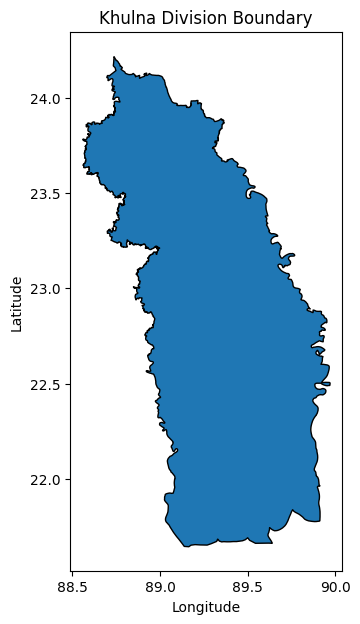

In [4]:
# ============================================================
# CELL 4 — EXTRACT KHULNA DIVISION
# ============================================================

import geopandas as gpd
import os

print("=" * 70)
print("EXTRACTING KHULNA DIVISION")
print("=" * 70)

# Extract Khulna Division
khulna = admin1[
    admin1["adm1_name"].astype(str).str.strip().str.lower() == "khulna"
].copy()

# Safety check
if len(khulna) == 0:
    raise ValueError("❌ Khulna Division not found in adm1_name column.")

if len(khulna) > 1:
    print("⚠️ More than one Khulna feature found:", len(khulna))

print("\n✅ Khulna Division found.")

# Basic information
print("\nName       :", khulna.iloc[0]["adm1_name"])
print("PCode      :", khulna.iloc[0]["adm1_pcode"])
print("Area attr. :", round(float(khulna.iloc[0]["area_sqkm"]), 2), "sq.km")
print("CRS        :", khulna.crs)

# Bounding box
xmin, ymin, xmax, ymax = khulna.total_bounds

print("\nBounding Box:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# Center coordinates from attribute
print("\nCenter coordinates:")
print("Latitude  :", khulna.iloc[0]["center_lat"])
print("Longitude :", khulna.iloc[0]["center_lon"])

# Save extracted Khulna boundary
KHULNA_DIR = "/content/khulna_boundary"
os.makedirs(KHULNA_DIR, exist_ok=True)

KHULNA_SHP = os.path.join(KHULNA_DIR, "Khulna_Division.shp")

khulna.to_file(KHULNA_SHP)

print("\n✅ Khulna boundary saved:")
print(KHULNA_SHP)

# ------------------------------------------------------------
# Quick visual check
# ------------------------------------------------------------

ax = khulna.plot(
    figsize=(7, 7),
    edgecolor="black"
)

ax.set_title("Khulna Division Boundary")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

print("\n✅ Khulna Division extraction and boundary check complete.")

In [6]:
# ============================================================
# CELL 5 — GOOGLE EARTH ENGINE AUTH + KHULNA ROI
# FIXED VERSION
# ============================================================

import ee
import geemap
import json
import geopandas as gpd

print("=" * 70)
print("GOOGLE EARTH ENGINE SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Initialize Earth Engine
# ------------------------------------------------------------

try:
    ee.Initialize(project="solid-garden-458417-t4")
    print("\n✅ Earth Engine initialized successfully.")

except Exception:
    print("\nEarth Engine authentication required...")
    ee.Authenticate()
    ee.Initialize(project="solid-garden-458417-t4")
    print("\n✅ Earth Engine authenticated and initialized.")

# ------------------------------------------------------------
# 2. Prepare Khulna geometry only
# ------------------------------------------------------------

khulna_wgs84 = khulna.to_crs("EPSG:4326")

# Merge into one geometry
khulna_geom = khulna_wgs84.geometry.unary_union

# Convert ONLY geometry to GeoJSON dictionary
khulna_geojson = khulna_geom.__geo_interface__

# Convert to Earth Engine geometry
roi = ee.Geometry(khulna_geojson)

print("\n✅ Khulna boundary converted to Earth Engine ROI.")

# ------------------------------------------------------------
# 3. Earth Engine area check
# ------------------------------------------------------------

ee_area_m2 = roi.area(maxError=1).getInfo()
ee_area_km2 = ee_area_m2 / 1e6

shp_area = float(khulna.iloc[0]["area_sqkm"])

print("\n" + "=" * 70)
print("KHULNA ROI CHECK")
print("=" * 70)

print("Shapefile area attribute :", round(shp_area, 2), "sq.km")
print("Earth Engine ROI area    :", round(ee_area_km2, 2), "sq.km")
print("Area difference          :", round(abs(ee_area_km2 - shp_area), 2), "sq.km")

# ------------------------------------------------------------
# 4. Bounding box check
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = khulna_wgs84.total_bounds

print("\nBounding Box:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 5. Quick SRTM test
# ------------------------------------------------------------

srtm = ee.Image("USGS/SRTMGL1_003").clip(roi)

test_stats = srtm.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=1000,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

print("\nSRTM test:")
print(test_stats)

print("\n✅ Earth Engine setup and Khulna ROI verification complete.")

GOOGLE EARTH ENGINE SETUP

✅ Earth Engine initialized successfully.

✅ Khulna boundary converted to Earth Engine ROI.


/tmp/ipykernel_1142/2862343746.py:36: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  khulna_geom = khulna_wgs84.geometry.unary_union



KHULNA ROI CHECK
Shapefile area attribute : 22584.72 sq.km
Earth Engine ROI area    : 22640.38 sq.km
Area difference          : 55.65 sq.km

Bounding Box:
West  : 88.55672385600019
South : 21.64549565600015
East  : 89.96720462100018
North : 24.219466142999977

SRTM test:
{'elevation_max': 22, 'elevation_min': -3}

✅ Earth Engine setup and Khulna ROI verification complete.


In [7]:
# ============================================================
# CELL 6 — SENTINEL-2 COLLECTION CHECK
# KHULNA DIVISION | JAN–MAR 2025
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 COLLECTION CHECK — KHULNA DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Date range
# ------------------------------------------------------------

START_DATE = "2025-01-01"
END_DATE   = "2025-04-01"   # exclusive, so includes up to 31 March 2025

# ------------------------------------------------------------
# 2. Sentinel-2 Surface Reflectance Harmonized
# ------------------------------------------------------------

s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 30))
)

# ------------------------------------------------------------
# 3. Scene count
# ------------------------------------------------------------

scene_count = s2.size().getInfo()

print("\nDate range:")
print("Start :", START_DATE)
print("End   :", "2025-03-31")

print("\nCloud filter:")
print("CLOUDY_PIXEL_PERCENTAGE <= 30%")

print("\nTotal Sentinel-2 scenes :", scene_count)

# ------------------------------------------------------------
# 4. Unique acquisition dates
# ------------------------------------------------------------

date_list = (
    s2.aggregate_array("system:time_start")
    .map(lambda t: ee.Date(t).format("YYYY-MM-dd"))
    .distinct()
    .sort()
    .getInfo()
)

print("Unique acquisition dates :", len(date_list))

print("\nFirst 10 dates:")
for d in date_list[:10]:
    print(" -", d)

print("\nLast 10 dates:")
for d in date_list[-10:]:
    print(" -", d)

# ------------------------------------------------------------
# 5. Sentinel-2 tile IDs
# ------------------------------------------------------------

tile_ids = (
    s2.aggregate_array("MGRS_TILE")
    .distinct()
    .sort()
    .getInfo()
)

print("\nUnique MGRS tiles :", len(tile_ids))
print(tile_ids)

# ------------------------------------------------------------
# 6. Quick first-image check
# ------------------------------------------------------------

if scene_count > 0:
    first_img = ee.Image(s2.first())

    first_date = ee.Date(
        first_img.get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()

    first_cloud = first_img.get("CLOUDY_PIXEL_PERCENTAGE").getInfo()
    first_tile = first_img.get("MGRS_TILE").getInfo()

    print("\nFirst image:")
    print("Date       :", first_date)
    print("MGRS tile  :", first_tile)
    print("Cloud (%)  :", round(first_cloud, 2))

else:
    raise ValueError("❌ No Sentinel-2 scenes found for this period.")

print("\n✅ Sentinel-2 collection check complete.")

SENTINEL-2 COLLECTION CHECK — KHULNA DIVISION

Date range:
Start : 2025-01-01
End   : 2025-03-31

Cloud filter:
CLOUDY_PIXEL_PERCENTAGE <= 30%

Total Sentinel-2 scenes : 206
Unique acquisition dates : 34

First 10 dates:
 - 2025-01-03
 - 2025-01-05
 - 2025-01-08
 - 2025-01-10
 - 2025-01-13
 - 2025-01-15
 - 2025-01-18
 - 2025-01-20
 - 2025-01-23
 - 2025-01-25

Last 10 dates:
 - 2025-03-09
 - 2025-03-11
 - 2025-03-14
 - 2025-03-16
 - 2025-03-19
 - 2025-03-21
 - 2025-03-24
 - 2025-03-26
 - 2025-03-29
 - 2025-03-31

Unique MGRS tiles : 9
['45QXE', '45QXF', '45QXG', '45QYD', '45QYE', '45QYF', '45QYG', '45QZE', '45QZF']

First image:
Date       : 2025-01-03
MGRS tile  : 45QXE
Cloud (%)  : 15.61

✅ Sentinel-2 collection check complete.


In [8]:
# ============================================================
# CELL 7 — CLOUD MASK + SENTINEL-2 MEDIAN COMPOSITE
# KHULNA DIVISION
# ============================================================

import ee

def mask_s2_clouds(img):
    """
    Cloud masking using SCL band.

    Removes:
    3  = Cloud shadow
    8  = Cloud medium probability
    9  = Cloud high probability
    10 = Cirrus
    11 = Snow / ice
    """

    scl = img.select("SCL")

    mask = (
        scl.neq(3)
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    # Keep required spectral bands
    spectral = img.select(
        ["B2", "B3", "B4", "B8", "B11", "B12"]
    )

    # Convert Sentinel-2 reflectance to 0–1
    return (
        spectral
        .updateMask(mask)
        .divide(10000)
        .copyProperties(img, ["system:time_start"])
    )


# ------------------------------------------------------------
# Apply cloud mask
# ------------------------------------------------------------

s2_clean = s2.map(mask_s2_clouds)


# ------------------------------------------------------------
# Create median composite
# ------------------------------------------------------------

s2_composite = (
    s2_clean
    .median()
    .clip(roi)
)


# ------------------------------------------------------------
# Check output
# ------------------------------------------------------------

print("=" * 70)
print("SENTINEL-2 CLOUD MASK + COMPOSITE — KHULNA")
print("=" * 70)

print("\n✅ Cloud masking completed")
print("✅ Median composite created")

print("\nComposite bands:")
print(s2_composite.bandNames().getInfo())

print("\nBand meaning:")
print("B2  = Blue")
print("B3  = Green")
print("B4  = Red")
print("B8  = NIR")
print("B11 = SWIR1")
print("B12 = SWIR2")

print("\nExpected bands:")
print("['B2', 'B3', 'B4', 'B8', 'B11', 'B12']")

print("\n✅ Sentinel-2 composite ready for index calculation.")

SENTINEL-2 CLOUD MASK + COMPOSITE — KHULNA

✅ Cloud masking completed
✅ Median composite created

Composite bands:
['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

Band meaning:
B2  = Blue
B3  = Green
B4  = Red
B8  = NIR
B11 = SWIR1
B12 = SWIR2

Expected bands:
['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

✅ Sentinel-2 composite ready for index calculation.


In [9]:
# ============================================================
# CELL 8 — SENTINEL-2 SPECTRAL INDICES
# KHULNA DIVISION
# NDVI, NDBI, MNDWI, BSI
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 INDEX CALCULATION — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. NDVI
# NDVI = (NIR - Red) / (NIR + Red)
# ------------------------------------------------------------

ndvi = s2_composite.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")


# ------------------------------------------------------------
# 2. NDBI
# NDBI = (SWIR1 - NIR) / (SWIR1 + NIR)
# ------------------------------------------------------------

ndbi = s2_composite.normalizedDifference(
    ["B11", "B8"]
).rename("NDBI")


# ------------------------------------------------------------
# 3. MNDWI
# MNDWI = (Green - SWIR1) / (Green + SWIR1)
# ------------------------------------------------------------

mndwi = s2_composite.normalizedDifference(
    ["B3", "B11"]
).rename("MNDWI")


# ------------------------------------------------------------
# 4. BSI — Bare Soil Index
#
# BSI =
# ((SWIR1 + Red) - (NIR + Blue))
# --------------------------------
# ((SWIR1 + Red) + (NIR + Blue))
# ------------------------------------------------------------

bsi = s2_composite.expression(
    """
    ((SWIR1 + RED) - (NIR + BLUE)) /
    ((SWIR1 + RED) + (NIR + BLUE))
    """,
    {
        "SWIR1": s2_composite.select("B11"),
        "RED":   s2_composite.select("B4"),
        "NIR":   s2_composite.select("B8"),
        "BLUE":  s2_composite.select("B2")
    }
).rename("BSI")


# ------------------------------------------------------------
# 5. Combine indices
# ------------------------------------------------------------

s2_indices = (
    ndvi
    .addBands(ndbi)
    .addBands(mndwi)
    .addBands(bsi)
    .clip(roi)
)

print("\n✅ NDVI calculated")
print("✅ NDBI calculated")
print("✅ MNDWI calculated")
print("✅ BSI calculated")

print("\nIndex bands:")
print(s2_indices.bandNames().getInfo())


# ------------------------------------------------------------
# 6. Basic percentile statistics
# ------------------------------------------------------------

stats = s2_indices.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("INDEX PERCENTILE STATISTICS")
print("=" * 70)

for key in sorted(stats.keys()):
    value = stats[key]

    if value is not None:
        print(f"{key:15s}: {value:.4f}")
    else:
        print(f"{key:15s}: None")


# ------------------------------------------------------------
# 7. Final check
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INDEX INTERPRETATION")
print("=" * 70)

print("High NDVI   -> vegetation")
print("High NDBI   -> built-up tendency")
print("High MNDWI  -> water tendency")
print("High BSI    -> bare / exposed soil tendency")

print("\n✅ Sentinel-2 indices ready for built-up scoring.")

SENTINEL-2 INDEX CALCULATION — KHULNA

✅ NDVI calculated
✅ NDBI calculated
✅ MNDWI calculated
✅ BSI calculated

Index bands:
['NDVI', 'NDBI', 'MNDWI', 'BSI']

INDEX PERCENTILE STATISTICS
BSI_p1         : -0.3866
BSI_p25        : -0.2383
BSI_p5         : -0.3476
BSI_p50        : -0.1523
BSI_p75        : -0.0743
BSI_p95        : 0.0507
BSI_p99        : 0.1444
MNDWI_p1       : -0.5193
MNDWI_p25      : -0.4336
MNDWI_p5       : -0.4881
MNDWI_p50      : -0.3790
MNDWI_p75      : -0.2305
MNDWI_p95      : 0.7305
MNDWI_p99      : 0.7614
NDBI_p1        : -0.5663
NDBI_p25       : -0.3476
NDBI_p5        : -0.4647
NDBI_p50       : -0.2539
NDBI_p75       : -0.1524
NDBI_p95       : 0.0117
NDBI_p99       : 0.1133
NDVI_p1        : -0.4257
NDVI_p25       : 0.3946
NDVI_p5        : -0.3243
NDVI_p50       : 0.5977
NDVI_p75       : 0.7071
NDVI_p95       : 0.7772
NDVI_p99       : 0.8241

INDEX INTERPRETATION
High NDVI   -> vegetation
High NDBI   -> built-up tendency
High MNDWI  -> water tendency
High BSI    -

In [10]:
# ============================================================
# CELL 9 — BUILT-UP RAW SCORE
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP RAW SCORE — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Normalize each index from [-1, +1] to [0, 1]
# ------------------------------------------------------------

ndbi_n  = ndbi.add(1).divide(2).clamp(0, 1)
bsi_n   = bsi.add(1).divide(2).clamp(0, 1)
ndvi_n  = ndvi.add(1).divide(2).clamp(0, 1)
mndwi_n = mndwi.add(1).divide(2).clamp(0, 1)

# ------------------------------------------------------------
# 2. Inverse vegetation and water tendency
# ------------------------------------------------------------

inv_ndvi  = ee.Image(1).subtract(ndvi_n)
inv_mndwi = ee.Image(1).subtract(mndwi_n)

# ------------------------------------------------------------
# 3. Weighted built-up raw score
# ------------------------------------------------------------

builtup_raw = (
    ndbi_n.multiply(0.40)
    .add(bsi_n.multiply(0.25))
    .add(inv_ndvi.multiply(0.20))
    .add(inv_mndwi.multiply(0.15))
    .rename("Builtup_Raw")
)

# ------------------------------------------------------------
# 4. Water and dense vegetation masks
# Same thresholds as Dhaka workflow
# ------------------------------------------------------------

water_mask = mndwi.gt(0)

dense_veg_mask = ndvi.gt(0.45)

# Keep pixels that are NOT water and NOT dense vegetation
valid_builtup_mask = (
    water_mask.Not()
    .And(dense_veg_mask.Not())
)

builtup_raw_masked = (
    builtup_raw
    .updateMask(valid_builtup_mask)
    .clip(roi)
)

print("\n✅ Weighted built-up raw score created.")
print("✅ Water mask applied        : MNDWI > 0")
print("✅ Dense vegetation masked   : NDVI > 0.45")

# ------------------------------------------------------------
# 5. Percentile statistics of built-up raw score
# ------------------------------------------------------------

builtup_stats = builtup_raw_masked.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("BUILT-UP RAW SCORE PERCENTILES")
print("=" * 70)

for key in sorted(builtup_stats.keys()):
    val = builtup_stats[key]

    if val is not None:
        print(f"{key:20s}: {val:.4f}")
    else:
        print(f"{key:20s}: None")

# ------------------------------------------------------------
# 6. Mask coverage check
# ------------------------------------------------------------

mask_area = ee.Image.pixelArea().updateMask(
    valid_builtup_mask
).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).get("area")

mask_area_km2 = ee.Number(mask_area).divide(1e6).getInfo()

roi_area_km2 = ee_area_km2

mask_percent = (mask_area_km2 / roi_area_km2) * 100

print("\n" + "=" * 70)
print("VALID BUILT-UP SEARCH AREA")
print("=" * 70)

print("Valid non-water/non-dense-veg area :", round(mask_area_km2, 2), "sq.km")
print("Share of Khulna ROI                :", round(mask_percent, 2), "%")

print("\n✅ Built-up raw score ready.")

BUILT-UP RAW SCORE — KHULNA

✅ Weighted built-up raw score created.
✅ Water mask applied        : MNDWI > 0
✅ Dense vegetation masked   : NDVI > 0.45

BUILT-UP RAW SCORE PERCENTILES
Builtup_Raw_p1      : 0.3818
Builtup_Raw_p25     : 0.4639
Builtup_Raw_p5      : 0.4131
Builtup_Raw_p50     : 0.4912
Builtup_Raw_p75     : 0.5205
Builtup_Raw_p90     : 0.5459
Builtup_Raw_p95     : 0.5537
Builtup_Raw_p99     : 0.5693

VALID BUILT-UP SEARCH AREA
Valid non-water/non-dense-veg area : 2801.4 sq.km
Share of Khulna ROI                : 12.37 %

✅ Built-up raw score ready.


In [11]:
# ============================================================
# CELL 10 — NORMALIZE BUILT-UP SCORE TO 0–1
# KHULNA DIVISION
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP SCORE NORMALIZATION — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get percentile limits
# ------------------------------------------------------------

p5  = float(builtup_stats["Builtup_Raw_p5"])
p99 = float(builtup_stats["Builtup_Raw_p99"])

print("\nNormalization limits:")
print("P5  :", round(p5, 4))
print("P99 :", round(p99, 4))

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

builtup_score = (
    builtup_raw_masked
    .subtract(p5)
    .divide(p99 - p5)
    .clamp(0, 1)
    .rename("Builtup_Score")
)

print("\n✅ Built-up raw score normalized to 0–1.")

# ------------------------------------------------------------
# 3. Check normalized percentiles
# ------------------------------------------------------------

score_stats = builtup_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED BUILT-UP SCORE PERCENTILES")
print("=" * 70)

for key in sorted(score_stats.keys()):
    val = score_stats[key]

    if val is not None:
        print(f"{key:22s}: {val:.4f}")
    else:
        print(f"{key:22s}: None")

# ------------------------------------------------------------
# 4. Basic range check
# ------------------------------------------------------------

minmax = builtup_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print("Minimum :", round(minmax["Builtup_Score_min"], 4))
print("Maximum :", round(minmax["Builtup_Score_max"], 4))

print("\n✅ Built-up factor score ready.")

BUILT-UP SCORE NORMALIZATION — KHULNA

Normalization limits:
P5  : 0.4131
P99 : 0.5693

✅ Built-up raw score normalized to 0–1.

NORMALIZED BUILT-UP SCORE PERCENTILES
Builtup_Score_p1      : 0.0002
Builtup_Score_p25     : 0.3321
Builtup_Score_p5      : 0.0002
Builtup_Score_p50     : 0.4961
Builtup_Score_p75     : 0.6914
Builtup_Score_p90     : 0.8476
Builtup_Score_p95     : 0.9023
Builtup_Score_p99     : 0.9961

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ Built-up factor score ready.


In [13]:
# ============================================================
# CELL 11 — VIIRS NIGHTTIME LIGHT FOR KHULNA
# EXACT SAME METHOD AS DHAKA
# 2025 Jan–Mar Monthly Mean Composite
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHTTIME LIGHT — KHULNA DIVISION")
print("SAME METHOD AS DHAKA")
print("=" * 70)

# ------------------------------------------------------------
# 1. VIIRS monthly nighttime lights
# SAME DATASET AS DHAKA NOTEBOOK
# ------------------------------------------------------------

viirs = (
    ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMCFG")
    .filterBounds(roi)
    .filterDate("2025-01-01", "2025-04-01")
    .select("avg_rad")
)

# Check collection
viirs_count = viirs.size().getInfo()

print("\nVIIRS monthly images found:", viirs_count)

if viirs_count == 0:
    raise ValueError("❌ No VIIRS images found for this period.")

# ------------------------------------------------------------
# 2. Mean Jan–Mar 2025 nighttime light
# ------------------------------------------------------------

viirs_mean = (
    viirs
    .mean()
    .clip(roi)
    .rename("VIIRS_Mean_Radiance")
)

print("\n✅ VIIRS Jan–Mar 2025 mean composite created.")

# ------------------------------------------------------------
# 3. Statistics
# EXACT SAME STYLE AS DHAKA
# ------------------------------------------------------------

viirs_stats = viirs_mean.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 50, 95, 99]
    ).combine(
        reducer2=ee.Reducer.minMax(),
        sharedInputs=True
    ),
    geometry=roi,
    scale=500,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

print("\n" + "=" * 70)
print("KHULNA VIIRS STATISTICS")
print("=" * 70)

for key, value in viirs_stats.items():
    print(f"{key}: {value}")

print("\nBand:")
print(viirs_mean.bandNames().getInfo())

print("\n✅ VIIRS nighttime-light layer ready.")

VIIRS NIGHTTIME LIGHT — KHULNA DIVISION
SAME METHOD AS DHAKA

VIIRS monthly images found: 3

✅ VIIRS Jan–Mar 2025 mean composite created.

KHULNA VIIRS STATISTICS
VIIRS_Mean_Radiance_max: 80.15666961669922
VIIRS_Mean_Radiance_min: 0.20333334803581238
VIIRS_Mean_Radiance_p1: 0.3519352838955284
VIIRS_Mean_Radiance_p5: 0.3519352838955284
VIIRS_Mean_Radiance_p50: 0.6773367987627886
VIIRS_Mean_Radiance_p95: 1.708980890474348
VIIRS_Mean_Radiance_p99: 4.232038730399889

Band:
['VIIRS_Mean_Radiance']

✅ VIIRS nighttime-light layer ready.


In [14]:
# ============================================================
# CELL 12 — NORMALIZE VIIRS NIGHTTIME LIGHT SCORE
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHT LIGHT SCORE NORMALIZATION — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get P5 and P99 from Khulna statistics
# ------------------------------------------------------------

viirs_p5 = float(viirs_stats["VIIRS_Mean_Radiance_p5"])
viirs_p99 = float(viirs_stats["VIIRS_Mean_Radiance_p99"])

print("\nNormalization limits:")
print("P5  :", viirs_p5)
print("P99 :", viirs_p99)

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

night_light_score = (
    viirs_mean
    .subtract(viirs_p5)
    .divide(viirs_p99 - viirs_p5)
    .clamp(0, 1)
    .rename("Night_Light_Score")
)

print("\n✅ Night Light Score created.")

# ------------------------------------------------------------
# 3. Percentile check
# ------------------------------------------------------------

ntl_score_stats = night_light_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=500,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED NIGHT LIGHT SCORE PERCENTILES")
print("=" * 70)

for key in sorted(ntl_score_stats.keys()):
    val = ntl_score_stats[key]

    if val is not None:
        print(f"{key:25s}: {val:.4f}")
    else:
        print(f"{key:25s}: None")

# ------------------------------------------------------------
# 4. Final min-max check
# ------------------------------------------------------------

ntl_minmax = night_light_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=500,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print("Minimum :", round(ntl_minmax["Night_Light_Score_min"], 4))
print("Maximum :", round(ntl_minmax["Night_Light_Score_max"], 4))

print("\n✅ VIIRS Night Light factor ready.")

VIIRS NIGHT LIGHT SCORE NORMALIZATION — KHULNA

Normalization limits:
P5  : 0.3519352838955284
P99 : 4.232038730399889

✅ Night Light Score created.

NORMALIZED NIGHT LIGHT SCORE PERCENTILES
Night_Light_Score_p25    : 0.0002
Night_Light_Score_p50    : 0.0510
Night_Light_Score_p75    : 0.1051
Night_Light_Score_p90    : 0.2075
Night_Light_Score_p95    : 0.3397
Night_Light_Score_p99    : 0.9958

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ VIIRS Night Light factor ready.


In [16]:
# ============================================================
# CELL 13 — LOAD GHSL 2025 POPULATION CORRECTLY
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION 2025 — KHULNA DIVISION")
print("SAME METHOD AS DHAKA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select 2025 image directly using system:index
# ------------------------------------------------------------

population = (
    ee.ImageCollection("JRC/GHSL/P2023A/GHS_POP")
    .filter(ee.Filter.eq("system:index", "2025"))
    .first()
    .select("population_count")
    .clip(roi)
    .rename("Population")
)

# ------------------------------------------------------------
# 2. Population statistics over Khulna
# ------------------------------------------------------------

pop_stats = population.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ).combine(
        reducer2=ee.Reducer.minMax(),
        sharedInputs=True
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True
).getInfo()

print("\n✅ GHSL 2025 population loaded successfully.")

print("\n" + "=" * 70)
print("KHULNA POPULATION STATISTICS")
print("=" * 70)

for key, value in pop_stats.items():
    print(f"{key}: {value}")

print("\nBand:")
print(population.bandNames().getInfo())

print("\n✅ Population layer ready for scoring.")

GHSL POPULATION 2025 — KHULNA DIVISION
SAME METHOD AS DHAKA



✅ GHSL 2025 population loaded successfully.

KHULNA POPULATION STATISTICS
Population_max: 1846.8399658203125
Population_min: -200
Population_p1: -199.9999999999994
Population_p25: 0.3306770847534528
Population_p5: 0.3306770847534528
Population_p50: 0.3306770847534528
Population_p75: 0.3306770847534528
Population_p90: 19.758488270027684
Population_p95: 43.80958715442029
Population_p99: 115.92586664095512

Band:
['Population']

✅ Population layer ready for scoring.


In [17]:
# ============================================================
# CELL 14 — GHSL POPULATION SCORE
# KHULNA DIVISION
# LOG TRANSFORM + 0–1 NORMALIZATION
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION SCORE — KHULNA DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clean invalid negative population values
# ------------------------------------------------------------

population_clean = (
    population
    .where(population.lt(0), 0)
    .rename("Population_Clean")
)

print("\n✅ Negative/fill population values replaced with 0.")

# ------------------------------------------------------------
# 2. Log transform
# log(1 + population)
# ------------------------------------------------------------

population_log = (
    population_clean
    .add(1)
    .log()
    .rename("Population_Log")
)

print("✅ Log transformation completed.")

# ------------------------------------------------------------
# 3. Use raw-population P99 from Khulna
# Convert it to log-space
# ------------------------------------------------------------

pop_p99 = float(pop_stats["Population_p99"])
log_p99 = ee.Number(pop_p99).add(1).log().getInfo()

print("\nNormalization reference:")
print("Raw Population P99 :", round(pop_p99, 4))
print("Log Population P99 :", round(log_p99, 4))

# ------------------------------------------------------------
# 4. Normalize log population to 0–1
# ------------------------------------------------------------

population_score = (
    population_log
    .divide(log_p99)
    .clamp(0, 1)
    .rename("Population_Score")
)

print("\n✅ Population Score created.")

# ------------------------------------------------------------
# 5. Percentile check
# ------------------------------------------------------------

population_score_stats = population_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED POPULATION SCORE PERCENTILES")
print("=" * 70)

for key in sorted(population_score_stats.keys()):
    value = population_score_stats[key]

    if value is not None:
        print(f"{key:28s}: {value:.4f}")
    else:
        print(f"{key:28s}: None")

# ------------------------------------------------------------
# 6. Min-max check
# ------------------------------------------------------------

population_minmax = population_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print("Minimum :", round(population_minmax["Population_Score_min"], 4))
print("Maximum :", round(population_minmax["Population_Score_max"], 4))

print("\n✅ GHSL Population factor ready.")

GHSL POPULATION SCORE — KHULNA DIVISION

✅ Negative/fill population values replaced with 0.
✅ Log transformation completed.

Normalization reference:
Raw Population P99 : 115.9259
Log Population P99 : 4.7615

✅ Population Score created.

NORMALIZED POPULATION SCORE PERCENTILES
Population_Score_p25        : 0.0000
Population_Score_p50        : 0.0000
Population_Score_p75        : 0.0266
Population_Score_p90        : 0.6367
Population_Score_p95        : 0.7929
Population_Score_p99        : 1.0000

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ GHSL Population factor ready.


In [18]:
# ============================================================
# CELL 15 — LOAD KHULNA ROAD NETWORK FROM GRIP4
# SAME METHOD AS DHAKA
# Server-side only, no local download
# ============================================================

import ee

print("=" * 70)
print("GRIP4 ROAD NETWORK — KHULNA DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load GRIP4 South-East Asia roads
# ------------------------------------------------------------

roads_all = ee.FeatureCollection(
    "projects/sat-io/open-datasets/GRIP4/South-East-Asia"
)

# ------------------------------------------------------------
# 2. Keep only roads intersecting Khulna Division
# ------------------------------------------------------------

khulna_roads = roads_all.filterBounds(roi)

# ------------------------------------------------------------
# 3. Basic check
# ------------------------------------------------------------

road_count = khulna_roads.size().getInfo()

print("\n✅ GRIP4 road dataset connected")
print("Road features intersecting Khulna Division:", road_count)

# ------------------------------------------------------------
# 4. Inspect one road feature
# ------------------------------------------------------------

if road_count > 0:

    first_road = ee.Feature(khulna_roads.first())

    print("\nFirst road feature properties:")
    print(first_road.toDictionary().getInfo())

else:
    raise ValueError("❌ No GRIP4 road features found in Khulna ROI.")

print("\n✅ Khulna road network ready.")

GRIP4 ROAD NETWORK — KHULNA DIVISION

✅ GRIP4 road dataset connected
Road features intersecting Khulna Division: 13556

First road feature properties:
{'GP_RAV': 1, 'GP_RCY': 50, 'GP_REX': 1, 'GP_RRG': 18, 'GP_RSE': 1, 'GP_RSI': 51, 'GP_RSY': 2006, 'GP_RTP': 4, 'Shape_Leng': 0.0274821514886, 'gp_gripreg': 6}

✅ Khulna road network ready.


In [19]:
# ============================================================
# CELL 16 — CHECK GRIP4 ROAD CLASS DISTRIBUTION
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("GRIP4 ROAD CLASS DISTRIBUTION — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check GP_RTP values
# ------------------------------------------------------------

road_classes = (
    khulna_roads
    .aggregate_array("GP_RTP")
    .distinct()
    .sort()
    .getInfo()
)

print("\nUnique GP_RTP classes:")
print(road_classes)

# ------------------------------------------------------------
# 2. Count features by class
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROAD FEATURE COUNT BY GP_RTP CLASS")
print("=" * 70)

class_counts = {}

for road_class in road_classes:

    count = (
        khulna_roads
        .filter(ee.Filter.eq("GP_RTP", road_class))
        .size()
        .getInfo()
    )

    class_counts[road_class] = count

    print(f"GP_RTP {road_class} : {count}")

# ------------------------------------------------------------
# 3. Total check
# ------------------------------------------------------------

total_from_classes = sum(class_counts.values())

print("\n" + "=" * 70)
print("COUNT CHECK")
print("=" * 70)

print("Total roads from classes :", total_from_classes)
print("Original road count      :", road_count)

if total_from_classes == road_count:
    print("\n✅ Class counts match total road count.")
else:
    print("\n⚠️ Some features may have missing/null GP_RTP values.")

print("\n✅ GRIP4 road class check complete.")


GRIP4 ROAD CLASS DISTRIBUTION — KHULNA

Unique GP_RTP classes:
[1, 2, 3, 4, 5]

ROAD FEATURE COUNT BY GP_RTP CLASS
GP_RTP 1 : 202
GP_RTP 2 : 263
GP_RTP 3 : 1056
GP_RTP 4 : 11139
GP_RTP 5 : 896

COUNT CHECK
Total roads from classes : 13556
Original road count      : 13556

✅ Class counts match total road count.

✅ GRIP4 road class check complete.


In [20]:
# ============================================================
# CELL 17 — WEIGHTED ROAD DENSITY
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("WEIGHTED ROAD DENSITY — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Road class weights
# ------------------------------------------------------------

ROAD_WEIGHTS = {
    1: 1.00,
    2: 0.85,
    3: 0.70,
    4: 0.45,
    5: 0.25
}

print("\nRoad class weights:")
for road_class, weight in ROAD_WEIGHTS.items():
    print(f"GP_RTP {road_class} -> {weight}")

# ------------------------------------------------------------
# 2. Add weight property to every road feature
# ------------------------------------------------------------

def add_road_weight(feature):

    road_type = ee.Number(feature.get("GP_RTP"))

    weight = ee.Number(
        ee.Algorithms.If(
            road_type.eq(1), 1.00,
            ee.Algorithms.If(
                road_type.eq(2), 0.85,
                ee.Algorithms.If(
                    road_type.eq(3), 0.70,
                    ee.Algorithms.If(
                        road_type.eq(4), 0.45,
                        ee.Algorithms.If(
                            road_type.eq(5), 0.25,
                            0
                        )
                    )
                )
            )
        )
    )

    return feature.set("road_weight", weight)


weighted_roads = khulna_roads.map(add_road_weight)

print("\n✅ Road weights assigned.")

# ------------------------------------------------------------
# 3. Convert weighted roads to raster
# ------------------------------------------------------------

road_raster = (
    weighted_roads
    .reduceToImage(
        properties=["road_weight"],
        reducer=ee.Reducer.max()
    )
    .unmask(0)
    .clip(roi)
    .rename("Road_Weight")
)

print("✅ Weighted road raster created.")

# ------------------------------------------------------------
# 4. Create 1-km circular kernel
# ------------------------------------------------------------

road_kernel = ee.Kernel.circle(
    radius=1000,
    units="meters",
    normalize=False
)

# ------------------------------------------------------------
# 5. Calculate neighborhood weighted road density
# ------------------------------------------------------------

road_density = (
    road_raster
    .reduceNeighborhood(
        reducer=ee.Reducer.mean(),
        kernel=road_kernel,
        skipMasked=True
    )
    .clip(roi)
    .rename("Road_Density")
)

print("✅ 1-km weighted road density calculated.")

# ------------------------------------------------------------
# 6. Density statistics
# ------------------------------------------------------------

road_density_stats = road_density.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ).combine(
        reducer2=ee.Reducer.minMax(),
        sharedInputs=True
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("ROAD DENSITY STATISTICS")
print("=" * 70)

for key in sorted(road_density_stats.keys()):
    value = road_density_stats[key]

    if value is not None:
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: None")

print("\n✅ Weighted road density layer ready.")

WEIGHTED ROAD DENSITY — KHULNA

Road class weights:
GP_RTP 1 -> 1.0
GP_RTP 2 -> 0.85
GP_RTP 3 -> 0.7
GP_RTP 4 -> 0.45
GP_RTP 5 -> 0.25

✅ Road weights assigned.
✅ Weighted road raster created.
✅ 1-km weighted road density calculated.

ROAD DENSITY STATISTICS
Road_Density_max         : 0.345110
Road_Density_min         : 0.000000
Road_Density_p1          : 0.000011
Road_Density_p25         : 0.000011
Road_Density_p5          : 0.000011
Road_Density_p50         : 0.067434
Road_Density_p75         : 0.106461
Road_Density_p90         : 0.137692
Road_Density_p95         : 0.157270
Road_Density_p99         : 0.192322

✅ Weighted road density layer ready.


In [21]:
# ============================================================
# CELL 18 — NORMALIZE ROAD DENSITY SCORE
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("ROAD DENSITY SCORE NORMALIZATION — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get Khulna P99 road density
# ------------------------------------------------------------

road_p99 = float(
    road_density_stats["Road_Density_p99"]
)

print("\nNormalization reference:")
print("Road Density P99 :", round(road_p99, 6))

# ------------------------------------------------------------
# 2. Normalize to 0–1
# Values >= P99 become 1
# ------------------------------------------------------------

road_density_score = (
    road_density
    .divide(road_p99)
    .clamp(0, 1)
    .rename("Road_Density_Score")
)

print("\n✅ Road Density Score created.")

# ------------------------------------------------------------
# 3. Percentile check
# ------------------------------------------------------------

road_score_stats = road_density_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED ROAD DENSITY SCORE PERCENTILES")
print("=" * 70)

for key in sorted(road_score_stats.keys()):

    value = road_score_stats[key]

    if value is not None:
        print(f"{key:30s}: {value:.4f}")
    else:
        print(f"{key:30s}: None")

# ------------------------------------------------------------
# 4. Final min-max check
# ------------------------------------------------------------

road_score_minmax = road_density_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(road_score_minmax["Road_Density_Score_min"], 4)
)

print(
    "Maximum :",
    round(road_score_minmax["Road_Density_Score_max"], 4)
)

print("\n✅ Road Density factor ready.")

ROAD DENSITY SCORE NORMALIZATION — KHULNA

Normalization reference:
Road Density P99 : 0.192322

✅ Road Density Score created.

NORMALIZED ROAD DENSITY SCORE PERCENTILES
Road_Density_Score_p25        : 0.0001
Road_Density_Score_p50        : 0.3548
Road_Density_Score_p75        : 0.5516
Road_Density_Score_p90        : 0.7149
Road_Density_Score_p95        : 0.8166
Road_Density_Score_p99        : 1.0000

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ Road Density factor ready.


In [22]:
# ============================================================
# CELL 18 — ROAD DENSITY SCORE (0–1)
# KHULNA DIVISION
# EXACT SAME METHOD AS DHAKA
# Robust P5–P99 normalization
# ============================================================

import ee

print("=" * 70)
print("ROAD DENSITY SCORE — KHULNA")
print("SAME METHOD AS DHAKA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use Khulna-specific P5 and P99
# ------------------------------------------------------------

ROAD_P5 = float(
    road_density_stats["Road_Density_p5"]
)

ROAD_P99 = float(
    road_density_stats["Road_Density_p99"]
)

print("\nNormalization limits:")
print("P5  :", ROAD_P5)
print("P99 :", ROAD_P99)

# ------------------------------------------------------------
# 2. Robust P5–P99 normalization
# ------------------------------------------------------------

road_score = (
    road_density
    .subtract(ROAD_P5)
    .divide(ROAD_P99 - ROAD_P5)
    .clamp(0, 1)
    .rename("Road_Score")
    .clip(roi)
)

print("\n✅ Road Score created.")

# ------------------------------------------------------------
# 3. Check statistics
# ------------------------------------------------------------

road_score_stats = road_score.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("ROAD SCORE STATISTICS")
print("=" * 70)

for key, value in road_score_stats.items():
    print(f"{key}: {value}")

print("\nNormalization:")
print("P5  → Score 0")
print("P99 → Score 1")
print("Below P5  → 0")
print("Above P99 → 1")

print("\nBand:")
print(road_score.bandNames().getInfo())

print("\n✅ Road Score (0–1) ready.")


ROAD DENSITY SCORE — KHULNA
SAME METHOD AS DHAKA

Normalization limits:
P5  : 1.0820384340963875e-05
P99 : 0.19232219847333712

✅ Road Score created.

ROAD SCORE STATISTICS
Road_Score_max: 1
Road_Score_min: 0
Road_Score_p25: 5.311224086045847e-05
Road_Score_p5: 5.311224086045847e-05
Road_Score_p50: 0.3548088619949358
Road_Score_p75: 0.5516062749495417
Road_Score_p90: 0.7148760632560145
Road_Score_p95: 0.816624153393464
Road_Score_p99: 1

Normalization:
P5  → Score 0
P99 → Score 1
Below P5  → 0
Above P99 → 1

Band:
['Road_Score']

✅ Road Score (0–1) ready.


In [23]:
# ============================================================
# CELL 19 — TEST OVERTURE MAPS PLACES ACCESS
# Small Khulna City bbox only
# SAME METHOD AS DHAKA
# ============================================================

!pip -q install -U overturemaps

import os
import subprocess
import geopandas as gpd

print("=" * 70)
print("OVERTURE MAPS PLACES ACCESS TEST — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# Small test bbox around Khulna City
# west, south, east, north
# ------------------------------------------------------------

TEST_BBOX = "89.50,22.78,89.62,22.90"

TEST_FILE = "/content/overture_khulna_test.geojson"

# Remove previous file if it exists
if os.path.exists(TEST_FILE):
    os.remove(TEST_FILE)

print("\nTesting Overture Maps Places access...")
print("Test bbox:", TEST_BBOX)

# ------------------------------------------------------------
# Download Overture Places
# ------------------------------------------------------------

cmd = [
    "overturemaps",
    "download",
    "--bbox", TEST_BBOX,
    "-f", "geojson",
    "--type", "place",
    "-o", TEST_FILE
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)

if result.stdout:
    print("\nSTDOUT:")
    print(result.stdout[-1500:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-1500:])

# ------------------------------------------------------------
# Check output file
# ------------------------------------------------------------

if os.path.exists(TEST_FILE):

    size_mb = os.path.getsize(TEST_FILE) / (1024 * 1024)

    print("\n✅ Overture output file created")
    print("File size:", round(size_mb, 3), "MB")

    poi_test = gpd.read_file(TEST_FILE)

    print("Total place features:", len(poi_test))

    print("\nGeometry types:")
    print(poi_test.geom_type.value_counts())

    print("\nFirst columns:")
    print(poi_test.columns.tolist()[:30])

    print("\n✅ Overture Places access is working.")

else:
    print("\n❌ Overture output file was not created.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 13.6 MB/s eta 0:00:00
OVERTURE MAPS PLACES ACCESS TEST — KHULNA

Testing Overture Maps Places access...
Test bbox: 89.50,22.78,89.62,22.90

Return code: 0

STDOUT:
No data found for release 2026-08-19.0 in query bbox (89.5, 22.78, 89.62, 22.9).


❌ Overture output file was not created.


In [24]:
# ============================================================
# CELL 19B — RETRY OVERTURE PLACES ACCESS
# Larger Khulna urban-area bbox
# ============================================================

import os
import subprocess
import geopandas as gpd

print("=" * 70)
print("OVERTURE MAPS PLACES RETRY — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# Larger bbox around Khulna metropolitan / surrounding area
# west, south, east, north
# ------------------------------------------------------------

TEST_BBOX = "89.40,22.70,89.75,23.00"

TEST_FILE = "/content/overture_khulna_test.geojson"

# Remove old test file
if os.path.exists(TEST_FILE):
    os.remove(TEST_FILE)

# Remove possible state file too
state_file = TEST_FILE + ".state"

if os.path.exists(state_file):
    os.remove(state_file)

print("\nTest bbox:", TEST_BBOX)
print("Downloading Overture Places...")

# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

cmd = [
    "overturemaps",
    "download",
    "--bbox", TEST_BBOX,
    "-f", "geojson",
    "--type", "place",
    "-o", TEST_FILE
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)

if result.stdout:
    print("\nSTDOUT:")
    print(result.stdout[-2000:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-2000:])

# ------------------------------------------------------------
# Check downloaded file
# ------------------------------------------------------------

if os.path.exists(TEST_FILE):

    size_mb = os.path.getsize(TEST_FILE) / (1024 * 1024)

    print("\n✅ Overture output file created")
    print("File size:", round(size_mb, 3), "MB")

    poi_test = gpd.read_file(TEST_FILE)

    print("Total place features:", len(poi_test))

    print("\nGeometry types:")
    print(poi_test.geom_type.value_counts())

    print("\nColumns:")
    print(poi_test.columns.tolist())

    if "basic_category" in poi_test.columns:

        print("\nTop 20 basic categories:")

        print(
            poi_test["basic_category"]
            .fillna("UNKNOWN")
            .value_counts()
            .head(20)
        )

    print("\n✅ Overture Places access is working for Khulna.")

else:

    print("\n❌ Still no Overture file produced.")
    print("We will test the available release/access method next.")

OVERTURE MAPS PLACES RETRY — KHULNA

Test bbox: 89.40,22.70,89.75,23.00

Return code: 0

STDOUT:
No data found for release 2026-08-19.0 in query bbox (89.4, 22.7, 89.75, 23.0).


❌ Still no Overture file produced.
We will test the available release/access method next.


In [25]:
# ============================================================
# CELL 19C — DIRECT OVERTURE PLACES TEST VIA DUCKDB
# KHULNA
# Bypass Python CLI
# ============================================================

!pip -q install duckdb

import duckdb
import os
import geopandas as gpd

print("=" * 70)
print("OVERTURE PLACES — DIRECT DUCKDB TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Khulna test bbox
# ------------------------------------------------------------

xmin = 89.40
ymin = 22.70
xmax = 89.75
ymax = 23.00

OUT_FILE = "/content/khulna_overture_duckdb_test.geojson"

if os.path.exists(OUT_FILE):
    os.remove(OUT_FILE)

print("\nTest bbox:")
print("West :", xmin)
print("South:", ymin)
print("East :", xmax)
print("North:", ymax)

# ------------------------------------------------------------
# 2. Start DuckDB
# ------------------------------------------------------------

con = duckdb.connect()

# Install/load extensions
con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

print("\n✅ DuckDB spatial + httpfs ready.")

# ------------------------------------------------------------
# 3. Query official Overture S3 dataset
# ------------------------------------------------------------

query = f"""
COPY (
    SELECT
        id,
        names.primary AS name,
        basic_category,
        confidence,
        geometry
    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )
    WHERE
        bbox.xmin BETWEEN {xmin} AND {xmax}
        AND bbox.ymin BETWEEN {ymin} AND {ymax}
)
TO '{OUT_FILE}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places directly from S3...")

con.execute(query)

# ------------------------------------------------------------
# 4. Check result
# ------------------------------------------------------------

if os.path.exists(OUT_FILE):

    size_mb = os.path.getsize(OUT_FILE) / (1024 * 1024)

    print("\n✅ GeoJSON created")
    print("File size:", round(size_mb, 3), "MB")

    poi_test = gpd.read_file(OUT_FILE)

    print("Total place features:", len(poi_test))

    print("\nColumns:")
    print(poi_test.columns.tolist())

    if len(poi_test) > 0:

        print("\nTop 20 basic categories:")

        print(
            poi_test["basic_category"]
            .fillna("UNKNOWN")
            .value_counts()
            .head(20)
        )

        print("\nFirst 5 rows:")
        display(
            poi_test[
                ["name", "basic_category", "confidence"]
            ].head()
        )

        print("\n✅ Direct Overture access is working.")

    else:
        print("\n⚠️ Query ran successfully but returned 0 places.")

else:
    print("\n❌ GeoJSON was not created.")

OVERTURE PLACES — DIRECT DUCKDB TEST

Test bbox:
West : 89.4
South: 22.7
East : 89.75
North: 23.0

✅ DuckDB spatial + httpfs ready.

Querying Overture Places directly from S3...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


✅ GeoJSON created
File size: 1.259 MB
Total place features: 4641

Columns:
['id', 'name', 'basic_category', 'confidence', 'geometry']

Top 20 basic categories:
basic_category
UNKNOWN                           257
fashion_and_apparel_store         244
restaurant                        215
professional_service              183
college_university                172
electronics_store                 161
place_of_learning                 160
education                         138
historic_site                     130
travel_service                    120
hospital                          108
government_office                  98
event_or_party_service             94
shopping                           86
technical_service                  85
food_and_beverage_store            82
hardware_home_and_garden_store     79
social_or_community_service        74
corporate_or_business_office       68
high_school                        68
Name: count, dtype: int64

First 5 rows:


,name,basic_category,confidence
0,Baniakhali High School,high_school,0.876612
1,Kundu Fashion House,fashion_and_apparel_store,0.668444
2,Chulkati Kindergarden,preschool,0.637464
3,"উপজেলা নির্বাচন অফিসারের কার্যালয়, বাগেরহাট সদ...",None,0.819331
4,"হাকিমপুর গ্রাম-বাগেরহাট,Hakimpur Village-Bagerhat",community_and_government,0.693587



✅ Direct Overture access is working.


In [26]:
# ============================================================
# CELL 20 — CREATE 0.2° DOWNLOAD GRID
# KHULNA DIVISION
# SAME CHUNKING METHOD AS DHAKA
# ============================================================

import geopandas as gpd
import numpy as np
from shapely.geometry import box

print("=" * 70)
print("CREATE OVERTURE POI DOWNLOAD GRID — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Grid size
# ------------------------------------------------------------

GRID_SIZE = 0.2   # degrees

# ------------------------------------------------------------
# 2. Khulna bounds
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = khulna_wgs84.total_bounds

print("\nKhulna bounds:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 3. Create grid cells
# ------------------------------------------------------------

x_coords = np.arange(xmin, xmax, GRID_SIZE)
y_coords = np.arange(ymin, ymax, GRID_SIZE)

grid_cells = []

chunk_id = 1

for x in x_coords:
    for y in y_coords:

        cell = box(
            x,
            y,
            min(x + GRID_SIZE, xmax),
            min(y + GRID_SIZE, ymax)
        )

        grid_cells.append({
            "chunk_id": chunk_id,
            "geometry": cell
        })

        chunk_id += 1

grid = gpd.GeoDataFrame(
    grid_cells,
    crs="EPSG:4326"
)

print("\nTotal raw grid cells:", len(grid))

# ------------------------------------------------------------
# 4. Keep only cells intersecting Khulna
# ------------------------------------------------------------

khulna_union = khulna_wgs84.geometry.union_all()

grid_intersect = grid[
    grid.intersects(khulna_union)
].copy()

grid_intersect = grid_intersect.reset_index(drop=True)

# Reassign sequential chunk numbers
grid_intersect["chunk_no"] = range(1, len(grid_intersect) + 1)

print("Intersecting grid cells:", len(grid_intersect))

# ------------------------------------------------------------
# 5. Add bbox coordinates for each chunk
# ------------------------------------------------------------

grid_intersect["west"] = grid_intersect.geometry.bounds.minx
grid_intersect["south"] = grid_intersect.geometry.bounds.miny
grid_intersect["east"] = grid_intersect.geometry.bounds.maxx
grid_intersect["north"] = grid_intersect.geometry.bounds.maxy

print("\nFirst 10 intersecting chunks:")

display(
    grid_intersect[
        ["chunk_no", "west", "south", "east", "north"]
    ].head(10)
)

# ------------------------------------------------------------
# 6. Basic check
# ------------------------------------------------------------

print("\nGrid size :", GRID_SIZE, "degree")
print("Total intersecting chunks :", len(grid_intersect))

print("\n✅ Khulna POI download grid ready.")



CREATE OVERTURE POI DOWNLOAD GRID — KHULNA

Khulna bounds:
West  : 88.55672385600019
South : 21.64549565600015
East  : 89.96720462100018
North : 24.219466142999977

Total raw grid cells: 104
Intersecting grid cells: 71

First 10 intersecting chunks:


,chunk_no,west,south,east,north
0,1,88.556724,23.045496,88.756724,23.245496
1,2,88.556724,23.245496,88.756724,23.445496
2,3,88.556724,23.445496,88.756724,23.645496
3,4,88.556724,23.645496,88.756724,23.845496
4,5,88.556724,23.845496,88.756724,24.045496
5,6,88.556724,24.045496,88.756724,24.219466
6,7,88.756724,22.445496,88.956724,22.645496
7,8,88.756724,22.645496,88.956724,22.845496
8,9,88.756724,22.845496,88.956724,23.045496
9,10,88.756724,23.045496,88.956724,23.245496



Grid size : 0.2 degree
Total intersecting chunks : 71

✅ Khulna POI download grid ready.


In [27]:
# ============================================================
# CELL 21 — TEST ONE OVERTURE CHUNK
# Download -> Filter -> Clip to Khulna -> Delete raw file
# SAME URBAN POI CATEGORIES AS DHAKA
# ============================================================

import os
import duckdb
import geopandas as gpd

print("=" * 70)
print("SINGLE-CHUNK OVERTURE TEST — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Same urban-relevant categories used in Dhaka notebook
# ------------------------------------------------------------

URBAN_POI_CATEGORIES = {

    # Shopping / commercial
    "shopping",
    "shopping_mall",
    "fashion_and_apparel_store",
    "electronics_store",
    "hardware_home_and_garden_store",
    "food_and_beverage_store",
    "warehouse_club_store",
    "books_music_and_video_store",
    "personal_care_and_beauty_store",
    "specialty_store",
    "farmers_market",

    # Food / restaurants
    "restaurant",
    "fast_food_restaurant",
    "casual_eatery",
    "cafe",
    "coffee_shop",
    "food_service",

    # Education
    "educational_service",
    "education",
    "place_of_learning",
    "college_university",
    "specialty_school",
    "high_school",
    "middle_school",
    "elementary_school",
    "preschool",
    "research_institute",

    # Health / medical
    "hospital",
    "health_care",
    "medical_service",
    "dental_clinic",
    "pharmacy_and_drug_store",
    "diagnostics_imaging_or_lab_service",
    "specialized_health_care",
    "specialized_medical_facility",
    "primary_care_or_general_clinic",
    "pediatric_clinic",
    "vision_or_eye_care_clinic",

    # Finance
    "bank_or_credit_union",
    "financial_service",

    # Offices / urban services
    "corporate_or_business_office",
    "government_office",
    "professional_service",
    "technical_service",
    "b2b_office_and_professional_service",

    # Accommodation
    "hotel",
    "lodging",

    # Transport-related
    "public_transit_facility_or_service"
}

print("Allowed urban categories:", len(URBAN_POI_CATEGORIES))

# ------------------------------------------------------------
# 2. Select one test chunk
# Use middle-ish chunk
# ------------------------------------------------------------

TEST_CHUNK_NO = 25

test_row = grid_intersect[
    grid_intersect["chunk_no"] == TEST_CHUNK_NO
].iloc[0]

minx, miny, maxx, maxy = test_row.geometry.bounds

print("\nTesting chunk:", TEST_CHUNK_NO)
print(
    "BBox:",
    f"{minx:.6f}, {miny:.6f}, {maxx:.6f}, {maxy:.6f}"
)

# ------------------------------------------------------------
# 3. Output file
# ------------------------------------------------------------

raw_file = f"/content/khulna_chunk_{TEST_CHUNK_NO}_raw.geojson"

if os.path.exists(raw_file):
    os.remove(raw_file)

# ------------------------------------------------------------
# 4. Direct Overture query via DuckDB
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

query = f"""
COPY (
    SELECT
        id,
        basic_category,
        confidence,
        geometry
    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )
    WHERE
        bbox.xmin <= {maxx}
        AND bbox.xmax >= {minx}
        AND bbox.ymin <= {maxy}
        AND bbox.ymax >= {miny}
)
TO '{raw_file}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places...")

con.execute(query)

# ------------------------------------------------------------
# 5. Read downloaded/query result
# ------------------------------------------------------------

poi_chunk = gpd.read_file(raw_file)

raw_count = len(poi_chunk)

print("\nRaw POIs:", raw_count)

# ------------------------------------------------------------
# 6. Keep urban categories only
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    poi_chunk["basic_category"].isin(
        URBAN_POI_CATEGORIES
    )
].copy()

urban_count = len(poi_chunk)

print("After category filter:", urban_count)

# ------------------------------------------------------------
# 7. Keep only POIs inside actual Khulna Division
# ------------------------------------------------------------

poi_chunk = gpd.sjoin(
    poi_chunk,
    khulna_wgs84[["geometry"]],
    predicate="within",
    how="inner"
).drop(
    columns=["index_right"],
    errors="ignore"
)

inside_count = len(poi_chunk)

print("Inside Khulna boundary:", inside_count)

# ------------------------------------------------------------
# 8. Keep lightweight fields
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    [
        "id",
        "basic_category",
        "confidence",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 9. File size + cleanup
# ------------------------------------------------------------

raw_size_mb = os.path.getsize(raw_file) / (1024 * 1024)

print("\nRaw file size:", round(raw_size_mb, 3), "MB")

os.remove(raw_file)

print("✅ Raw chunk file deleted")

# ------------------------------------------------------------
# 10. Final test summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SINGLE-CHUNK TEST SUMMARY")
print("=" * 70)

print("Raw POIs            :", raw_count)
print("Urban category POIs :", urban_count)
print("Inside Khulna       :", inside_count)

if raw_count > 0:
    print(
        "Urban POIs retained :",
        round((urban_count / raw_count) * 100, 2),
        "%"
    )

print("\nTop 15 categories:")

print(
    poi_chunk["basic_category"]
    .value_counts()
    .head(15)
)

print("\nGeometry types:")
print(poi_chunk.geom_type.value_counts())

print("\n✅ Single-chunk test completed successfully.")

SINGLE-CHUNK OVERTURE TEST — KHULNA
Allowed urban categories: 48

Testing chunk: 25
BBox: 88.956724, 23.445496, 89.156724, 23.645496

Querying Overture Places...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Raw POIs: 109
After category filter: 50
Inside Khulna boundary: 50

Raw file size: 0.025 MB
✅ Raw chunk file deleted

SINGLE-CHUNK TEST SUMMARY
Raw POIs            : 109
Urban category POIs : 50
Inside Khulna       : 50
Urban POIs retained : 45.87 %

Top 15 categories:
basic_category
government_office                     9
college_university                    7
place_of_learning                     5
high_school                           4
electronics_store                     3
health_care                           2
hospital                              2
personal_care_and_beauty_store        2
shopping_mall                         2
food_and_beverage_store               2
bank_or_credit_union                  1
educational_service                   1
fashion_and_apparel_store             1
restaurant                            1
diagnostics_imaging_or_lab_service    1
Name: count, dtype: int64

Geometry types:
Point    50
Name: count, dtype: int64

✅ Single-chunk test completed su

In [28]:
# ============================================================
# CELL 22 — PROCESS ALL KHULNA OVERTURE POI CHUNKS
# DuckDB direct S3 query
# Filter -> Clip -> Delete raw -> Merge -> Deduplicate
# ============================================================

import os
import time
import duckdb
import geopandas as gpd
import pandas as pd

print("=" * 70)
print("FULL KHULNA OVERTURE POI PROCESSING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

OVERTURE_RELEASE = "2026-08-19.0"

total_chunks = len(grid_intersect)

all_filtered_chunks = []
failed_chunks = []

print("\nTotal chunks:", total_chunks)
print("Overture release:", OVERTURE_RELEASE)

# ------------------------------------------------------------
# 2. Start DuckDB once
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

print("\n✅ DuckDB ready.")

# ------------------------------------------------------------
# 3. Process every chunk
# ------------------------------------------------------------

for idx, row in grid_intersect.iterrows():

    chunk_no = int(row["chunk_no"])

    minx, miny, maxx, maxy = row.geometry.bounds

    raw_file = f"/content/khulna_chunk_{chunk_no}_raw.geojson"

    # Clean previous file if any
    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(f"\n[{chunk_no}/{total_chunks}] Processing...")

    # --------------------------------------------------------
    # Overture S3 query
    # --------------------------------------------------------

    query = f"""
    COPY (
        SELECT
            id,
            basic_category,
            confidence,
            geometry
        FROM read_parquet(
            's3://overturemaps-us-west-2/release/{OVERTURE_RELEASE}/theme=places/type=place/*',
            filename=true,
            hive_partitioning=1
        )
        WHERE
            bbox.xmin <= {maxx}
            AND bbox.xmax >= {minx}
            AND bbox.ymin <= {maxy}
            AND bbox.ymax >= {miny}
    )
    TO '{raw_file}'
    WITH (
        FORMAT GDAL,
        DRIVER 'GeoJSON',
        SRS 'EPSG:4326'
    );
    """

    # --------------------------------------------------------
    # Run query safely
    # --------------------------------------------------------

    try:
        con.execute(query)

    except Exception as e:

        print("   ❌ Query failed:", str(e)[:300])

        failed_chunks.append(chunk_no)

        if os.path.exists(raw_file):
            os.remove(raw_file)

        continue

    # --------------------------------------------------------
    # Check file
    # --------------------------------------------------------

    if not os.path.exists(raw_file):

        print("   ⚠️ No output file")

        failed_chunks.append(chunk_no)

        continue

    # --------------------------------------------------------
    # Read raw chunk
    # --------------------------------------------------------

    try:
        poi_chunk = gpd.read_file(raw_file)

    except Exception as e:

        print("   ❌ Read failed:", str(e)[:300])

        failed_chunks.append(chunk_no)

        os.remove(raw_file)

        continue

    raw_count = len(poi_chunk)

    # --------------------------------------------------------
    # Urban category filter
    # --------------------------------------------------------

    if raw_count > 0:

        poi_chunk = poi_chunk[
            poi_chunk["basic_category"].isin(
                URBAN_POI_CATEGORIES
            )
        ].copy()

    urban_count = len(poi_chunk)

    # --------------------------------------------------------
    # Keep only points inside actual Khulna boundary
    # --------------------------------------------------------

    if urban_count > 0:

        poi_chunk = gpd.sjoin(
            poi_chunk,
            khulna_wgs84[["geometry"]],
            predicate="within",
            how="inner"
        ).drop(
            columns=["index_right"],
            errors="ignore"
        )

    inside_count = len(poi_chunk)

    # --------------------------------------------------------
    # Keep lightweight fields only
    # --------------------------------------------------------

    if inside_count > 0:

        poi_chunk = poi_chunk[
            [
                "id",
                "basic_category",
                "confidence",
                "geometry"
            ]
        ].copy()

        all_filtered_chunks.append(poi_chunk)

    # --------------------------------------------------------
    # Delete raw file immediately
    # --------------------------------------------------------

    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(
        f"   Raw: {raw_count} | "
        f"Urban: {urban_count} | "
        f"Inside Khulna: {inside_count}"
    )

    time.sleep(0.1)

# ============================================================
# 4. Merge all filtered chunks
# ============================================================

if len(all_filtered_chunks) == 0:
    raise RuntimeError("❌ No Khulna POIs collected.")

khulna_pois = gpd.GeoDataFrame(
    pd.concat(
        all_filtered_chunks,
        ignore_index=True
    ),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 5. Remove duplicate Overture IDs
# ------------------------------------------------------------

before_dedup = len(khulna_pois)

khulna_pois = (
    khulna_pois
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

after_dedup = len(khulna_pois)

# ============================================================
# 6. Final summary
# ============================================================

print("\n" + "=" * 70)
print("FULL KHULNA POI PROCESSING COMPLETE")
print("=" * 70)

print("Chunks attempted            :", total_chunks)
print("Failed chunks               :", failed_chunks)
print("POIs before deduplication   :", before_dedup)
print("Unique urban POIs           :", after_dedup)
print("Duplicates removed          :", before_dedup - after_dedup)

print("\nTop 20 categories:")

print(
    khulna_pois["basic_category"]
    .value_counts()
    .head(20)
)

print("\nGeometry types:")
print(khulna_pois.geom_type.value_counts())

if len(failed_chunks) == 0:
    print("\n✅ ALL KHULNA CHUNKS COMPLETED.")
else:
    print(
        "\n⚠️ Some chunks failed. "
        "We will retry only those chunks next."
    )

print("\n✅ Khulna urban POI dataset ready.")

FULL KHULNA OVERTURE POI PROCESSING

Total chunks: 71
Overture release: 2026-08-19.0

✅ DuckDB ready.

[1/71] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 1417 | Urban: 866 | Inside Khulna: 0

[2/71] Processing...
   Raw: 549 | Urban: 329 | Inside Khulna: 2

[3/71] Processing...
   Raw: 96 | Urban: 46 | Inside Khulna: 7

[4/71] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 294 | Urban: 171 | Inside Khulna: 154

[5/71] Processing...
   Raw: 326 | Urban: 195 | Inside Khulna: 8

[6/71] Processing...
   Raw: 136 | Urban: 85 | Inside Khulna: 1

[7/71] Processing...
   Raw: 374 | Urban: 215 | Inside Khulna: 1

[8/71] Processing...
   Raw: 1122 | Urban: 718 | Inside Khulna: 6

[9/71] Processing...
   Raw: 1106 | Urban: 681 | Inside Khulna: 50

[10/71] Processing...
   Raw: 634 | Urban: 370 | Inside Khulna: 24

[11/71] Processing...
   Raw: 133 | Urban: 77 | Inside Khulna: 77

[12/71] Processing...
   Raw: 319 | Urban: 189 | Inside Khulna: 180

[13/71] Processing...
   Raw: 147 | Urban: 93 | Inside Khulna: 93

[14/71] Processing...
   Raw: 123 | Urban: 67 | Inside Khulna: 67

[15/71] Processing...
   Raw: 121 | Urban: 61 | Inside Khulna: 12

[16/71] Processing...
   Raw: 1 | Urban: 0 | Inside Khulna: 0

[17/71] Processing...
   Raw: 1 | Urban: 1 | Inside Khulna: 0

[18/71] Processing...
   Raw: 22 | Urban: 6 | Inside Khulna: 4

[19/71] Processing...
   R

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 157 | Urban: 103 | Inside Khulna: 31

[62/71] Processing...
   Raw: 148 | Urban: 78 | Inside Khulna: 3

[63/71] Processing...
   Raw: 0 | Urban: 0 | Inside Khulna: 0

[64/71] Processing...
   Raw: 2 | Urban: 0 | Inside Khulna: 0

[65/71] Processing...
   Raw: 26 | Urban: 11 | Inside Khulna: 1

[66/71] Processing...
   Raw: 119 | Urban: 62 | Inside Khulna: 35

[67/71] Processing...
   Raw: 93 | Urban: 57 | Inside Khulna: 55

[68/71] Processing...
   Raw: 415 | Urban: 230 | Inside Khulna: 211

[69/71] Processing...
   Raw: 478 | Urban: 293 | Inside Khulna: 20

[70/71] Processing...
   Raw: 65 | Urban: 44 | Inside Khulna: 0

[71/71] Processing...
   Raw: 44 | Urban: 24 | Inside Khulna: 5

FULL KHULNA POI PROCESSING COMPLETE
Chunks attempted            : 71
Failed chunks               : []
POIs before deduplication   : 8353
Unique urban POIs           : 8352
Duplicates removed          : 1

Top 20 categories:
basic_category
fashion_and_apparel_store             683
place_of_learnin

In [29]:
# ============================================================
# CELL 23 — CREATE POI DENSITY RASTER
# KHULNA DIVISION
# 100 m raster + 1 km neighborhood density
# ============================================================

import ee
import json

print("=" * 70)
print("POI DENSITY RASTER — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare lightweight POI GeoDataFrame
# ------------------------------------------------------------

poi_for_ee = khulna_pois[
    ["id", "basic_category", "geometry"]
].copy()

poi_for_ee = poi_for_ee.to_crs("EPSG:4326")

print("\nTotal unique urban POIs:", len(poi_for_ee))

# ------------------------------------------------------------
# 2. Convert POIs to Earth Engine FeatureCollection
# ------------------------------------------------------------

poi_geojson = json.loads(
    poi_for_ee.to_json()
)

poi_fc = ee.FeatureCollection(
    poi_geojson
)

poi_count_ee = poi_fc.size().getInfo()

print("Earth Engine POI count:", poi_count_ee)

if poi_count_ee != len(poi_for_ee):
    print("⚠️ POI count mismatch.")
else:
    print("✅ POI count matches.")

# ------------------------------------------------------------
# 3. Give each POI a value of 1
# ------------------------------------------------------------

def add_poi_value(feature):
    return feature.set("poi_value", 1)

poi_fc_weighted = poi_fc.map(
    add_poi_value
)

# ------------------------------------------------------------
# 4. Rasterize POIs
# ------------------------------------------------------------

poi_raster = (
    poi_fc_weighted
    .reduceToImage(
        properties=["poi_value"],
        reducer=ee.Reducer.sum()
    )
    .unmask(0)
    .clip(roi)
    .rename("POI_Count")
)

print("\n✅ POI point raster created.")

# ------------------------------------------------------------
# 5. Create 1-km circular neighborhood
# ------------------------------------------------------------

poi_kernel = ee.Kernel.circle(
    radius=1000,
    units="meters",
    normalize=False
)

# ------------------------------------------------------------
# 6. Neighborhood POI density
# Sum POIs within 1 km
# ------------------------------------------------------------

poi_density = (
    poi_raster
    .reduceNeighborhood(
        reducer=ee.Reducer.sum(),
        kernel=poi_kernel,
        skipMasked=True
    )
    .clip(roi)
    .rename("POI_Density")
)

print("✅ 1-km POI density calculated.")

# ------------------------------------------------------------
# 7. POI density statistics
# ------------------------------------------------------------

poi_density_stats = poi_density.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ).combine(
        reducer2=ee.Reducer.minMax(),
        sharedInputs=True
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("POI DENSITY STATISTICS")
print("=" * 70)

for key in sorted(poi_density_stats.keys()):
    value = poi_density_stats[key]

    if value is not None:
        print(f"{key:25s}: {value:.4f}")
    else:
        print(f"{key:25s}: None")

print("\n✅ POI density layer ready.")

POI DENSITY RASTER — KHULNA

Total unique urban POIs: 8352
Earth Engine POI count: 8352
✅ POI count matches.

✅ POI point raster created.
✅ 1-km POI density calculated.

POI DENSITY STATISTICS
POI_Density_max          : 820.0000
POI_Density_min          : 0.0000
POI_Density_p1           : 0.1746
POI_Density_p25          : 0.1746
POI_Density_p5           : 0.1746
POI_Density_p50          : 0.1746
POI_Density_p75          : 0.1746
POI_Density_p90          : 0.1746
POI_Density_p95          : 0.1746
POI_Density_p99          : 17.5675

✅ POI density layer ready.


In [30]:
# ============================================================
# CELL 24 — NORMALIZE POI DENSITY SCORE
# KHULNA DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("POI DENSITY SCORE — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get Khulna-specific P5 and P99
# ------------------------------------------------------------

POI_P5 = float(
    poi_density_stats["POI_Density_p5"]
)

POI_P99 = float(
    poi_density_stats["POI_Density_p99"]
)

print("\nNormalization limits:")
print("P5  :", POI_P5)
print("P99 :", POI_P99)

# ------------------------------------------------------------
# 2. P5–P99 robust normalization
# ------------------------------------------------------------

poi_score = (
    poi_density
    .subtract(POI_P5)
    .divide(POI_P99 - POI_P5)
    .clamp(0, 1)
    .rename("POI_Score")
    .clip(roi)
)

print("\n✅ POI Score created.")

# ------------------------------------------------------------
# 3. Check normalized statistics
# ------------------------------------------------------------

poi_score_stats = poi_score.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("POI SCORE STATISTICS")
print("=" * 70)

for key, value in poi_score_stats.items():
    print(f"{key}: {value}")

print("\nNormalization:")
print("P5  -> Score 0")
print("P99 -> Score 1")
print("Below P5  -> 0")
print("Above P99 -> 1")

print("\nBand:")
print(poi_score.bandNames().getInfo())

print("\n✅ POI factor ready.")

POI DENSITY SCORE — KHULNA

Normalization limits:
P5  : 0.17460825935048216
P99 : 17.567528735632184

✅ POI Score created.

POI SCORE STATISTICS
POI_Score_max: 1
POI_Score_min: 0
POI_Score_p25: 0
POI_Score_p5: 0
POI_Score_p50: 0
POI_Score_p75: 0
POI_Score_p90: 0.04745561516107815
POI_Score_p95: 0.10495027233286178
POI_Score_p99: 0.9673701299096881

Normalization:
P5  -> Score 0
P99 -> Score 1
Below P5  -> 0
Above P99 -> 1

Band:
['POI_Score']

✅ POI factor ready.


In [31]:
# ============================================================
# CELL 25 — LOAD COPERNICUS DEM + CORRECT SLOPE
# KHULNA DIVISION
# SAME FINAL METHOD AS DHAKA
# Calculate slope on each native DEM tile BEFORE mosaicking
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY — KHULNA DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Copernicus GLO-30 DEM tiles intersecting Khulna
# ------------------------------------------------------------

dem_collection = (
    ee.ImageCollection("COPERNICUS/DEM/GLO30")
    .filterBounds(roi)
)

dem_tile_count = dem_collection.size().getInfo()

print("\nDEM tiles intersecting Khulna:", dem_tile_count)

# ------------------------------------------------------------
# 2. Calculate slope on EACH native DEM tile
# ------------------------------------------------------------

def slope_from_native_tile(img):

    dem_tile = img.select("DEM")

    slope_tile = (
        ee.Terrain.slope(dem_tile)
        .rename("Slope")
    )

    return slope_tile.copyProperties(
        img,
        ["system:index"]
    )

# Apply slope calculation tile-by-tile
slope_collection = dem_collection.map(
    slope_from_native_tile
)

# ------------------------------------------------------------
# 3. Mosaic slope AFTER calculation
# ------------------------------------------------------------

slope = (
    slope_collection
    .mosaic()
    .clip(roi)
    .rename("Slope")
)

# ------------------------------------------------------------
# 4. Mosaic DEM
# ------------------------------------------------------------

dem = (
    dem_collection
    .select("DEM")
    .mosaic()
    .clip(roi)
    .rename("Elevation")
)

print("✅ DEM mosaic created.")
print("✅ Native-tile slope mosaic created.")

# ------------------------------------------------------------
# 5. Inspect native DEM projection
# ------------------------------------------------------------

first_dem = ee.Image(
    dem_collection.first()
)

print("\n" + "=" * 70)
print("NATIVE DEM TILE PROJECTION")
print("=" * 70)

print(
    first_dem
    .select("DEM")
    .projection()
    .getInfo()
)

# ------------------------------------------------------------
# 6. Elevation statistics
# ------------------------------------------------------------

elev_stats = dem.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=30,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("ELEVATION STATISTICS")
print("=" * 70)

for key, value in elev_stats.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 7. Slope statistics
# ------------------------------------------------------------

slope_stats = slope.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=30,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("SLOPE STATISTICS")
print("=" * 70)

for key, value in slope_stats.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

print("\nBands:")
print("DEM   :", dem.bandNames().getInfo())
print("Slope :", slope.bandNames().getInfo())

slope_max = slope_stats.get("Slope_max")

if slope_max is None:

    print("\n❌ No valid slope values.")

elif slope_max < 0.1:

    print(
        "\n⚠️ Slope values look suspiciously low."
    )

else:

    print("\n✅ Slope values look physically plausible.")
    print("✅ Topographic layers ready for scoring.")

TOPOGRAPHY — KHULNA DIVISION


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)



DEM tiles intersecting Khulna: 7
✅ DEM mosaic created.
✅ Native-tile slope mosaic created.

NATIVE DEM TILE PROJECTION
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [0.0002777777777777778, 0, 88.99986111111112, 0, -0.0002777777777777778, 22.000138888888888]}

ELEVATION STATISTICS
Elevation_max: 31.303068161010742
Elevation_min: -11.007157325744629
Elevation_p25: 1.8721939722066465
Elevation_p5: 0.0005655737259438302
Elevation_p50: 5.622838041883427
Elevation_p75: 10.114562495397212
Elevation_p90: 13.62379605433148
Elevation_p95: 15.372882440751454
Elevation_p99: 18.873342323657866

SLOPE STATISTICS
Slope_max: 25.65589714050293
Slope_min: 0
Slope_p25: 0.3113247635459702
Slope_p5: 0.015715681011323646
Slope_p50: 0.8110948752527647
Slope_p75: 2.311797225247469
Slope_p90: 4.3119216043981305
Slope_p95: 5.686999041098153
Slope_p99: 8.686233532212995

Bands:
DEM   : ['Elevation']
Slope : ['Slope']

✅ Slope values look physically plausible.
✅ Topographic layers ready for scoring.


In [32]:
# ============================================================
# CELL 26 — TOPOGRAPHY SCORE
# KHULNA DIVISION
# Low elevation + low slope = higher urban suitability
# Weight: Elevation 40%, Slope 60%
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY SCORE — KHULNA DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Khulna-specific percentile limits
# ------------------------------------------------------------

ELEV_P5 = float(elev_stats["Elevation_p5"])
ELEV_P95 = float(elev_stats["Elevation_p95"])

SLOPE_P5 = float(slope_stats["Slope_p5"])
SLOPE_P95 = float(slope_stats["Slope_p95"])

print("\nNormalization limits:")

print("Elevation P5  :", ELEV_P5)
print("Elevation P95 :", ELEV_P95)

print("Slope P5      :", SLOPE_P5)
print("Slope P95     :", SLOPE_P95)

# ------------------------------------------------------------
# 2. Elevation suitability
# Lower elevation -> higher score
# ------------------------------------------------------------

elevation_score = (
    ee.Image(1)
    .subtract(
        dem
        .subtract(ELEV_P5)
        .divide(ELEV_P95 - ELEV_P5)
    )
    .clamp(0, 1)
    .rename("Elevation_Score")
)

print("\n✅ Elevation suitability score created.")

# ------------------------------------------------------------
# 3. Slope suitability
# Lower slope -> higher score
# ------------------------------------------------------------

slope_score = (
    ee.Image(1)
    .subtract(
        slope
        .subtract(SLOPE_P5)
        .divide(SLOPE_P95 - SLOPE_P5)
    )
    .clamp(0, 1)
    .rename("Slope_Score")
)

print("✅ Slope suitability score created.")

# ------------------------------------------------------------
# 4. Combined topography score
# Elevation = 40%
# Slope     = 60%
# ------------------------------------------------------------

topography_score = (
    elevation_score.multiply(0.40)
    .add(
        slope_score.multiply(0.60)
    )
    .clip(roi)
    .rename("Topography_Score")
)

print("✅ Combined Topography Score created.")

# ------------------------------------------------------------
# 5. Check statistics
# ------------------------------------------------------------

topography_stats = topography_score.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("TOPOGRAPHY SCORE STATISTICS")
print("=" * 70)

for key, value in topography_stats.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 6. Band check
# ------------------------------------------------------------

print("\nBands:")
print(
    "Elevation Score :",
    elevation_score.bandNames().getInfo()
)

print(
    "Slope Score     :",
    slope_score.bandNames().getInfo()
)

print(
    "Topography Score:",
    topography_score.bandNames().getInfo()
)

print("\nWeighting:")
print("Elevation suitability = 40%")
print("Slope suitability     = 60%")

print("\n✅ Topography factor ready.")

TOPOGRAPHY SCORE — KHULNA DIVISION

Normalization limits:
Elevation P5  : 0.0005655737259438302
Elevation P95 : 15.372882440751454
Slope P5      : 0.015715681011323646
Slope P95     : 5.686999041098153

✅ Elevation suitability score created.
✅ Slope suitability score created.
✅ Combined Topography Score created.

TOPOGRAPHY SCORE STATISTICS
Topography_Score_max: 1
Topography_Score_min: 0
Topography_Score_p25: 0.6055018829056202
Topography_Score_p5: 0.38676632644149783
Topography_Score_p50: 0.7617357147179301
Topography_Score_p75: 0.9101934992795792
Topography_Score_p90: 0.9728714344954974
Topography_Score_p95: 1
Topography_Score_p99: 1

Bands:
Elevation Score : ['Elevation_Score']
Slope Score     : ['Slope_Score']
Topography Score: ['Topography_Score']

Weighting:
Elevation suitability = 40%
Slope suitability     = 60%

✅ Topography factor ready.


In [33]:
# ============================================================
# CELL 27 — FINAL 6-FACTOR URBAN SCORE
# KHULNA DIVISION
# SAME WEIGHTS AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("FINAL 6-FACTOR URBAN SCORE — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final weights
# ------------------------------------------------------------

W_BUILTUP    = 0.30
W_NIGHTLIGHT = 0.20
W_POPULATION = 0.20
W_ROAD       = 0.10
W_POI        = 0.10
W_TOPO       = 0.10

print("\nWeights:")
print("Built-up    :", W_BUILTUP)
print("Night Light :", W_NIGHTLIGHT)
print("Population  :", W_POPULATION)
print("Road        :", W_ROAD)
print("POI         :", W_POI)
print("Topography  :", W_TOPO)

print("\nWeight sum  :", (
    W_BUILTUP +
    W_NIGHTLIGHT +
    W_POPULATION +
    W_ROAD +
    W_POI +
    W_TOPO
))

# ------------------------------------------------------------
# 2. Important:
# Built-up score is masked over water/dense vegetation.
# Use 0 outside its valid mask so final score remains complete.
# ------------------------------------------------------------

builtup_final = (
    builtup_score
    .unmask(0)
    .clip(roi)
)

nightlight_final = (
    night_light_score
    .unmask(0)
    .clip(roi)
)

population_final = (
    population_score
    .unmask(0)
    .clip(roi)
)

road_final = (
    road_score
    .unmask(0)
    .clip(roi)
)

poi_final = (
    poi_score
    .unmask(0)
    .clip(roi)
)

topography_final = (
    topography_score
    .unmask(0)
    .clip(roi)
)

# ------------------------------------------------------------
# 3. Weighted final urban score
# ------------------------------------------------------------

urban_score = (
    builtup_final.multiply(W_BUILTUP)
    .add(
        nightlight_final.multiply(W_NIGHTLIGHT)
    )
    .add(
        population_final.multiply(W_POPULATION)
    )
    .add(
        road_final.multiply(W_ROAD)
    )
    .add(
        poi_final.multiply(W_POI)
    )
    .add(
        topography_final.multiply(W_TOPO)
    )
    .rename("Urban_Score")
    .clip(roi)
)

print("\n✅ Final weighted Urban Score created.")

# ------------------------------------------------------------
# 4. Final Urban Score statistics
# ------------------------------------------------------------

urban_score_stats = urban_score.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [1, 5, 10, 25, 50, 75, 90, 92.5, 95, 97.5, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.mean(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL URBAN SCORE STATISTICS")
print("=" * 70)

for key in sorted(urban_score_stats.keys()):

    value = urban_score_stats[key]

    if value is not None:
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: None")

# ------------------------------------------------------------
# 5. Band/range check
# ------------------------------------------------------------

print("\nBand:")
print(urban_score.bandNames().getInfo())

print("\n✅ Final 6-factor Khulna Urban Score ready.")

FINAL 6-FACTOR URBAN SCORE — KHULNA

Weights:
Built-up    : 0.3
Night Light : 0.2
Population  : 0.2
Road        : 0.1
POI         : 0.1
Topography  : 0.1

Weight sum  : 0.9999999999999999

✅ Final weighted Urban Score created.

FINAL URBAN SCORE STATISTICS
Urban_Score_max          : 0.970646
Urban_Score_mean         : 0.177608
Urban_Score_min          : 0.000000
Urban_Score_p1           : 0.048961
Urban_Score_p10          : 0.076241
Urban_Score_p25          : 0.099968
Urban_Score_p5           : 0.064531
Urban_Score_p50          : 0.142572
Urban_Score_p75          : 0.220700
Urban_Score_p90          : 0.330061
Urban_Score_p93          : 0.361321
Urban_Score_p95          : 0.408209
Urban_Score_p98          : 0.474583
Urban_Score_p99          : 0.583902

Band:
['Urban_Score']

✅ Final 6-factor Khulna Urban Score ready.


In [38]:
# ============================================================
# CELL 28C — EXPORT 6 FINAL FACTORS TO GOOGLE DRIVE
# KHULNA DIVISION
# 100 m | EPSG:6933
# SAME LOCAL-WORKFLOW LOGIC AS DHAKA NOTEBOOK
# ============================================================

import ee

print("=" * 70)
print("EXPORT FINAL 6 FACTORS — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare all final factors
# ------------------------------------------------------------

factor_stack = (
    builtup_final.rename("Builtup")
    .addBands(
        nightlight_final.rename("NightLight")
    )
    .addBands(
        population_final.rename("Population")
    )
    .addBands(
        road_final.rename("Road")
    )
    .addBands(
        poi_final.rename("POI")
    )
    .addBands(
        topography_final.rename("Topography")
    )
    .clip(roi)
)

print("\nBands:")
print(factor_stack.bandNames().getInfo())

# ------------------------------------------------------------
# 2. Export settings
# ------------------------------------------------------------

EXPORT_FOLDER = "GEE_Khulna_Urban"

EXPORT_NAME = "Khulna_6_Factors_100m"

# ------------------------------------------------------------
# 3. Export to Google Drive
# ------------------------------------------------------------

task = ee.batch.Export.image.toDrive(
    image=factor_stack,
    description=EXPORT_NAME,
    folder=EXPORT_FOLDER,
    fileNamePrefix=EXPORT_NAME,
    region=roi,
    scale=100,
    crs="EPSG:6933",
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={
        "cloudOptimized": True
    }
)

task.start()

print("\n✅ Export task submitted.")
print("Google Drive folder :", EXPORT_FOLDER)
print("File name           :", EXPORT_NAME + ".tif")
print("Resolution          : 100 m")
print("CRS                 : EPSG:6933")

print("\nTask ID:")
print(task.id)

print("\nCurrent task state:")
print(task.status()["state"])

print(
    "\nWait until the task becomes COMPLETED "
    "in the Earth Engine Tasks tab."
)

EXPORT FINAL 6 FACTORS — KHULNA

Bands:
['Builtup', 'NightLight', 'Population', 'Road', 'POI', 'Topography']

✅ Export task submitted.
Google Drive folder : GEE_Khulna_Urban
File name           : Khulna_6_Factors_100m.tif
Resolution          : 100 m
CRS                 : EPSG:6933

Task ID:
HCB3WGVK72QWD4UM26AGJ6GK

Current task state:
READY

Wait until the task becomes COMPLETED in the Earth Engine Tasks tab.


In [41]:
# ============================================================
# CELL 29A — CHECK EXPORTED KHULNA FILE IN GOOGLE DRIVE
# ============================================================

from google.colab import drive
import os
import glob

print("=" * 70)
print("CHECK KHULNA EXPORT IN GOOGLE DRIVE")
print("=" * 70)

# Mount Drive
drive.mount("/content/drive", force_remount=False)

# Expected folder
EXPORT_DIR = "/content/drive/MyDrive/GEE_Khulna_Urban"

print("\nExpected folder:")
print(EXPORT_DIR)

# ------------------------------------------------------------
# 1. Check folder
# ------------------------------------------------------------

if not os.path.exists(EXPORT_DIR):

    print("\n❌ Folder not found.")

    print("\nSearching entire MyDrive for Khulna export...")

    matches = glob.glob(
        "/content/drive/MyDrive/**/*Khulna*",
        recursive=True
    )

    print("\nMatching files/folders:")

    if len(matches) == 0:
        print("No Khulna-related export found.")
    else:
        for f in matches[:50]:
            print(" -", f)

else:

    print("\n✅ Export folder found.")

    # --------------------------------------------------------
    # 2. Show files inside folder
    # --------------------------------------------------------

    all_files = glob.glob(
        os.path.join(EXPORT_DIR, "*")
    )

    print("\nFiles inside folder:")

    if len(all_files) == 0:
        print("Folder is empty.")
    else:
        for f in all_files:
            print(
                " -",
                os.path.basename(f),
                "|",
                round(os.path.getsize(f) / (1024 * 1024), 2),
                "MB"
            )

    # --------------------------------------------------------
    # 3. Find TIFF files specifically
    # --------------------------------------------------------

    tif_files = (
        glob.glob(os.path.join(EXPORT_DIR, "*.tif"))
        + glob.glob(os.path.join(EXPORT_DIR, "*.tiff"))
    )

    print("\nTIFF files found:", len(tif_files))

    for f in tif_files:
        print("TIFF:", f)

print("\n✅ Drive check complete.")

CHECK KHULNA EXPORT IN GOOGLE DRIVE
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Expected folder:
/content/drive/MyDrive/GEE_Khulna_Urban

✅ Export folder found.

Files inside folder:
Folder is empty.

TIFF files found: 0

✅ Drive check complete.


In [42]:
# ============================================================
# CELL 29B — CHECK EARTH ENGINE EXPORT TASK STATUS
# ============================================================

import ee

print("=" * 70)
print("EARTH ENGINE EXPORT TASK STATUS")
print("=" * 70)

TASK_ID = "HCB3WGVK72QWD4UM26AGJ6GK"

# Find task by ID
all_tasks = ee.batch.Task.list()

matched_task = None

for t in all_tasks:
    if t.id == TASK_ID:
        matched_task = t
        break

if matched_task is None:
    print("\n❌ Task not found in current Earth Engine task list.")

else:
    status = matched_task.status()

    print("\nTask ID      :", TASK_ID)
    print("State        :", status.get("state"))
    print("Description  :", status.get("description"))

    if status.get("error_message"):
        print("\n❌ Error message:")
        print(status.get("error_message"))

    elif status.get("state") == "COMPLETED":
        print("\n✅ Export completed successfully.")

    elif status.get("state") == "RUNNING":
        print("\n⏳ Export is still running.")

    elif status.get("state") == "READY":
        print("\n⏳ Export is queued and waiting to start.")

    else:
        print("\nCurrent status:")
        print(status)

print("\n✅ Task status check complete.")

EARTH ENGINE EXPORT TASK STATUS

Task ID      : HCB3WGVK72QWD4UM26AGJ6GK
State        : FAILED
Description  : Khulna_6_Factors_100m

❌ Error message:
Projection: The CRS of a map projection could not be parsed.

✅ Task status check complete.


In [43]:
# ============================================================
# CELL 28D — CORRECTED EXPORT OF 6 FINAL FACTORS
# KHULNA DIVISION
# 100 m resolution
# ============================================================

import ee

print("=" * 70)
print("CORRECTED EXPORT — KHULNA 6 FACTORS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final factor stack
# ------------------------------------------------------------

factor_stack = (
    builtup_final.rename("Builtup")
    .addBands(
        nightlight_final.rename("NightLight")
    )
    .addBands(
        population_final.rename("Population")
    )
    .addBands(
        road_final.rename("Road")
    )
    .addBands(
        poi_final.rename("POI")
    )
    .addBands(
        topography_final.rename("Topography")
    )
    .clip(roi)
)

print("\nBands:")
print(factor_stack.bandNames().getInfo())

# ------------------------------------------------------------
# 2. Export settings
# ------------------------------------------------------------

EXPORT_FOLDER = "GEE_Khulna_Urban"
EXPORT_NAME = "Khulna_6_Factors_100m"

# ------------------------------------------------------------
# 3. Export WITHOUT forcing EPSG:6933
# Earth Engine will use a valid export projection
# ------------------------------------------------------------

task2 = ee.batch.Export.image.toDrive(
    image=factor_stack,
    description=EXPORT_NAME,
    folder=EXPORT_FOLDER,
    fileNamePrefix=EXPORT_NAME,
    region=roi,
    scale=100,
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={
        "cloudOptimized": True
    }
)

task2.start()

print("\n✅ Corrected export task submitted.")
print("Folder     :", EXPORT_FOLDER)
print("File prefix:", EXPORT_NAME)
print("Scale      : 100 m")

print("\nNew Task ID:")
print(task2.id)

print("\nCurrent state:")
print(task2.status()["state"])

CORRECTED EXPORT — KHULNA 6 FACTORS

Bands:


['Builtup', 'NightLight', 'Population', 'Road', 'POI', 'Topography']

✅ Corrected export task submitted.
Folder     : GEE_Khulna_Urban
File prefix: Khulna_6_Factors_100m
Scale      : 100 m

New Task ID:
TIEUNVVOFBSGTFD4SBYEMVOT

Current state:
READY


In [44]:
# ============================================================
# CELL 28E — CHECK CORRECTED EXPORT TASK STATUS
# ============================================================

import ee

print("=" * 70)
print("CORRECTED EXPORT TASK STATUS")
print("=" * 70)

TASK_ID = "TIEUNVVOFBSGTFD4SBYEMVOT"

all_tasks = ee.batch.Task.list()

matched_task = None

for t in all_tasks:
    if t.id == TASK_ID:
        matched_task = t
        break

if matched_task is None:
    print("\n❌ Task not found.")

else:
    status = matched_task.status()

    print("\nTask ID     :", TASK_ID)
    print("State       :", status.get("state"))
    print("Description :", status.get("description"))

    if status.get("error_message"):
        print("\n❌ Error:")
        print(status.get("error_message"))

    elif status.get("state") == "COMPLETED":
        print("\n✅ Export completed successfully.")

    elif status.get("state") == "RUNNING":
        print("\n⏳ Export is currently running.")

    elif status.get("state") == "READY":
        print("\n⏳ Export is queued.")

print("\n✅ Status check complete.")

CORRECTED EXPORT TASK STATUS

Task ID     : TIEUNVVOFBSGTFD4SBYEMVOT
State       : RUNNING
Description : Khulna_6_Factors_100m

⏳ Export is currently running.

✅ Status check complete.


In [45]:
# ============================================================
# CELL 28E — CHECK CORRECTED EXPORT TASK STATUS
# ============================================================

import ee

print("=" * 70)
print("CORRECTED EXPORT TASK STATUS")
print("=" * 70)

TASK_ID = "TIEUNVVOFBSGTFD4SBYEMVOT"

all_tasks = ee.batch.Task.list()

matched_task = None

for t in all_tasks:
    if t.id == TASK_ID:
        matched_task = t
        break

if matched_task is None:
    print("\n❌ Task not found.")

else:
    status = matched_task.status()

    print("\nTask ID     :", TASK_ID)
    print("State       :", status.get("state"))
    print("Description :", status.get("description"))

    if status.get("error_message"):
        print("\n❌ Error:")
        print(status.get("error_message"))

    elif status.get("state") == "COMPLETED":
        print("\n✅ Export completed successfully.")

    elif status.get("state") == "RUNNING":
        print("\n⏳ Export is currently running.")

    elif status.get("state") == "READY":
        print("\n⏳ Export is queued.")

print("\n✅ Status check complete.")

CORRECTED EXPORT TASK STATUS

Task ID     : TIEUNVVOFBSGTFD4SBYEMVOT
State       : RUNNING
Description : Khulna_6_Factors_100m

⏳ Export is currently running.

✅ Status check complete.


In [46]:
# ============================================================
# CELL 28E — CHECK CORRECTED EXPORT TASK STATUS
# ============================================================

import ee

print("=" * 70)
print("CORRECTED EXPORT TASK STATUS")
print("=" * 70)

TASK_ID = "TIEUNVVOFBSGTFD4SBYEMVOT"

all_tasks = ee.batch.Task.list()

matched_task = None

for t in all_tasks:
    if t.id == TASK_ID:
        matched_task = t
        break

if matched_task is None:
    print("\n❌ Task not found.")

else:
    status = matched_task.status()

    print("\nTask ID     :", TASK_ID)
    print("State       :", status.get("state"))
    print("Description :", status.get("description"))

    if status.get("error_message"):
        print("\n❌ Error:")
        print(status.get("error_message"))

    elif status.get("state") == "COMPLETED":
        print("\n✅ Export completed successfully.")

    elif status.get("state") == "RUNNING":
        print("\n⏳ Export is currently running.")

    elif status.get("state") == "READY":
        print("\n⏳ Export is queued.")

print("\n✅ Status check complete.")

CORRECTED EXPORT TASK STATUS

Task ID     : TIEUNVVOFBSGTFD4SBYEMVOT
State       : RUNNING
Description : Khulna_6_Factors_100m

⏳ Export is currently running.

✅ Status check complete.


In [47]:
# ============================================================
# CELL 28E — WAIT FOR EARTH ENGINE EXPORT
# Check every 30 sec | Maximum wait = 15 minutes
# ============================================================

import ee
import time

print("=" * 70)
print("WAITING FOR KHULNA EXPORT")
print("=" * 70)

TASK_ID = "TIEUNVVOFBSGTFD4SBYEMVOT"

CHECK_INTERVAL = 30      # seconds
MAX_WAIT_MINUTES = 15

max_checks = int(
    (MAX_WAIT_MINUTES * 60) / CHECK_INTERVAL
)

print("\nTask ID :", TASK_ID)
print("Check every :", CHECK_INTERVAL, "seconds")
print("Maximum wait:", MAX_WAIT_MINUTES, "minutes")

for i in range(max_checks + 1):

    # Find task
    task = None

    for t in ee.batch.Task.list():
        if t.id == TASK_ID:
            task = t
            break

    if task is None:
        print("\n❌ Task not found.")
        break

    status = task.status()
    state = status.get("state")

    elapsed = i * CHECK_INTERVAL

    print(
        f"[{elapsed:>4} sec] "
        f"Status: {state}"
    )

    # Successful
    if state == "COMPLETED":

        print("\n" + "=" * 70)
        print("✅ EXPORT COMPLETED SUCCESSFULLY")
        print("=" * 70)

        print(
            "\nGoogle Drive folder:"
            "\nGEE_Khulna_Urban"
        )

        break

    # Failed
    elif state in ["FAILED", "CANCELLED"]:

        print("\n" + "=" * 70)
        print("❌ EXPORT STOPPED")
        print("=" * 70)

        print("State:", state)

        if status.get("error_message"):
            print(
                "\nError:",
                status.get("error_message")
            )

        break

    # Still waiting
    if i < max_checks:

        time.sleep(CHECK_INTERVAL)

else:

    print("\n" + "=" * 70)
    print("⏳ 15-MINUTE WAIT LIMIT REACHED")
    print("=" * 70)

    print(
        "Task may still be running."
        "\nYou can run this cell again later."
    )

WAITING FOR KHULNA EXPORT

Task ID : TIEUNVVOFBSGTFD4SBYEMVOT
Check every : 30 seconds
Maximum wait: 15 minutes
[   0 sec] Status: RUNNING
[  30 sec] Status: RUNNING
[  60 sec] Status: RUNNING
[  90 sec] Status: RUNNING
[ 120 sec] Status: RUNNING
[ 150 sec] Status: RUNNING
[ 180 sec] Status: RUNNING
[ 210 sec] Status: RUNNING
[ 240 sec] Status: RUNNING
[ 270 sec] Status: RUNNING
[ 300 sec] Status: RUNNING
[ 330 sec] Status: RUNNING
[ 360 sec] Status: RUNNING
[ 390 sec] Status: RUNNING
[ 420 sec] Status: RUNNING
[ 450 sec] Status: RUNNING
[ 480 sec] Status: RUNNING
[ 510 sec] Status: RUNNING
[ 540 sec] Status: RUNNING
[ 570 sec] Status: RUNNING
[ 600 sec] Status: RUNNING
[ 630 sec] Status: COMPLETED

✅ EXPORT COMPLETED SUCCESSFULLY

Google Drive folder:
GEE_Khulna_Urban


In [48]:
# ============================================================
# CELL 29 — LOCAL FINAL URBAN SCORE + THRESHOLD SENSITIVITY
# KHULNA DIVISION
# Auto-detect exported TIFF from Google Drive
# ============================================================

from google.colab import drive
import os
import glob
import rasterio
import numpy as np
import pandas as pd
from scipy import ndimage

print("=" * 70)
print("LOCAL URBAN SCORE + THRESHOLD TEST — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# 2. Find exported TIFF automatically
# ------------------------------------------------------------

EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban"
)

tif_files = (
    glob.glob(
        os.path.join(
            EXPORT_DIR,
            "Khulna_6_Factors_100m*.tif"
        )
    )
    +
    glob.glob(
        os.path.join(
            EXPORT_DIR,
            "Khulna_6_Factors_100m*.tiff"
        )
    )
)

print("\nExport folder:")
print(EXPORT_DIR)

print("\nTIFF files found:", len(tif_files))

for f in tif_files:
    print(
        " -",
        os.path.basename(f),
        "|",
        round(
            os.path.getsize(f) / (1024 * 1024),
            2
        ),
        "MB"
    )

if len(tif_files) == 0:
    raise FileNotFoundError(
        "❌ Exported TIFF not found."
    )

# Use first matching TIFF
TIF_PATH = tif_files[0]

print("\n✅ Using:")
print(TIF_PATH)

# ------------------------------------------------------------
# 3. Read exported 6-band raster
# ------------------------------------------------------------

with rasterio.open(TIF_PATH) as src:

    factors = src.read().astype(
        "float32"
    )

    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs
    nodata = src.nodata

    band_names = src.descriptions

print("\n" + "=" * 70)
print("RASTER INFORMATION")
print("=" * 70)

print("Shape       :", factors.shape)
print("CRS         :", crs)
print("NoData      :", nodata)
print("Transform   :", transform)
print("Descriptions:", band_names)

if factors.shape[0] != 6:
    raise ValueError(
        f"❌ Expected 6 bands, "
        f"but found {factors.shape[0]}"
    )

# ------------------------------------------------------------
# 4. Factor order
# ------------------------------------------------------------

builtup    = factors[0]
nightlight = factors[1]
population = factors[2]
road       = factors[3]
poi        = factors[4]
topography = factors[5]

print("\nFactor order:")
print("1 = Built-up")
print("2 = Night Light")
print("3 = Population")
print("4 = Road")
print("5 = POI")
print("6 = Topography")

# ------------------------------------------------------------
# 5. Valid mask
# ------------------------------------------------------------

valid_mask = np.all(
    np.isfinite(factors),
    axis=0
)

if nodata is not None:

    valid_mask &= np.all(
        factors != nodata,
        axis=0
    )

print("\nValid pixels :", int(valid_mask.sum()))
print("Total pixels :", valid_mask.size)

# ------------------------------------------------------------
# 6. Weighted final Urban Score
# ------------------------------------------------------------

urban_score_local = (
    builtup    * 0.30
    + nightlight * 0.20
    + population * 0.20
    + road       * 0.10
    + poi        * 0.10
    + topography * 0.10
)

urban_score_local[
    ~valid_mask
] = np.nan

print("\n✅ Local weighted Urban Score created.")

# ------------------------------------------------------------
# 7. Score statistics
# ------------------------------------------------------------

valid_scores = urban_score_local[
    np.isfinite(
        urban_score_local
    )
]

percentiles = [
    1,
    5,
    10,
    25,
    50,
    75,
    90,
    92.5,
    95,
    97.5,
    99
]

score_values = np.percentile(
    valid_scores,
    percentiles
)

print("\n" + "=" * 70)
print("LOCAL URBAN SCORE STATISTICS")
print("=" * 70)

for p, value in zip(
    percentiles,
    score_values
):
    print(
        f"P{p:<5}: "
        f"{value:.6f}"
    )

print(
    "Minimum:",
    round(
        float(
            np.nanmin(valid_scores)
        ),
        6
    )
)

print(
    "Maximum:",
    round(
        float(
            np.nanmax(valid_scores)
        ),
        6
    )
)

print(
    "Mean   :",
    round(
        float(
            np.nanmean(valid_scores)
        ),
        6
    )
)

# ------------------------------------------------------------
# 8. Thresholds
# ------------------------------------------------------------

P90 = float(
    np.percentile(
        valid_scores,
        90
    )
)

P925 = float(
    np.percentile(
        valid_scores,
        92.5
    )
)

P95 = float(
    np.percentile(
        valid_scores,
        95
    )
)

thresholds = {
    "P90": P90,
    "P92.5": P925,
    "P95": P95
}

print("\nThreshold values:")

for name, value in thresholds.items():
    print(
        name,
        ":",
        round(value, 6)
    )

# ------------------------------------------------------------
# 9. Pixel size / area
# ------------------------------------------------------------

pixel_width = abs(
    transform.a
)

pixel_height = abs(
    transform.e
)

print("\nPixel size from raster:")
print(
    pixel_width,
    "x",
    pixel_height
)

# Export should be approximately 100 m.
# Use actual raster transform when projected.
# If geographic CRS, use 100 m analysis design.
# ------------------------------------------------------------

if crs is not None and crs.is_projected:

    pixel_area_m2 = (
        pixel_width
        * pixel_height
    )

    print(
        "Projected CRS detected."
    )

else:

    # Earth Engine export was requested at 100 m
    pixel_area_m2 = (
        100.0 * 100.0
    )

    print(
        "Geographic CRS detected."
    )

    print(
        "Using requested 100 m × 100 m "
        "analysis pixel area."
    )

pixel_area_ha = (
    pixel_area_m2
    / 10000
)

pixel_area_km2 = (
    pixel_area_m2
    / 1e6
)

print(
    "Pixel area:",
    round(pixel_area_ha, 4),
    "ha"
)

# ------------------------------------------------------------
# 10. Minimum patch size = 10 ha
# ------------------------------------------------------------

MIN_PATCH_HA = 10

MIN_PIXELS = int(
    np.ceil(
        MIN_PATCH_HA
        / pixel_area_ha
    )
)

print(
    "\nMinimum urban patch:",
    MIN_PATCH_HA,
    "ha"
)

print(
    "Minimum pixels:",
    MIN_PIXELS
)

# ------------------------------------------------------------
# 11. 8-neighbour connectivity
# ------------------------------------------------------------

structure = np.array(
    [
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]
    ],
    dtype=np.uint8
)

# ------------------------------------------------------------
# 12. Threshold sensitivity
# ------------------------------------------------------------

results = []

filtered_masks = {}

print("\n" + "=" * 70)
print("THRESHOLD SENSITIVITY")
print("=" * 70)

for name, threshold in thresholds.items():

    candidate = (
        (urban_score_local >= threshold)
        & valid_mask
    )

    # Connected component labelling
    labeled, total_components = (
        ndimage.label(
            candidate,
            structure=structure
        )
    )

    # Number of pixels in each component
    component_sizes = np.bincount(
        labeled.ravel()
    )

    # Keep components >= minimum size
    keep_labels = np.where(
        component_sizes
        >= MIN_PIXELS
    )[0]

    # Remove background label 0
    keep_labels = keep_labels[
        keep_labels != 0
    ]

    filtered = np.isin(
        labeled,
        keep_labels
    )

    filtered_masks[name] = filtered

    # Pixel counts
    candidate_pixels = int(
        candidate.sum()
    )

    final_pixels = int(
        filtered.sum()
    )

    # Areas
    candidate_km2 = (
        candidate_pixels
        * pixel_area_km2
    )

    final_km2 = (
        final_pixels
        * pixel_area_km2
    )

    removed_km2 = (
        candidate_km2
        - final_km2
    )

    retained_pct = (
        final_km2
        / candidate_km2
        * 100
        if candidate_km2 > 0
        else 0
    )

    patch_count = len(
        keep_labels
    )

    results.append(
        {
            "Threshold": name,
            "Value": threshold,
            "Candidate_pixels":
                candidate_pixels,
            "Final_pixels":
                final_pixels,
            "Candidate_km2":
                candidate_km2,
            "Final_km2":
                final_km2,
            "Removed_km2":
                removed_km2,
            "Retained_pct":
                retained_pct,
            "Patches":
                patch_count
        }
    )

    print(
        f"\n{name}"
    )

    print(
        "Threshold value :",
        round(threshold, 6)
    )

    print(
        "Candidate area  :",
        round(candidate_km2, 2),
        "sq.km"
    )

    print(
        "Final area      :",
        round(final_km2, 2),
        "sq.km"
    )

    print(
        "Removed area    :",
        round(removed_km2, 2),
        "sq.km"
    )

    print(
        "Retained        :",
        round(retained_pct, 2),
        "%"
    )

    print(
        "Urban patches   :",
        patch_count
    )

# ------------------------------------------------------------
# 13. Summary table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print("\n" + "=" * 70)
print("FINAL SENSITIVITY SUMMARY")
print("=" * 70)

display(
    results_df[
        [
            "Threshold",
            "Value",
            "Candidate_km2",
            "Final_km2",
            "Removed_km2",
            "Retained_pct",
            "Patches"
        ]
    ]
)

print(
    "\n✅ Local threshold sensitivity "
    "test complete."
)

LOCAL URBAN SCORE + THRESHOLD TEST — KHULNA
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Export folder:
/content/drive/MyDrive/GEE_Khulna_Urban

TIFF files found: 1
 - Khulna_6_Factors_100m.tif | 93.89 MB

✅ Using:
/content/drive/MyDrive/GEE_Khulna_Urban/Khulna_6_Factors_100m.tif

RASTER INFORMATION
Shape       : (6, 2866, 1572)
CRS         : EPSG:4326
NoData      : None
Transform   : | 0.00, 0.00, 88.56|
| 0.00,-0.00, 24.22|
| 0.00, 0.00, 1.00|
Descriptions: ('Builtup', 'NightLight', 'Population', 'Road', 'POI', 'Topography')

Factor order:
1 = Built-up
2 = Night Light
3 = Population
4 = Road
5 = POI
6 = Topography

Valid pixels : 2469476
Total pixels : 4505352

✅ Local weighted Urban Score created.

LOCAL URBAN SCORE STATISTICS
P1    : 0.048120
P5    : 0.065697
P10   : 0.075405
P25   : 0.100000
P50   : 0.140278
P75   : 0.217054
P90   : 0.326292
P92.5 : 0.358638
P95   : 0.402194
P97.5 : 0.470606
P99  

,Threshold,Value,Candidate_km2,Final_km2,Removed_km2,Retained_pct,Patches
0,P90,0.326292,2469.48,2004.39,465.09,81.166480,2374
1,P92.5,0.358638,1852.11,1460.15,391.96,78.837110,1929
2,P95,0.402194,1234.74,902.64,332.10,73.103649,1415



✅ Local threshold sensitivity test complete.


In [49]:
# ============================================================
# CELL 30 — FINAL KHULNA URBAN CENTER OUTPUTS
# Threshold: P92.5
# Minimum patch: 10 ha
#
# Outputs:
# 1. Final Urban Score TIFF
# 2. Final Urban Center Mask TIFF
# 3. Final Urban Centers Shapefile
# ============================================================

import os
import numpy as np
import geopandas as gpd
import rasterio

from rasterio.features import shapes
from shapely.geometry import shape
from scipy import ndimage

print("=" * 70)
print("FINAL KHULNA URBAN CENTER EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final settings
# ------------------------------------------------------------

FINAL_THRESHOLD = P925
MIN_PATCH_HA = 10

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/Final_Outputs"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print("\nThreshold       :", round(FINAL_THRESHOLD, 6))
print("Threshold basis : P92.5")
print("Minimum patch   :", MIN_PATCH_HA, "ha")

# ------------------------------------------------------------
# 2. Create binary urban mask
# ------------------------------------------------------------

final_binary = np.zeros_like(
    urban_score_local,
    dtype="uint8"
)

final_binary[
    np.isfinite(urban_score_local)
    & (urban_score_local >= FINAL_THRESHOLD)
] = 1

final_binary[~valid_mask] = 0

print(
    "\nCandidate urban pixels:",
    int(final_binary.sum())
)

# ------------------------------------------------------------
# 3. 8-neighbour connected components
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype="uint8"
)

component_labels, component_count = (
    ndimage.label(
        final_binary,
        structure=structure
    )
)

component_sizes = np.bincount(
    component_labels.ravel()
)

if len(component_sizes) > 0:
    component_sizes[0] = 0

# 100 m requested grid = approx. 1 ha/pixel
MIN_PATCH_PIXELS = 10

valid_component_ids = np.where(
    component_sizes >= MIN_PATCH_PIXELS
)[0]

print(
    "Connected components before filter:",
    component_count
)

print(
    "Components >= 10 ha:",
    len(valid_component_ids)
)

# ------------------------------------------------------------
# 4. Create final filtered mask
# ------------------------------------------------------------

final_urban_mask = np.isin(
    component_labels,
    valid_component_ids
).astype("uint8")

final_urban_mask[~valid_mask] = 0

urban_pixels = int(
    final_urban_mask.sum()
)

urban_area_km2_pixel = (
    urban_pixels * 0.01
)

print("\nFinal urban pixels :", urban_pixels)
print(
    "Approx. urban area:",
    round(urban_area_km2_pixel, 2),
    "km²"
)

# ------------------------------------------------------------
# 5. Save final Urban Score TIFF
# ------------------------------------------------------------

score_file = os.path.join(
    OUTPUT_DIR,
    "Khulna_Final_Urban_Score_100m.tif"
)

score_profile = profile.copy()

score_profile.update(
    count=1,
    dtype="float32",
    nodata=-9999,
    compress="lzw"
)

score_to_write = np.where(
    np.isfinite(urban_score_local),
    urban_score_local,
    -9999
).astype("float32")

with rasterio.open(
    score_file,
    "w",
    **score_profile
) as dst:

    dst.write(
        score_to_write,
        1
    )

    dst.set_band_description(
        1,
        "Final_Urban_Score"
    )

print("\n✅ Final Urban Score TIFF saved.")

# ------------------------------------------------------------
# 6. Save final Urban Center Mask TIFF
# ------------------------------------------------------------

mask_file = os.path.join(
    OUTPUT_DIR,
    "Khulna_Final_Urban_Center_Mask_P92_5.tif"
)

mask_profile = profile.copy()

mask_profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="lzw"
)

mask_to_write = (
    final_urban_mask.copy()
)

mask_to_write[
    ~valid_mask
] = 255

with rasterio.open(
    mask_file,
    "w",
    **mask_profile
) as dst:

    dst.write(
        mask_to_write,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Center"
    )

print("✅ Final Urban Center Mask TIFF saved.")

# ------------------------------------------------------------
# 7. Polygonize COMPONENT LABEL raster
#
# Important:
# Polygonize labels, not simple binary raster.
# This preserves 8-neighbour connected urban centers.
# ------------------------------------------------------------

labels_clean = np.where(
    np.isin(
        component_labels,
        valid_component_ids
    ),
    component_labels,
    0
).astype("int32")

records = []

for geom, value in shapes(
    labels_clean,
    mask=(labels_clean > 0),
    transform=transform
):

    component_id = int(value)

    if component_id > 0:

        records.append(
            {
                "component_id":
                    component_id,

                "geometry":
                    shape(geom)
            }
        )

parts_gdf = gpd.GeoDataFrame(
    records,
    crs=crs
)

print(
    "\nPolygon parts before dissolve:",
    len(parts_gdf)
)

# ------------------------------------------------------------
# 8. Dissolve by connected component
# ------------------------------------------------------------

urban_centers = (
    parts_gdf
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

print(
    "Connected urban centers:",
    len(urban_centers)
)

# ------------------------------------------------------------
# 9. Reproject to equal-area CRS
# IMPORTANT because source raster = EPSG:4326
# ------------------------------------------------------------

urban_centers_6933 = (
    urban_centers
    .to_crs("EPSG:6933")
)

# ------------------------------------------------------------
# 10. Calculate accurate polygon areas
# ------------------------------------------------------------

urban_centers_6933[
    "area_ha"
] = (
    urban_centers_6933.geometry.area
    / 10000
)

urban_centers_6933[
    "area_km2"
] = (
    urban_centers_6933.geometry.area
    / 1e6
)

# Safety filter
urban_centers_6933 = (
    urban_centers_6933[
        urban_centers_6933[
            "area_ha"
        ] >= MIN_PATCH_HA
    ]
    .copy()
)

# Largest first
urban_centers_6933 = (
    urban_centers_6933
    .sort_values(
        "area_ha",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

urban_centers_6933[
    "center_id"
] = np.arange(
    1,
    len(urban_centers_6933) + 1
)

# ------------------------------------------------------------
# 11. Save final shapefile
# Keep projected EPSG:6933
# ------------------------------------------------------------

shp_file = os.path.join(
    OUTPUT_DIR,
    "Khulna_Final_Urban_Centers_P92_5_FIXED.shp"
)

urban_centers_6933[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    shp_file,
    driver="ESRI Shapefile"
)

print("\n✅ Final Urban Center Shapefile saved.")

# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL KHULNA URBAN CENTER SUMMARY")
print("=" * 70)

print(
    "Final threshold    :",
    round(FINAL_THRESHOLD, 6)
)

print(
    "Threshold basis    : P92.5"
)

print(
    "Minimum patch      :",
    MIN_PATCH_HA,
    "ha"
)

print(
    "Urban centers      :",
    len(urban_centers_6933)
)

print(
    "Total polygon area :",
    round(
        urban_centers_6933[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

if len(urban_centers_6933) > 0:

    print(
        "Largest center     :",
        round(
            urban_centers_6933[
                "area_km2"
            ].max(),
            2
        ),
        "km²"
    )

    print(
        "Median center area :",
        round(
            urban_centers_6933[
                "area_km2"
            ].median(),
            2
        ),
        "km²"
    )

print("\nFiles saved in:")
print(OUTPUT_DIR)

print("\n1.", os.path.basename(score_file))
print("2.", os.path.basename(mask_file))
print("3.", os.path.basename(shp_file))

print(
    "\n✅ FINAL KHULNA URBAN CENTER OUTPUTS READY."
)

FINAL KHULNA URBAN CENTER EXTRACTION

Threshold       : 0.358638
Threshold basis : P92.5
Minimum patch   : 10 ha

Candidate urban pixels: 185211
Connected components before filter: 20204
Components >= 10 ha: 1929

Final urban pixels : 146015
Approx. urban area: 1460.15 km²



✅ Final Urban Score TIFF saved.
✅ Final Urban Center Mask TIFF saved.

Polygon parts before dissolve: 6164
Connected urban centers: 1929

✅ Final Urban Center Shapefile saved.

FINAL KHULNA URBAN CENTER SUMMARY
Final threshold    : 0.358638
Threshold basis    : P92.5
Minimum patch      : 10 ha
Urban centers      : 1754
Total polygon area : 1321.89 km²
Largest center     : 112.35 km²
Median center area : 0.18 km²

Files saved in:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_Outputs

1. Khulna_Final_Urban_Score_100m.tif
2. Khulna_Final_Urban_Center_Mask_P92_5.tif
3. Khulna_Final_Urban_Centers_P92_5_FIXED.shp

✅ FINAL KHULNA URBAN CENTER OUTPUTS READY.


In [50]:
# ============================================================
# CELL 31 — FINAL URBAN CENTER CONSISTENCY CHECK
# KHULNA DIVISION
# Compare raster patch size vs actual equal-area polygon size
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

print("=" * 70)
print("FINAL URBAN CENTER CONSISTENCY CHECK — KHULNA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Rebuild component table from raster labels
# ------------------------------------------------------------

component_info = []

for component_id in valid_component_ids:

    pixel_count = int(
        component_sizes[component_id]
    )

    approx_area_ha = (
        pixel_count * 1.0
    )

    approx_area_km2 = (
        pixel_count * 0.01
    )

    component_info.append({
        "component_id": int(component_id),
        "pixel_count": pixel_count,
        "approx_area_ha": approx_area_ha,
        "approx_area_km2": approx_area_km2
    })

component_df = pd.DataFrame(
    component_info
)

print("\nRaster components >= 10 pixels:",
      len(component_df))

print(
    "Raster-based urban area:",
    round(
        component_df["approx_area_km2"].sum(),
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 2. Calculate actual equal-area polygon areas
# before safety filtering
# ------------------------------------------------------------

urban_all_6933 = (
    urban_centers
    .to_crs("EPSG:6933")
    .copy()
)

urban_all_6933["actual_area_ha"] = (
    urban_all_6933.geometry.area / 10000
)

urban_all_6933["actual_area_km2"] = (
    urban_all_6933.geometry.area / 1e6
)

print("\nPolygon components before 10-ha exact filter:",
      len(urban_all_6933))

print(
    "Polygon area before exact filter:",
    round(
        urban_all_6933[
            "actual_area_km2"
        ].sum(),
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 3. Join raster and polygon measurements
# ------------------------------------------------------------

comparison = component_df.merge(
    urban_all_6933[
        [
            "component_id",
            "actual_area_ha",
            "actual_area_km2"
        ]
    ],
    on="component_id",
    how="left"
)

comparison["area_difference_ha"] = (
    comparison["actual_area_ha"]
    - comparison["approx_area_ha"]
)

comparison["area_ratio"] = (
    comparison["actual_area_ha"]
    / comparison["approx_area_ha"]
)

# ------------------------------------------------------------
# 4. Count components affected by exact-area correction
# ------------------------------------------------------------

below_10_actual = comparison[
    comparison["actual_area_ha"] < 10
].copy()

kept_actual = comparison[
    comparison["actual_area_ha"] >= 10
].copy()

print("\n" + "=" * 70)
print("10-HA FILTER CHECK")
print("=" * 70)

print(
    "Raster says >=10 ha       :",
    len(comparison)
)

print(
    "Actually >=10 ha in 6933  :",
    len(kept_actual)
)

print(
    "Actually <10 ha in 6933   :",
    len(below_10_actual)
)

print(
    "Area of removed polygons  :",
    round(
        below_10_actual[
            "actual_area_km2"
        ].sum(),
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 5. Area ratio statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PIXEL AREA VS TRUE AREA")
print("=" * 70)

print(
    "Median true/approx ratio :",
    round(
        comparison[
            "area_ratio"
        ].median(),
        4
    )
)

print(
    "Minimum ratio            :",
    round(
        comparison[
            "area_ratio"
        ].min(),
        4
    )
)

print(
    "Maximum ratio            :",
    round(
        comparison[
            "area_ratio"
        ].max(),
        4
    )
)

# ------------------------------------------------------------
# 6. Final shapefile check
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CURRENT FINAL SHAPEFILE")
print("=" * 70)

print(
    "Urban centers      :",
    len(urban_centers_6933)
)

print(
    "Total urban area   :",
    round(
        urban_centers_6933[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center     :",
    round(
        urban_centers_6933[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

print(
    "Median center area :",
    round(
        urban_centers_6933[
            "area_km2"
        ].median(),
        2
    ),
    "km²"
)

print("\n✅ Consistency check complete.")

FINAL URBAN CENTER CONSISTENCY CHECK — KHULNA

Raster components >= 10 pixels: 1929
Raster-based urban area: 1460.15 km²

Polygon components before 10-ha exact filter: 1929
Polygon area before exact filter: 1337.92 km²

10-HA FILTER CHECK
Raster says >=10 ha       : 1929
Actually >=10 ha in 6933  : 1754
Actually <10 ha in 6933   : 175
Area of removed polygons  : 16.03 km²

PIXEL AREA VS TRUE AREA
Median true/approx ratio : 0.9144
Minimum ratio            : 0.9081
Maximum ratio            : 0.9244

CURRENT FINAL SHAPEFILE
Urban centers      : 1754
Total urban area   : 1321.89 km²
Largest center     : 112.35 km²
Median center area : 0.18 km²

✅ Consistency check complete.


In [51]:
# ============================================================
# CELL 32 — REPRESENTATIVE POINTS FOR FINAL URBAN CENTERS
# KHULNA DIVISION
# ============================================================

import geopandas as gpd
import os

print("=" * 70)
print("REPRESENTATIVE POINTS — KHULNA URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use final verified urban centers
# EPSG:6933
# ------------------------------------------------------------

urban_final = urban_centers_6933.copy()

print("\nFinal urban centers:", len(urban_final))
print("CRS:", urban_final.crs)

# ------------------------------------------------------------
# 2. Create representative points
# Unlike centroid, representative_point is guaranteed
# to lie inside the polygon.
# ------------------------------------------------------------

urban_points = urban_final.copy()

urban_points["geometry"] = (
    urban_points.geometry
    .representative_point()
)

print("\n✅ Representative points created.")

# ------------------------------------------------------------
# 3. Convert points to WGS84 for naming/location matching
# ------------------------------------------------------------

urban_points_wgs84 = (
    urban_points
    .to_crs("EPSG:4326")
)

# Add longitude / latitude
urban_points_wgs84["longitude"] = (
    urban_points_wgs84.geometry.x
)

urban_points_wgs84["latitude"] = (
    urban_points_wgs84.geometry.y
)

# ------------------------------------------------------------
# 4. Keep useful fields
# ------------------------------------------------------------

urban_points_wgs84 = (
    urban_points_wgs84[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude",
            "geometry"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# 5. Preview largest 20 centers
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LARGEST 20 URBAN CENTERS")
print("=" * 70)

display(
    urban_points_wgs84[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ]
    .head(20)
)

# ------------------------------------------------------------
# 6. Save representative points
# ------------------------------------------------------------

POINT_FILE = os.path.join(
    OUTPUT_DIR,
    "Khulna_Urban_Center_Representative_Points.shp"
)

urban_points_wgs84.to_file(
    POINT_FILE,
    driver="ESRI Shapefile"
)

print("\n✅ Representative-point shapefile saved:")
print(POINT_FILE)

print("\n✅ Ready for urban center naming.")

REPRESENTATIVE POINTS — KHULNA URBAN CENTERS

Final urban centers: 1754
CRS: EPSG:6933

✅ Representative points created.

LARGEST 20 URBAN CENTERS


,center_id,area_ha,area_km2,longitude,latitude
0,1,11235.413004,112.354130,89.522059,22.868861
1,2,7180.254884,71.802549,89.503194,22.495162
2,3,5073.543171,50.735432,89.209894,23.167102
3,4,4508.835234,45.088352,89.127698,23.905517
4,5,3742.512178,37.425122,89.590331,22.533790
5,6,3509.975270,35.099753,89.341048,22.487976
6,7,3169.789164,31.697892,89.443905,22.561638
7,8,2751.581165,27.515812,89.295234,22.427789
8,9,2193.366251,21.933663,89.439863,22.488874
9,10,2171.230529,21.712305,89.073350,22.721538



✅ Representative-point shapefile saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_Outputs/Khulna_Urban_Center_Representative_Points.shp

✅ Ready for urban center naming.


In [53]:
# ============================================================
# CELL 33 — LARGE / MEANINGFUL URBAN CENTERS ONLY
# KHULNA DIVISION
# Reduce fragmented small patches
# ============================================================

import numpy as np
from scipy import ndimage

print("=" * 70)
print("KHULNA MAJOR URBAN CENTER FILTER")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final threshold remains P92.5
# ------------------------------------------------------------

FINAL_THRESHOLD = P925

candidate = (
    (urban_score_local >= FINAL_THRESHOLD)
    & valid_mask
)

# ------------------------------------------------------------
# 2. 8-neighbour connected components
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

labels, num_components = ndimage.label(
    candidate,
    structure=structure
)

sizes = np.bincount(
    labels.ravel()
)

sizes[0] = 0

# ------------------------------------------------------------
# 3. Stronger minimum patch
# 100 pixels ≈ 100 ha ≈ 1 km²
# ------------------------------------------------------------

MIN_PATCH_PIXELS = 100

keep_ids = np.where(
    sizes >= MIN_PATCH_PIXELS
)[0]

major_urban_mask = np.isin(
    labels,
    keep_ids
)

# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

major_pixels = int(
    major_urban_mask.sum()
)

major_area_km2 = (
    major_pixels * 0.01
)

print("\nThreshold      : P92.5")
print("Threshold value:", round(FINAL_THRESHOLD, 6))

print("\nMinimum patch:")
print("100 pixels")
print("≈ 100 ha")
print("≈ 1 km²")

print("\nOriginal connected components :", num_components)
print("Major urban centers retained  :", len(keep_ids))
print("Major urban area              :", round(major_area_km2, 2), "km²")

print("\n✅ Major urban-center mask ready.")

KHULNA MAJOR URBAN CENTER FILTER

Threshold      : P92.5
Threshold value: 0.358638

Minimum patch:
100 pixels
≈ 100 ha
≈ 1 km²

Original connected components : 20204
Major urban centers retained  : 173
Major urban area              : 1044.03 km²

✅ Major urban-center mask ready.


In [54]:
# ============================================================
# CELL 33 — REPROJECT KHULNA 6 FACTORS TO EPSG:6933
# Exact 100 m grid, like Dhaka workflow
# ============================================================

import os
import numpy as np
import rasterio
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling
)

print("=" * 70)
print("KHULNA 6-FACTOR REPROJECTION — EPSG:6933")
print("=" * 70)

SRC_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m.tif"
)

OUT_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

DST_CRS = "EPSG:6933"
DST_RES = 100  # meters

# ------------------------------------------------------------
# 1. Open source raster
# ------------------------------------------------------------

with rasterio.open(SRC_TIF) as src:

    print("\nSource CRS   :", src.crs)
    print("Source shape :", src.height, "x", src.width)
    print("Bands        :", src.count)

    # --------------------------------------------------------
    # 2. Create projected 100 m transform/grid
    # --------------------------------------------------------

    transform_6933, width_6933, height_6933 = (
        calculate_default_transform(
            src.crs,
            DST_CRS,
            src.width,
            src.height,
            *src.bounds,
            resolution=DST_RES
        )
    )

    print("\nTarget CRS   :", DST_CRS)
    print("Target width :", width_6933)
    print("Target height:", height_6933)
    print("Target cell  :", DST_RES, "m")

    # --------------------------------------------------------
    # 3. Output profile
    # --------------------------------------------------------

    profile_6933 = src.profile.copy()

    profile_6933.update(
        crs=DST_CRS,
        transform=transform_6933,
        width=width_6933,
        height=height_6933,
        count=6,
        dtype="float32",
        nodata=-9999,
        compress="lzw"
    )

    # --------------------------------------------------------
    # 4. Reproject all 6 factor bands
    # --------------------------------------------------------

    with rasterio.open(
        OUT_TIF,
        "w",
        **profile_6933
    ) as dst:

        for band in range(1, 7):

            source_arr = src.read(band)

            destination = np.full(
                (height_6933, width_6933),
                -9999,
                dtype="float32"
            )

            reproject(
                source=source_arr,
                destination=destination,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform_6933,
                dst_crs=DST_CRS,
                src_nodata=src.nodata,
                dst_nodata=-9999,
                resampling=Resampling.bilinear
            )

            dst.write(
                destination,
                band
            )

            if src.descriptions[band - 1]:
                dst.set_band_description(
                    band,
                    src.descriptions[band - 1]
                )

# ------------------------------------------------------------
# 5. Verify output
# ------------------------------------------------------------

with rasterio.open(OUT_TIF) as check:

    print("\n" + "=" * 70)
    print("OUTPUT CHECK")
    print("=" * 70)

    print("CRS       :", check.crs)
    print("Shape     :", check.height, "x", check.width)
    print("Resolution:", check.res)
    print("Bands     :", check.count)
    print("NoData    :", check.nodata)
    print("Band names:", check.descriptions)

print("\nSaved:")
print(OUT_TIF)

print("\n✅ Khulna factors now on exact 100 m EPSG:6933 grid.")

KHULNA 6-FACTOR REPROJECTION — EPSG:6933

Source CRS   : EPSG:4326
Source shape : 2866 x 1572
Bands        : 6

Target CRS   : EPSG:6933
Target width : 1363
Target height: 3031
Target cell  : 100 m

OUTPUT CHECK
CRS       : EPSG:6933
Shape     : 3031 x 1363
Resolution: (100.0, 100.0)
Bands     : 6
NoData    : -9999.0
Band names: ('Builtup', 'NightLight', 'Population', 'Road', 'POI', 'Topography')

Saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Khulna_6_Factors_100m_EPSG6933.tif

✅ Khulna factors now on exact 100 m EPSG:6933 grid.


In [55]:
# ============================================================
# CELL 34 — FINAL URBAN CENTERS ON EXACT 100 m EPSG:6933 GRID
# KHULNA DIVISION
# P92.5 + 10 ha + 8-neighbour
# ============================================================

import rasterio
import numpy as np
from scipy import ndimage

print("=" * 70)
print("FINAL KHULNA URBAN CENTER TEST — EPSG:6933 GRID")
print("=" * 70)

TIF_6933 = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

# ------------------------------------------------------------
# 1. Read aligned 6-factor raster
# ------------------------------------------------------------

with rasterio.open(TIF_6933) as src:

    data = src.read().astype("float32")

    transform_6933 = src.transform
    crs_6933 = src.crs
    nodata_6933 = src.nodata

print("\nShape :", data.shape)
print("CRS   :", crs_6933)

# ------------------------------------------------------------
# 2. Valid mask
# ------------------------------------------------------------

valid = np.all(
    np.isfinite(data),
    axis=0
)

if nodata_6933 is not None:
    valid &= np.all(
        data != nodata_6933,
        axis=0
    )

print("Valid pixels:", int(valid.sum()))

# ------------------------------------------------------------
# 3. Recalculate final weighted score
# SAME weights as Dhaka
# ------------------------------------------------------------

urban_score_6933 = (
    data[0] * 0.30
    + data[1] * 0.20
    + data[2] * 0.20
    + data[3] * 0.10
    + data[4] * 0.10
    + data[5] * 0.10
)

urban_score_6933[~valid] = np.nan

# ------------------------------------------------------------
# 4. P92.5 threshold
# ------------------------------------------------------------

scores = urban_score_6933[
    np.isfinite(urban_score_6933)
]

P925_6933 = float(
    np.percentile(scores, 92.5)
)

print("\nP92.5 threshold:", round(P925_6933, 6))

# ------------------------------------------------------------
# 5. Candidate urban mask
# ------------------------------------------------------------

candidate = (
    (urban_score_6933 >= P925_6933)
    & valid
)

print(
    "Candidate pixels:",
    int(candidate.sum())
)

print(
    "Candidate area:",
    round(
        candidate.sum() * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 6. 8-neighbour connected components
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

labels_6933, n_components = (
    ndimage.label(
        candidate,
        structure=structure
    )
)

sizes = np.bincount(
    labels_6933.ravel()
)

sizes[0] = 0

# ------------------------------------------------------------
# 7. Minimum 10 ha
# Exact 100 m pixel = 1 ha
# ------------------------------------------------------------

MIN_PIXELS = 10

keep_ids_6933 = np.where(
    sizes >= MIN_PIXELS
)[0]

final_mask_6933 = np.isin(
    labels_6933,
    keep_ids_6933
)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

final_pixels = int(
    final_mask_6933.sum()
)

final_area_km2 = (
    final_pixels * 0.01
)

print("\n" + "=" * 70)
print("FINAL RESULT")
print("=" * 70)

print(
    "All connected components :",
    n_components
)

print(
    "Urban centers >=10 ha    :",
    len(keep_ids_6933)
)

print(
    "Final urban pixels       :",
    final_pixels
)

print(
    "Final urban area         :",
    round(final_area_km2, 2),
    "km²"
)

print("\n✅ Exact Dhaka-style filter complete.")

FINAL KHULNA URBAN CENTER TEST — EPSG:6933 GRID

Shape : (6, 3031, 1363)
CRS   : EPSG:6933
Valid pixels: 2244164

P92.5 threshold: 0.344843
Candidate pixels: 168313
Candidate area: 1683.13 km²

FINAL RESULT
All connected components : 11565
Urban centers >=10 ha    : 1706
Final urban pixels       : 143424
Final urban area         : 1434.24 km²

✅ Exact Dhaka-style filter complete.


In [56]:
# ============================================================
# CELL 35 — REBUILD KHULNA POI SCORE
# EXACT SAME METHOD AS DHAKA
# Log transformation + P99 normalization
# ============================================================

import numpy as np

print("=" * 70)
print("KHULNA POI SCORE — EXACT DHAKA METHOD")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use Khulna POI density P99
# ------------------------------------------------------------

POI_P99_KHULNA = float(
    poi_density_stats["POI_Density_p99"]
)

print("\nKhulna POI density P99:")
print(POI_P99_KHULNA)

# ------------------------------------------------------------
# 2. We need POI density on the exact EPSG:6933 100 m grid
# First create local point-count raster from Khulna POIs
# ------------------------------------------------------------

import geopandas as gpd
import rasterio
from rasterio.features import rasterize

TIF_6933 = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

with rasterio.open(TIF_6933) as src:
    kh_transform = src.transform
    kh_height = src.height
    kh_width = src.width
    kh_crs = src.crs

# Reproject POIs
pois_6933 = khulna_pois.to_crs(kh_crs)

# Rasterize each POI as value 1
poi_count = rasterize(
    (
        (geom, 1)
        for geom in pois_6933.geometry
        if geom is not None
    ),
    out_shape=(kh_height, kh_width),
    transform=kh_transform,
    fill=0,
    dtype="float32",
    all_touched=False
)

print("\nPOIs rasterized:", int(poi_count.sum()))

# ------------------------------------------------------------
# 3. 1 km neighborhood density
# Exact 100 m grid -> radius = 10 pixels
# ------------------------------------------------------------

from scipy import ndimage

radius_pixels = 10

y, x = np.ogrid[
    -radius_pixels:radius_pixels + 1,
    -radius_pixels:radius_pixels + 1
]

circular_kernel = (
    x*x + y*y <= radius_pixels*radius_pixels
).astype("float32")

poi_density_local = ndimage.convolve(
    poi_count,
    circular_kernel,
    mode="constant",
    cval=0
)

# ------------------------------------------------------------
# 4. Calculate Khulna-specific P99 on positive density
# ------------------------------------------------------------

positive_density = poi_density_local[
    poi_density_local > 0
]

POI_P99_LOCAL = float(
    np.percentile(
        positive_density,
        99
    )
)

print("\nLocal POI Density P99:")
print(POI_P99_LOCAL)

# ------------------------------------------------------------
# 5. EXACT DHAKA METHOD
# log1p density / log1p(P99)
# ------------------------------------------------------------

poi_score_dhaka_method = (
    np.log1p(
        poi_density_local
    )
    /
    np.log1p(
        POI_P99_LOCAL
    )
)

poi_score_dhaka_method = np.clip(
    poi_score_dhaka_method,
    0,
    1
).astype("float32")

# ------------------------------------------------------------
# 6. Statistics
# ------------------------------------------------------------

valid_poi = poi_score_dhaka_method[
    np.isfinite(
        poi_score_dhaka_method
    )
]

p = np.percentile(
    valid_poi,
    [5, 25, 50, 75, 90, 95, 99]
)

print("\n" + "=" * 70)
print("POI SCORE STATISTICS")
print("=" * 70)

print("Min :", float(np.nanmin(valid_poi)))
print("P5  :", float(p[0]))
print("P25 :", float(p[1]))
print("P50 :", float(p[2]))
print("P75 :", float(p[3]))
print("P90 :", float(p[4]))
print("P95 :", float(p[5]))
print("P99 :", float(p[6]))
print("Max :", float(np.nanmax(valid_poi)))

print("\nMethod:")
print("Log transformation + P99 normalization")
print("Same as Dhaka notebook")

print("\n✅ Khulna POI Score rebuilt using exact Dhaka method.")

KHULNA POI SCORE — EXACT DHAKA METHOD

Khulna POI density P99:
17.567528735632184

POIs rasterized: 4683

Local POI Density P99:
55.0

POI SCORE STATISTICS
Min : 0.0
P5  : 0.0
P25 : 0.0
P50 : 0.0
P75 : 0.0
P90 : 0.0
P95 : 0.1721954345703125
P99 : 0.4834137260913849
Max : 1.0

Method:
Log transformation + P99 normalization
Same as Dhaka notebook

✅ Khulna POI Score rebuilt using exact Dhaka method.


In [57]:
# ============================================================
# CELL 35 — KHULNA POI SCORE
# EXACT SAME METHOD AS DHAKA NOTEBOOK
# EPSG:6933 | 100 m | 21x21 moving window
# MergeAlg.add + log1p(P99)
# ============================================================

import numpy as np
import geopandas as gpd
import rasterio

from rasterio.features import rasterize
from rasterio.enums import MergeAlg
from scipy.ndimage import uniform_filter

print("=" * 70)
print("KHULNA POI SCORE — EXACT DHAKA METHOD")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use exact EPSG:6933 reference raster
# ------------------------------------------------------------

TIF_6933 = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

with rasterio.open(TIF_6933) as src:

    kh_transform = src.transform
    kh_height = src.height
    kh_width = src.width
    kh_crs = src.crs

print("\nTarget CRS :", kh_crs)
print("Grid       :", kh_height, "x", kh_width)
print("Cell size  : 100 m")

# ------------------------------------------------------------
# 2. Reproject POIs
# ------------------------------------------------------------

pois_6933 = khulna_pois.to_crs(kh_crs)

pois_6933 = pois_6933[
    pois_6933.geometry.notna()
    & ~pois_6933.geometry.is_empty
].copy()

print("\nInput POIs :", len(pois_6933))

# ------------------------------------------------------------
# 3. Rasterize POI COUNTS
# IMPORTANT: MergeAlg.add
# ------------------------------------------------------------

poi_count_6933 = rasterize(
    [(geom, 1) for geom in pois_6933.geometry],
    out_shape=(kh_height, kh_width),
    transform=kh_transform,
    fill=0,
    merge_alg=MergeAlg.add,
    dtype="float32"
)

print(
    "Total rasterized POI count:",
    int(np.nansum(poi_count_6933))
)

# ------------------------------------------------------------
# 4. 1 km neighborhood
# Dhaka method:
# radius = 10 cells
# window = 21 x 21
# ------------------------------------------------------------

CELL_SIZE = 100
NEIGHBORHOOD_M = 1000

radius_cells = int(
    NEIGHBORHOOD_M / CELL_SIZE
)

window_size = (
    radius_cells * 2 + 1
)

poi_density_6933 = (
    uniform_filter(
        poi_count_6933,
        size=window_size,
        mode="constant",
        cval=0
    )
    * (window_size ** 2)
)

# ------------------------------------------------------------
# 5. Use raster valid mask
# ------------------------------------------------------------

poi_density_6933 = np.where(
    valid,
    poi_density_6933,
    np.nan
)

# ------------------------------------------------------------
# 6. Density statistics
# ------------------------------------------------------------

valid_density = poi_density_6933[
    np.isfinite(poi_density_6933)
]

density_pct = np.percentile(
    valid_density,
    [5, 25, 50, 75, 90, 95, 99]
)

POI_P99_6933 = float(
    density_pct[6]
)

print("\n" + "=" * 70)
print("POI DENSITY STATISTICS")
print("=" * 70)

print("Min :", float(np.nanmin(valid_density)))
print("P5  :", float(density_pct[0]))
print("P25 :", float(density_pct[1]))
print("P50 :", float(density_pct[2]))
print("P75 :", float(density_pct[3]))
print("P90 :", float(density_pct[4]))
print("P95 :", float(density_pct[5]))
print("P99 :", POI_P99_6933)
print("Max :", float(np.nanmax(valid_density)))

print("\nWindow size:", window_size, "x", window_size)

# ------------------------------------------------------------
# 7. EXACT DHAKA normalization
# log1p(density) / log1p(P99)
# ------------------------------------------------------------

poi_score_dhaka = (
    np.log1p(
        np.nan_to_num(
            poi_density_6933,
            nan=0.0
        )
    )
    / np.log1p(
        POI_P99_6933
    )
)

poi_score_dhaka = np.clip(
    poi_score_dhaka,
    0,
    1
)

poi_score_dhaka = np.where(
    valid,
    poi_score_dhaka,
    np.nan
)

# ------------------------------------------------------------
# 8. Score statistics
# ------------------------------------------------------------

valid_score = poi_score_dhaka[
    np.isfinite(poi_score_dhaka)
]

p = np.percentile(
    valid_score,
    [5, 25, 50, 75, 90, 95, 99]
)

print("\n" + "=" * 70)
print("POI SCORE STATISTICS")
print("=" * 70)

print("Min :", float(np.nanmin(valid_score)))
print("P5  :", float(p[0]))
print("P25 :", float(p[1]))
print("P50 :", float(p[2]))
print("P75 :", float(p[3]))
print("P90 :", float(p[4]))
print("P95 :", float(p[5]))
print("P99 :", float(p[6]))
print("Max :", float(np.nanmax(valid_score)))

print("\n✅ POI Score rebuilt exactly like Dhaka.")

KHULNA POI SCORE — EXACT DHAKA METHOD

Target CRS : EPSG:6933
Grid       : 3031 x 1363
Cell size  : 100 m

Input POIs : 8352
Total rasterized POI count: 8352

POI DENSITY STATISTICS
Min : 0.0
P5  : 0.0
P25 : 0.0
P50 : 0.0
P75 : 0.0
P90 : 1.0
P95 : 4.0
P99 : 27.0
Max : 1102.0

Window size: 21 x 21

POI SCORE STATISTICS
Min : 0.0
P5  : 0.0
P25 : 0.0
P50 : 0.0
P75 : 0.0
P90 : 0.2080145982480993
P95 : 0.48299494751606953
P99 : 1.0
Max : 1.0

✅ POI Score rebuilt exactly like Dhaka.


In [61]:
# ============================================================
# CELL 36 — KHULNA BUILT-UP FACTOR
# EXACT SAME METHOD AS DHAKA
# Use RAW built-up score, not normalized score
# ============================================================

import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

print("=" * 70)
print("KHULNA BUILT-UP FACTOR — EXACT DHAKA METHOD")
print("=" * 70)

# ------------------------------------------------------------
# 1. Exported EPSG:6933 grid reference
# ------------------------------------------------------------

TIF_6933 = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

with rasterio.open(TIF_6933) as src:
    dst_transform = src.transform
    dst_crs = src.crs
    dst_height = src.height
    dst_width = src.width

print("\nReference CRS :", dst_crs)
print("Reference grid:", dst_height, "x", dst_width)

# ------------------------------------------------------------
# 2. Export raw built-up layer from Earth Engine to Drive
# ------------------------------------------------------------

import ee
import os
import time

BUILTUP_EXPORT_FOLDER = "GEE_Khulna_Urban"
BUILTUP_EXPORT_NAME = "Khulna_Builtup_Raw_Masked"

builtup_export_task = ee.batch.Export.image.toDrive(
    image=builtup_raw_masked,
    description=BUILTUP_EXPORT_NAME,
    folder=BUILTUP_EXPORT_FOLDER,
    fileNamePrefix=BUILTUP_EXPORT_NAME,
    region=roi,
    scale=100,
    maxPixels=1e13,
    fileFormat="GeoTIFF"
)

builtup_export_task.start()

print("\n✅ Built-up raw export submitted.")
print("Task ID:", builtup_export_task.id)

# ------------------------------------------------------------
# 3. Wait for completion
# ------------------------------------------------------------

while True:

    status = builtup_export_task.status()
    state = status.get("state")

    print("Status:", state)

    if state == "COMPLETED":
        print("\n✅ Built-up raw export completed.")
        break

    if state in ["FAILED", "CANCELLED"]:
        print("\n❌ Export failed.")
        print(status.get("error_message"))
        break

    time.sleep(20)

# ------------------------------------------------------------
# 4. Find exported TIFF
# ------------------------------------------------------------

import glob

matches = glob.glob(
    "/content/drive/MyDrive/GEE_Khulna_Urban/"
    "Khulna_Builtup_Raw_Masked*.tif"
)

if len(matches) == 0:
    raise FileNotFoundError(
        "❌ Built-up raw TIFF not found."
    )

BUILTUP_TIF = matches[0]

print("\nBuilt-up TIFF:")
print(BUILTUP_TIF)

# ------------------------------------------------------------
# 5. Reproject to exact EPSG:6933 reference grid
# ------------------------------------------------------------

with rasterio.open(BUILTUP_TIF) as src:

    src_arr = src.read(1).astype("float32")

    builtup_raw_6933 = np.full(
        (dst_height, dst_width),
        np.nan,
        dtype="float32"
    )

    reproject(
        source=src_arr,
        destination=builtup_raw_6933,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=dst_transform,
        dst_crs=dst_crs,
        src_nodata=src.nodata,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear
    )

# ------------------------------------------------------------
# 6. Apply valid mask
# ------------------------------------------------------------

builtup_raw_6933 = np.where(
    valid,
    builtup_raw_6933,
    np.nan
)

# ------------------------------------------------------------
# 7. Statistics
# ------------------------------------------------------------

valid_builtup = builtup_raw_6933[
    np.isfinite(builtup_raw_6933)
]

print("\n" + "=" * 70)
print("BUILT-UP RAW STATISTICS")
print("=" * 70)

print("Valid pixels:", len(valid_builtup))
print("Min :", float(np.nanmin(valid_builtup)))

for p in [5, 25, 50, 75, 90, 95, 99]:
    print(
        f"P{p} :",
        float(np.nanpercentile(valid_builtup, p))
    )

print("Max :", float(np.nanmax(valid_builtup)))

print("\n✅ Built-up factor ready using exact Dhaka raw method.")

KHULNA BUILT-UP FACTOR — EXACT DHAKA METHOD

Reference CRS : EPSG:6933
Reference grid: 3031 x 1363

✅ Built-up raw export submitted.
Task ID: DWOABTPJP4SM5PQEHP3WK3KF
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY
Status: READY


KeyboardInterrupt: 

In [63]:
# ============================================================
# CELL 36A — WAIT FOR BUILT-UP EXPORT
# CORRECT TASK ID
# ============================================================

import ee
import time

print("=" * 70)
print("WAITING FOR BUILT-UP RAW EXPORT")
print("=" * 70)

TASK_ID = "NVK7C5K2WTR7YTRB272O3WLO"

CHECK_INTERVAL = 30
MAX_WAIT_MINUTES = 15

max_checks = int(
    (MAX_WAIT_MINUTES * 60) / CHECK_INTERVAL
)

for i in range(max_checks + 1):

    matched_task = None

    for t in ee.batch.Task.list():
        if t.id == TASK_ID:
            matched_task = t
            break

    if matched_task is None:
        print("\n❌ Task not found.")
        break

    status = matched_task.status()
    state = status.get("state")

    elapsed = i * CHECK_INTERVAL

    print(
        f"[{elapsed:>4} sec] "
        f"Status: {state}"
    )

    if state == "COMPLETED":

        print("\n" + "=" * 70)
        print("✅ BUILT-UP EXPORT COMPLETED")
        print("=" * 70)
        break

    elif state in ["FAILED", "CANCELLED"]:

        print("\n" + "=" * 70)
        print("❌ BUILT-UP EXPORT STOPPED")
        print("=" * 70)

        print("State:", state)

        if status.get("error_message"):
            print(
                "\nError:",
                status.get("error_message")
            )

        break

    if i < max_checks:
        time.sleep(CHECK_INTERVAL)

else:

    print("\n" + "=" * 70)
    print("⏳ 15-MINUTE LIMIT REACHED")
    print("=" * 70)

    print(
        "Task may still be READY/RUNNING.\n"
        "Run this cell again later."
    )

WAITING FOR BUILT-UP RAW EXPORT

❌ Task not found.


In [64]:
# ============================================================
# CELL 36B — FIND BUILT-UP EXPORT TASK OR TIFF
# No hard-coded task ID
# ============================================================

import ee
import os
import glob

print("=" * 70)
print("FIND KHULNA BUILT-UP EXPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Search Earth Engine task list by description
# ------------------------------------------------------------

tasks = ee.batch.Task.list()

matching_tasks = []

for t in tasks:

    status = t.status()

    description = str(
        status.get("description", "")
    )

    if (
        "Khulna" in description
        or "Builtup" in description
        or "Built-up" in description
    ):
        matching_tasks.append(
            {
                "id": t.id,
                "description": description,
                "state": status.get("state"),
                "error": status.get("error_message")
            }
        )

print("\n" + "=" * 70)
print("MATCHING EARTH ENGINE TASKS")
print("=" * 70)

if len(matching_tasks) == 0:

    print("No matching task found.")

else:

    for x in matching_tasks:

        print("\nTask ID     :", x["id"])
        print("Description :", x["description"])
        print("State       :", x["state"])

        if x["error"]:
            print("Error       :", x["error"])

# ------------------------------------------------------------
# 2. Search Google Drive for exported TIFF
# ------------------------------------------------------------

EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban"
)

matches = glob.glob(
    os.path.join(
        EXPORT_DIR,
        "Khulna_Builtup_Raw_Masked*.tif"
    )
)

matches += glob.glob(
    os.path.join(
        EXPORT_DIR,
        "Khulna_Builtup_Raw_Masked*.tiff"
    )
)

print("\n" + "=" * 70)
print("DRIVE FILE CHECK")
print("=" * 70)

print("Files found:", len(matches))

for f in matches:

    print(
        "\nFile:",
        f
    )

    print(
        "Size:",
        round(
            os.path.getsize(f)
            / (1024 * 1024),
            2
        ),
        "MB"
    )

print("\n✅ Check complete.")

FIND KHULNA BUILT-UP EXPORT

MATCHING EARTH ENGINE TASKS

Task ID     : DWOABTPJP4SM5PQEHP3WK3KF
Description : Khulna_Builtup_Raw_Masked
State       : READY

Task ID     : VWK7C5K2WJTRYTRB272O3WLO
Description : Khulna_Builtup_Raw_Masked
State       : READY

Task ID     : TYCQSJJ6GTLURJW6GP3LINW7
Description : Khulna_Builtup_Raw_Masked
State       : RUNNING

Task ID     : CBCKIKU3ZP57NMX4O263YBQT
Description : Khulna_Builtup_Raw_Masked
State       : COMPLETED

Task ID     : TIEUNVVOFBSGTFD4SBYEMVOT
Description : Khulna_6_Factors_100m
State       : COMPLETED

Task ID     : HCB3WGVK72QWD4UM26AGJ6GK
Description : Khulna_6_Factors_100m
State       : FAILED
Error       : Projection: The CRS of a map projection could not be parsed.

DRIVE FILE CHECK
Files found: 1

File: /content/drive/MyDrive/GEE_Khulna_Urban/Khulna_Builtup_Raw_Masked.tif
Size: 3.58 MB

✅ Check complete.


In [65]:
# ============================================================
# CELL 36C — ALIGN RAW BUILT-UP TO EXACT EPSG:6933 GRID
# ============================================================

import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

print("=" * 70)
print("ALIGN KHULNA RAW BUILT-UP — EPSG:6933")
print("=" * 70)

BUILTUP_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_Builtup_Raw_Masked.tif"
)

REF_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

# ------------------------------------------------------------
# 1. Read reference grid
# ------------------------------------------------------------

with rasterio.open(REF_TIF) as ref:

    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_height = ref.height
    ref_width = ref.width

print("\nReference CRS :", ref_crs)
print("Reference grid:", ref_height, "x", ref_width)
print("Resolution    :", (100, 100), "m")

# ------------------------------------------------------------
# 2. Read raw built-up raster
# ------------------------------------------------------------

with rasterio.open(BUILTUP_TIF) as src:

    src_arr = src.read(1).astype("float32")

    print("\nSource CRS   :", src.crs)
    print("Source shape :", src.height, "x", src.width)

    # Destination array
    builtup_raw_6933 = np.full(
        (ref_height, ref_width),
        np.nan,
        dtype="float32"
    )

    # --------------------------------------------------------
    # 3. Reproject / align
    # --------------------------------------------------------

    reproject(
        source=src_arr,
        destination=builtup_raw_6933,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        src_nodata=src.nodata,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear
    )

# ------------------------------------------------------------
# 4. Apply common valid mask
# ------------------------------------------------------------

builtup_raw_6933 = np.where(
    valid,
    builtup_raw_6933,
    np.nan
)

# ------------------------------------------------------------
# 5. Statistics
# ------------------------------------------------------------

valid_builtup = builtup_raw_6933[
    np.isfinite(builtup_raw_6933)
]

print("\n" + "=" * 70)
print("RAW BUILT-UP STATISTICS")
print("=" * 70)

print("Valid pixels:", len(valid_builtup))
print("Min :", float(np.nanmin(valid_builtup)))

for p in [5, 25, 50, 75, 90, 95, 99]:
    print(
        f"P{p} :",
        float(
            np.nanpercentile(
                valid_builtup,
                p
            )
        )
    )

print(
    "Max :",
    float(np.nanmax(valid_builtup))
)

print("\n✅ Raw built-up factor aligned and ready.")

ALIGN KHULNA RAW BUILT-UP — EPSG:6933

Reference CRS : EPSG:6933
Reference grid: 3031 x 1363
Resolution    : (100, 100) m

Source CRS   : EPSG:4326
Source shape : 2866 x 1572

RAW BUILT-UP STATISTICS
Valid pixels: 33989
Min : 0.3953099548816681
P5 : 0.4901460111141205
P25 : 0.5219888091087341
P50 : 0.53961181640625
P75 : 0.5512552261352539
P90 : 0.5597853660583496
P95 : 0.5662081241607666
P99 : 0.5771622061729431
Max : 0.7161175012588501

✅ Raw built-up factor aligned and ready.


In [66]:
# ============================================================
# CELL 37 — FINAL KHULNA URBAN SCORE
# DHAKA-METHOD FACTORS
#
# Built-up    = RAW masked score
# Night Light = existing normalized factor
# Population  = existing normalized factor
# Road        = existing normalized factor
# POI         = corrected Dhaka log method
# Topography  = existing factor
#
# Final filter = P92.5 + 10 ha + 8-neighbour
# ============================================================

import numpy as np
from scipy import ndimage

print("=" * 70)
print("FINAL KHULNA SCORE — DHAKA METHOD")
print("=" * 70)

# ------------------------------------------------------------
# 1. Factors already aligned to exact EPSG:6933 100 m grid
# ------------------------------------------------------------

nightlight_6933 = data[1].astype("float32")
population_6933 = data[2].astype("float32")
road_6933       = data[3].astype("float32")
topography_6933 = data[5].astype("float32")

# ------------------------------------------------------------
# 2. Raw built-up
# Masked pixels become 0, as non-built-up contribution
# ------------------------------------------------------------

builtup_dhaka = np.nan_to_num(
    builtup_raw_6933,
    nan=0.0
).astype("float32")

# ------------------------------------------------------------
# 3. Corrected POI score from previous cell
# ------------------------------------------------------------

poi_dhaka = np.nan_to_num(
    poi_score_dhaka,
    nan=0.0
).astype("float32")

# ------------------------------------------------------------
# 4. Keep common valid domain
# ------------------------------------------------------------

common_valid = valid.copy()

# Other aligned factors should be finite
common_valid &= np.isfinite(nightlight_6933)
common_valid &= np.isfinite(population_6933)
common_valid &= np.isfinite(road_6933)
common_valid &= np.isfinite(topography_6933)

print("\nCommon valid pixels:", int(common_valid.sum()))

# ------------------------------------------------------------
# 5. Final weighted score
# Same weights
# ------------------------------------------------------------

urban_score_dhaka = (
    builtup_dhaka    * 0.30
    + nightlight_6933 * 0.20
    + population_6933 * 0.20
    + road_6933       * 0.10
    + poi_dhaka        * 0.10
    + topography_6933  * 0.10
)

urban_score_dhaka[~common_valid] = np.nan

print("✅ Final weighted score created.")

# ------------------------------------------------------------
# 6. Score statistics
# ------------------------------------------------------------

valid_scores = urban_score_dhaka[
    np.isfinite(urban_score_dhaka)
]

pct_values = np.percentile(
    valid_scores,
    [50, 75, 90, 92.5, 95, 99]
)

print("\n" + "=" * 70)
print("URBAN SCORE STATISTICS")
print("=" * 70)

print("P50   :", round(float(pct_values[0]), 6))
print("P75   :", round(float(pct_values[1]), 6))
print("P90   :", round(float(pct_values[2]), 6))
print("P92.5 :", round(float(pct_values[3]), 6))
print("P95   :", round(float(pct_values[4]), 6))
print("P99   :", round(float(pct_values[5]), 6))

# ------------------------------------------------------------
# 7. Final P92.5 threshold
# ------------------------------------------------------------

FINAL_THRESHOLD_DHAKA = float(
    np.percentile(
        valid_scores,
        92.5
    )
)

candidate_dhaka = (
    (urban_score_dhaka >= FINAL_THRESHOLD_DHAKA)
    & common_valid
)

print("\nThreshold :", round(FINAL_THRESHOLD_DHAKA, 6))
print(
    "Candidate pixels:",
    int(candidate_dhaka.sum())
)

print(
    "Candidate area:",
    round(candidate_dhaka.sum() * 0.01, 2),
    "km²"
)

# ------------------------------------------------------------
# 8. 8-neighbour connected components
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

labels_dhaka, all_components = ndimage.label(
    candidate_dhaka,
    structure=structure
)

component_sizes_dhaka = np.bincount(
    labels_dhaka.ravel()
)

component_sizes_dhaka[0] = 0

# ------------------------------------------------------------
# 9. Minimum 10 ha
# Exact 100 m × 100 m = 1 ha/pixel
# ------------------------------------------------------------

MIN_PIXELS = 10

keep_ids_dhaka = np.where(
    component_sizes_dhaka >= MIN_PIXELS
)[0]

final_mask_dhaka = np.isin(
    labels_dhaka,
    keep_ids_dhaka
)

final_pixels = int(
    final_mask_dhaka.sum()
)

final_area = (
    final_pixels * 0.01
)

# ------------------------------------------------------------
# 10. Final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL DHAKA-METHOD RESULT")
print("=" * 70)

print(
    "All connected components :",
    all_components
)

print(
    "Urban centers >=10 ha    :",
    len(keep_ids_dhaka)
)

print(
    "Final urban pixels       :",
    final_pixels
)

print(
    "Final urban area         :",
    round(final_area, 2),
    "km²"
)

print("\n✅ Dhaka-method Khulna urban-center extraction complete.")

FINAL KHULNA SCORE — DHAKA METHOD

Common valid pixels: 2244164
✅ Final weighted score created.

URBAN SCORE STATISTICS
P50   : 0.143402
P75   : 0.202741
P90   : 0.278992
P92.5 : 0.297824
P95   : 0.323664
P99   : 0.489005

Threshold : 0.297824
Candidate pixels: 168313
Candidate area: 1683.13 km²

FINAL DHAKA-METHOD RESULT
All connected components : 10741
Urban centers >=10 ha    : 1591
Final urban pixels       : 145047
Final urban area         : 1450.47 km²

✅ Dhaka-method Khulna urban-center extraction complete.


In [67]:
# ============================================================
# CELL 38 — FINAL KHULNA SCORE
# Preserve built-up mask exactly like Dhaka workflow
# P92.5 + 10 ha + 8-neighbour
# ============================================================

import numpy as np
from scipy import ndimage

print("=" * 70)
print("FINAL KHULNA SCORE — BUILT-UP MASK PRESERVED")
print("=" * 70)

# ------------------------------------------------------------
# 1. Build exact valid domain from RAW built-up factor
# ------------------------------------------------------------

builtup_valid_mask = np.isfinite(
    builtup_raw_6933
)

print(
    "\nBuilt-up valid pixels:",
    int(builtup_valid_mask.sum())
)

# ------------------------------------------------------------
# 2. Other factors
# ------------------------------------------------------------

nightlight_6933 = data[1].astype("float32")
population_6933 = data[2].astype("float32")
road_6933       = data[3].astype("float32")
topography_6933 = data[5].astype("float32")

# Corrected POI score from earlier cell
poi_dhaka = poi_score_dhaka.astype("float32")

# ------------------------------------------------------------
# 3. Common valid mask
# IMPORTANT: built-up mask must remain valid
# ------------------------------------------------------------

common_valid_exact = (
    builtup_valid_mask
    & np.isfinite(nightlight_6933)
    & np.isfinite(population_6933)
    & np.isfinite(road_6933)
    & np.isfinite(poi_dhaka)
    & np.isfinite(topography_6933)
)

print(
    "Common valid pixels:",
    int(common_valid_exact.sum())
)

# ------------------------------------------------------------
# 4. Final weighted urban score
# Raw built-up is used directly
# ------------------------------------------------------------

urban_score_exact = np.full(
    builtup_raw_6933.shape,
    np.nan,
    dtype="float32"
)

score_temp = (
    builtup_raw_6933 * 0.30
    + nightlight_6933 * 0.20
    + population_6933 * 0.20
    + road_6933 * 0.10
    + poi_dhaka * 0.10
    + topography_6933 * 0.10
)

urban_score_exact[
    common_valid_exact
] = score_temp[
    common_valid_exact
]

print("\n✅ Final score created with built-up mask preserved.")

# ------------------------------------------------------------
# 5. Score statistics
# ------------------------------------------------------------

valid_scores_exact = urban_score_exact[
    np.isfinite(urban_score_exact)
]

percentiles = np.percentile(
    valid_scores_exact,
    [50, 75, 90, 92.5, 95, 99]
)

print("\n" + "=" * 70)
print("URBAN SCORE STATISTICS")
print("=" * 70)

print("P50   :", round(float(percentiles[0]), 6))
print("P75   :", round(float(percentiles[1]), 6))
print("P90   :", round(float(percentiles[2]), 6))
print("P92.5 :", round(float(percentiles[3]), 6))
print("P95   :", round(float(percentiles[4]), 6))
print("P99   :", round(float(percentiles[5]), 6))

# ------------------------------------------------------------
# 6. P92.5 threshold
# ------------------------------------------------------------

FINAL_THRESHOLD_EXACT = float(
    np.percentile(
        valid_scores_exact,
        92.5
    )
)

candidate_exact = (
    (urban_score_exact >= FINAL_THRESHOLD_EXACT)
    & common_valid_exact
)

print("\nThreshold:", round(FINAL_THRESHOLD_EXACT, 6))

print(
    "Candidate pixels:",
    int(candidate_exact.sum())
)

print(
    "Candidate area:",
    round(
        candidate_exact.sum() * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 7. 8-neighbour connected components
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

labels_exact, all_components_exact = (
    ndimage.label(
        candidate_exact,
        structure=structure
    )
)

component_sizes_exact = np.bincount(
    labels_exact.ravel()
)

component_sizes_exact[0] = 0

# ------------------------------------------------------------
# 8. Minimum patch = 10 ha
# Exact 100 m × 100 m pixel = 1 ha
# ------------------------------------------------------------

MIN_PIXELS = 10

keep_ids_exact = np.where(
    component_sizes_exact >= MIN_PIXELS
)[0]

final_mask_exact = np.isin(
    labels_exact,
    keep_ids_exact
)

final_pixels_exact = int(
    final_mask_exact.sum()
)

final_area_exact = (
    final_pixels_exact * 0.01
)

# ------------------------------------------------------------
# 9. Final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL BUILT-UP-MASK RESULT")
print("=" * 70)

print(
    "All connected components :",
    all_components_exact
)

print(
    "Urban centers >=10 ha    :",
    len(keep_ids_exact)
)

print(
    "Final urban pixels       :",
    final_pixels_exact
)

print(
    "Final urban area         :",
    round(final_area_exact, 2),
    "km²"
)

print(
    "\n✅ Built-up-mask-preserved extraction complete."
)

FINAL KHULNA SCORE — BUILT-UP MASK PRESERVED

Built-up valid pixels: 33989
Common valid pixels: 33989

✅ Final score created with built-up mask preserved.

URBAN SCORE STATISTICS
P50   : 0.308509
P75   : 0.347504
P90   : 0.483067
P92.5 : 0.665988
P95   : 0.734711
P99   : 0.794836

Threshold: 0.665988
Candidate pixels: 2550
Candidate area: 25.5 km²

FINAL BUILT-UP-MASK RESULT
All connected components : 132
Urban centers >=10 ha    : 33
Final urban pixels       : 2211
Final urban area         : 22.11 km²

✅ Built-up-mask-preserved extraction complete.


In [68]:
# ============================================================
# CELL 39 — FINAL 33 KHULNA URBAN CENTERS
# Create polygon shapefile + representative points
# ============================================================

import os
import numpy as np
import geopandas as gpd
import rasterio

from rasterio.features import shapes
from shapely.geometry import shape

print("=" * 70)
print("FINAL 33 KHULNA URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Output folder
# ------------------------------------------------------------

FINAL33_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Final_33_Urban_Centers"
)

os.makedirs(
    FINAL33_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Keep final component labels only
# ------------------------------------------------------------

labels_final33 = np.where(
    np.isin(
        labels_exact,
        keep_ids_exact
    ),
    labels_exact,
    0
).astype("int32")

# ------------------------------------------------------------
# 3. Polygonize connected components
# ------------------------------------------------------------

records = []

for geom, value in shapes(
    labels_final33,
    mask=(labels_final33 > 0),
    transform=ref_transform
):

    component_id = int(value)

    if component_id > 0:

        records.append(
            {
                "component_id": component_id,
                "geometry": shape(geom)
            }
        )

parts = gpd.GeoDataFrame(
    records,
    crs="EPSG:6933"
)

print("\nPolygon parts:", len(parts))

# ------------------------------------------------------------
# 4. Dissolve by connected component
# ------------------------------------------------------------

urban33 = (
    parts
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

print(
    "Connected urban centers:",
    len(urban33)
)

# ------------------------------------------------------------
# 5. Calculate area
# ------------------------------------------------------------

urban33["area_ha"] = (
    urban33.geometry.area
    / 10000
)

urban33["area_km2"] = (
    urban33.geometry.area
    / 1e6
)

# Largest first
urban33 = (
    urban33
    .sort_values(
        "area_km2",
        ascending=False
    )
    .reset_index(drop=True)
)

urban33["center_id"] = (
    np.arange(
        1,
        len(urban33) + 1
    )
)

# ------------------------------------------------------------
# 6. Final polygon summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("URBAN CENTER SUMMARY")
print("=" * 70)

print(
    "Total centers:",
    len(urban33)
)

print(
    "Total area:",
    round(
        urban33["area_km2"].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center:",
    round(
        urban33["area_km2"].max(),
        2
    ),
    "km²"
)

print(
    "Smallest center:",
    round(
        urban33["area_km2"].min(),
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 7. Save polygon shapefile
# ------------------------------------------------------------

POLYGON_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Centers.shp"
)

urban33[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    POLYGON_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Polygon shapefile saved:")
print(POLYGON_SHP)

# ------------------------------------------------------------
# 8. Representative points
# ------------------------------------------------------------

urban33_points = urban33.copy()

urban33_points["geometry"] = (
    urban33_points.geometry
    .representative_point()
)

urban33_points = (
    urban33_points
    .to_crs("EPSG:4326")
)

urban33_points["longitude"] = (
    urban33_points.geometry.x
)

urban33_points["latitude"] = (
    urban33_points.geometry.y
)

# ------------------------------------------------------------
# 9. Save point shapefile
# ------------------------------------------------------------

POINT_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Center_Points.shp"
)

urban33_points[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Representative-point shapefile saved:")
print(POINT_SHP)

# ------------------------------------------------------------
# 10. Preview all 33 centers
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 33 URBAN CENTERS")
print("=" * 70)

display(
    urban33_points[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ]
)

print(
    "\n✅ Final 33 urban centers ready for naming."
)

FINAL 33 KHULNA URBAN CENTERS

Polygon parts: 46
Connected urban centers: 33

URBAN CENTER SUMMARY
Total centers: 33
Total area: 22.11 km²
Largest center: 7.06 km²
Smallest center: 0.1 km²

✅ Polygon shapefile saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Urban_Centers.shp

✅ Representative-point shapefile saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Urban_Center_Points.shp

FINAL 33 URBAN CENTERS


,center_id,area_ha,area_km2,longitude,latitude
0,1,706.0,7.06,89.555026,22.805567
1,2,235.0,2.35,89.142014,23.902985
2,3,180.0,1.80,89.218709,23.160323
3,4,143.0,1.43,89.533780,22.828482
4,5,140.0,1.40,89.535853,22.862437
5,6,118.0,1.18,89.176734,23.538180
6,7,55.0,0.55,89.066356,23.868769
7,8,41.0,0.41,88.849745,23.644016
8,9,38.0,0.38,88.631061,23.777711
9,10,37.0,0.37,89.146678,23.888870



✅ Final 33 urban centers ready for naming.


In [69]:
# ============================================================
# CELL 40 — REVERSE GEOCODE FINAL 33 KHULNA URBAN CENTERS
# OSM Nominatim
# ============================================================

import requests
import time
import pandas as pd
import os

print("=" * 70)
print("NAMING FINAL 33 KHULNA URBAN CENTERS")
print("=" * 70)

BASE_URL = "https://nominatim.openstreetmap.org/reverse"

headers = {
    "User-Agent": "KhulnaUrbanCenterResearch/1.0"
}

records = []

TOTAL = len(urban33_points)

print("\nTotal centers:", TOTAL)

for _, row in urban33_points.iterrows():

    center_id = int(row["center_id"])
    lat = float(row["latitude"])
    lon = float(row["longitude"])

    params = {
        "lat": lat,
        "lon": lon,
        "format": "jsonv2",
        "zoom": 10,
        "addressdetails": 1
    }

    urban_name = None
    district_name = None
    display_name = None
    status = None

    try:

        r = requests.get(
            BASE_URL,
            params=params,
            headers=headers,
            timeout=30
        )

        if r.status_code == 200:

            data = r.json()
            address = data.get("address", {})

            # Same naming priority as Dhaka
            urban_name = (
                address.get("city")
                or address.get("town")
                or address.get("municipality")
                or address.get("suburb")
                or address.get("village")
                or address.get("hamlet")
                or address.get("county")
            )

            district_name = (
                address.get("county")
                or address.get("state_district")
            )

            display_name = data.get(
                "display_name"
            )

            status = "OK"

        else:

            status = f"HTTP_{r.status_code}"

    except Exception as e:

        status = "ERROR"

    records.append(
        {
            "center_id": center_id,
            "urban_name": urban_name,
            "district_name": district_name,
            "display_name": display_name,
            "status": status
        }
    )

    print(
        f"{center_id:02d}/{TOTAL} | "
        f"{urban_name} | "
        f"{district_name} | "
        f"{status}"
    )

    # Nominatim request spacing
    time.sleep(1.1)

# ------------------------------------------------------------
# Create result dataframe
# ------------------------------------------------------------

name33_df = pd.DataFrame(records)

print("\n" + "=" * 70)
print("NAMING SUMMARY")
print("=" * 70)

print(
    "Names found:",
    name33_df["urban_name"].notna().sum()
)

print(
    "Missing names:",
    name33_df["urban_name"].isna().sum()
)

display(
    name33_df[
        [
            "center_id",
            "urban_name",
            "district_name",
            "status"
        ]
    ]
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

NAME_CSV = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Center_Names.csv"
)

name33_df.to_csv(
    NAME_CSV,
    index=False
)

print("\n✅ Name CSV saved:")
print(NAME_CSV)

print("\n✅ Final 33 center naming complete.")

NAMING FINAL 33 KHULNA URBAN CENTERS

Total centers: 33
01/33 | সোনাডাঙ্গা | সোনাডাঙ্গা | OK
02/33 | কুষ্টিয়া | কুষ্টিয়া জেলা | OK
03/33 | যশোর | যশোর জেলা | OK
04/33 | সোনাডাঙ্গা | সোনাডাঙ্গা | OK
05/33 | দিঘলিয়া উপজেলা | দিঘলিয়া উপজেলা | OK
06/33 | ঝিনাইদহ | ঝিনাইদহ সদর উপজেলা | OK
07/33 | কুষ্টিয়া | কুষ্টিয়া জেলা | OK
08/33 | চুয়াডাঙ্গা | চুয়াডাঙ্গা সদর উপজেলা | OK
09/33 | মেহেরপুর সদর উপজেলা | মেহেরপুর সদর উপজেলা | OK
10/33 | কুষ্টিয়া | কুষ্টিয়া জেলা | OK
11/33 | গাংনী উপজেলা | গাংনী উপজেলা | OK
12/33 | কোটচাঁদপুর উপজেলা | কোটচাঁদপুর উপজেলা | OK
13/33 | মেহেরপুর সদর উপজেলা | মেহেরপুর সদর উপজেলা | OK
14/33 | দিঘলিয়া উপজেলা | দিঘলিয়া উপজেলা | OK
15/33 | কুষ্টিয়া | কুষ্টিয়া জেলা | OK
16/33 | জীবননগর উপজেলা | জীবননগর উপজেলা | OK
17/33 | কুষ্টিয়া | কুষ্টিয়া জেলা | OK
18/33 | দিঘলিয়া উপজেলা | দিঘলিয়া উপজেলা | OK
19/33 | কুমারখালী উপজেলা | কুমারখালী উপজেলা | OK
20/33 | মাগুরা | মাগুরা সদর উপজেলা | OK
21/33 | দিঘলিয়া উপজেলা | দিঘলিয়া উপজেলা | OK
22/33 | যশোর | যশোর জেলা 

,center_id,urban_name,district_name,status
0,1,সোনাডাঙ্গা,সোনাডাঙ্গা,OK
1,2,কুষ্টিয়া,কুষ্টিয়া জেলা,OK
2,3,যশোর,যশোর জেলা,OK
3,4,সোনাডাঙ্গা,সোনাডাঙ্গা,OK
4,5,দিঘলিয়া উপজেলা,দিঘলিয়া উপজেলা,OK
5,6,ঝিনাইদহ,ঝিনাইদহ সদর উপজেলা,OK
6,7,কুষ্টিয়া,কুষ্টিয়া জেলা,OK
7,8,চুয়াডাঙ্গা,চুয়াডাঙ্গা সদর উপজেলা,OK
8,9,মেহেরপুর সদর উপজেলা,মেহেরপুর সদর উপজেলা,OK
9,10,কুষ্টিয়া,কুষ্টিয়া জেলা,OK



✅ Name CSV saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Urban_Center_Names.csv

✅ Final 33 center naming complete.


In [70]:
# ============================================================
# CELL 41 — FINAL NAMED KHULNA URBAN CENTERS
# Merge reverse-geocoded names with final polygon shapefile
# ============================================================

import os
import pandas as pd
import geopandas as gpd

print("=" * 70)
print("FINAL NAMED KHULNA URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Input files
# ------------------------------------------------------------

POLYGON_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Centers.shp"
)

NAME_CSV = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Center_Names.csv"
)

# ------------------------------------------------------------
# 2. Read files
# ------------------------------------------------------------

urban_polygons = gpd.read_file(
    POLYGON_SHP
)

names_df = pd.read_csv(
    NAME_CSV
)

print("\nPolygon centers :", len(urban_polygons))
print("Name records    :", len(names_df))

# ------------------------------------------------------------
# 3. Merge by center_id
# ------------------------------------------------------------

final_named = urban_polygons.merge(
    names_df[
        [
            "center_id",
            "urban_name",
            "district_name"
        ]
    ],
    on="center_id",
    how="left"
)

print("\n✅ Names merged with polygons.")

# ------------------------------------------------------------
# 4. Check missing names
# ------------------------------------------------------------

missing_names = final_named[
    "urban_name"
].isna().sum()

print("Missing urban names:", missing_names)

# ------------------------------------------------------------
# 5. Reorder fields
# ------------------------------------------------------------

final_named = final_named[
    [
        "center_id",
        "urban_name",
        "district_name",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 6. Save final named shapefile
# ------------------------------------------------------------

FINAL_NAMED_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers.shp"
)

final_named.to_file(
    FINAL_NAMED_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Final named shapefile saved:")
print(FINAL_NAMED_SHP)

# ------------------------------------------------------------
# 7. Also save GeoPackage
# Better for long field names / Unicode names
# ------------------------------------------------------------

FINAL_NAMED_GPKG = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers.gpkg"
)

final_named.to_file(
    FINAL_NAMED_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print("\n✅ GeoPackage saved:")
print(FINAL_NAMED_GPKG)

# ------------------------------------------------------------
# 8. Final summary table
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NAMED URBAN CENTERS")
print("=" * 70)

display(
    final_named[
        [
            "center_id",
            "urban_name",
            "district_name",
            "area_ha",
            "area_km2"
        ]
    ]
)

print("\nTotal centers :", len(final_named))
print(
    "Total area    :",
    round(
        final_named["area_km2"].sum(),
        2
    ),
    "km²"
)

print("\n✅ FINAL KHULNA URBAN CENTER DATASET READY.")

FINAL NAMED KHULNA URBAN CENTERS

Polygon centers : 33
Name records    : 33

✅ Names merged with polygons.
Missing urban names: 0

✅ Final named shapefile saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Named_Urban_Centers.shp


/tmp/ipykernel_1142/1551525544.py:95: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(



✅ GeoPackage saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Named_Urban_Centers.gpkg

FINAL NAMED URBAN CENTERS


,center_id,urban_name,district_name,area_ha,area_km2
0,1,সোনাডাঙ্গা,সোনাডাঙ্গা,706.0,7.06
1,2,কুষ্টিয়া,কুষ্টিয়া জেলা,235.0,2.35
2,3,যশোর,যশোর জেলা,180.0,1.80
3,4,সোনাডাঙ্গা,সোনাডাঙ্গা,143.0,1.43
4,5,দিঘলিয়া উপজেলা,দিঘলিয়া উপজেলা,140.0,1.40
5,6,ঝিনাইদহ,ঝিনাইদহ সদর উপজেলা,118.0,1.18
6,7,কুষ্টিয়া,কুষ্টিয়া জেলা,55.0,0.55
7,8,চুয়াডাঙ্গা,চুয়াডাঙ্গা সদর উপজেলা,41.0,0.41
8,9,মেহেরপুর সদর উপজেলা,মেহেরপুর সদর উপজেলা,38.0,0.38
9,10,কুষ্টিয়া,কুষ্টিয়া জেলা,37.0,0.37



Total centers : 33
Total area    : 22.11 km²

✅ FINAL KHULNA URBAN CENTER DATASET READY.


In [71]:
# ============================================================
# CELL 41 — FINAL NAMED KHULNA URBAN CENTERS
# Merge reverse-geocoded names with final polygon shapefile
# ============================================================

import os
import pandas as pd
import geopandas as gpd

print("=" * 70)
print("FINAL NAMED KHULNA URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Input files
# ------------------------------------------------------------

POLYGON_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Centers.shp"
)

NAME_CSV = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Center_Names.csv"
)

# ------------------------------------------------------------
# 2. Read files
# ------------------------------------------------------------

urban_polygons = gpd.read_file(
    POLYGON_SHP
)

names_df = pd.read_csv(
    NAME_CSV
)

print("\nPolygon centers :", len(urban_polygons))
print("Name records    :", len(names_df))

# ------------------------------------------------------------
# 3. Merge by center_id
# ------------------------------------------------------------

final_named = urban_polygons.merge(
    names_df[
        [
            "center_id",
            "urban_name",
            "district_name"
        ]
    ],
    on="center_id",
    how="left"
)

print("\n✅ Names merged with polygons.")

# ------------------------------------------------------------
# 4. Check missing names
# ------------------------------------------------------------

missing_names = final_named[
    "urban_name"
].isna().sum()

print("Missing urban names:", missing_names)

# ------------------------------------------------------------
# 5. Reorder fields
# ------------------------------------------------------------

final_named = final_named[
    [
        "center_id",
        "urban_name",
        "district_name",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 6. Save final named shapefile
# ------------------------------------------------------------

FINAL_NAMED_SHP = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers.shp"
)

final_named.to_file(
    FINAL_NAMED_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Final named shapefile saved:")
print(FINAL_NAMED_SHP)

# ------------------------------------------------------------
# 7. Also save GeoPackage
# Better for long field names / Unicode names
# ------------------------------------------------------------

FINAL_NAMED_GPKG = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers.gpkg"
)

final_named.to_file(
    FINAL_NAMED_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print("\n✅ GeoPackage saved:")
print(FINAL_NAMED_GPKG)

# ------------------------------------------------------------
# 8. Final summary table
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NAMED URBAN CENTERS")
print("=" * 70)

display(
    final_named[
        [
            "center_id",
            "urban_name",
            "district_name",
            "area_ha",
            "area_km2"
        ]
    ]
)

print("\nTotal centers :", len(final_named))
print(
    "Total area    :",
    round(
        final_named["area_km2"].sum(),
        2
    ),
    "km²"
)

print("\n✅ FINAL KHULNA URBAN CENTER DATASET READY.")

FINAL NAMED KHULNA URBAN CENTERS

Polygon centers : 33
Name records    : 33

✅ Names merged with polygons.
Missing urban names: 0

✅ Final named shapefile saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Named_Urban_Centers.shp


/tmp/ipykernel_1142/1551525544.py:95: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(



✅ GeoPackage saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Named_Urban_Centers.gpkg

FINAL NAMED URBAN CENTERS


,center_id,urban_name,district_name,area_ha,area_km2
0,1,সোনাডাঙ্গা,সোনাডাঙ্গা,706.0,7.06
1,2,কুষ্টিয়া,কুষ্টিয়া জেলা,235.0,2.35
2,3,যশোর,যশোর জেলা,180.0,1.80
3,4,সোনাডাঙ্গা,সোনাডাঙ্গা,143.0,1.43
4,5,দিঘলিয়া উপজেলা,দিঘলিয়া উপজেলা,140.0,1.40
5,6,ঝিনাইদহ,ঝিনাইদহ সদর উপজেলা,118.0,1.18
6,7,কুষ্টিয়া,কুষ্টিয়া জেলা,55.0,0.55
7,8,চুয়াডাঙ্গা,চুয়াডাঙ্গা সদর উপজেলা,41.0,0.41
8,9,মেহেরপুর সদর উপজেলা,মেহেরপুর সদর উপজেলা,38.0,0.38
9,10,কুষ্টিয়া,কুষ্টিয়া জেলা,37.0,0.37



Total centers : 33
Total area    : 22.11 km²

✅ FINAL KHULNA URBAN CENTER DATASET READY.


FINAL KHULNA URBAN CENTER OUTPUT PACKAGE

Final centers : 33
CRS           : EPSG:6933


/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2488 (\N{BENGALI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2507 (\N{BENGALI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2465 (\N{BENGALI LETTER DDA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/1041672885.py:94: UserWarning: Glyph 2457 (\N{BENGALI LETTER NGA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_11

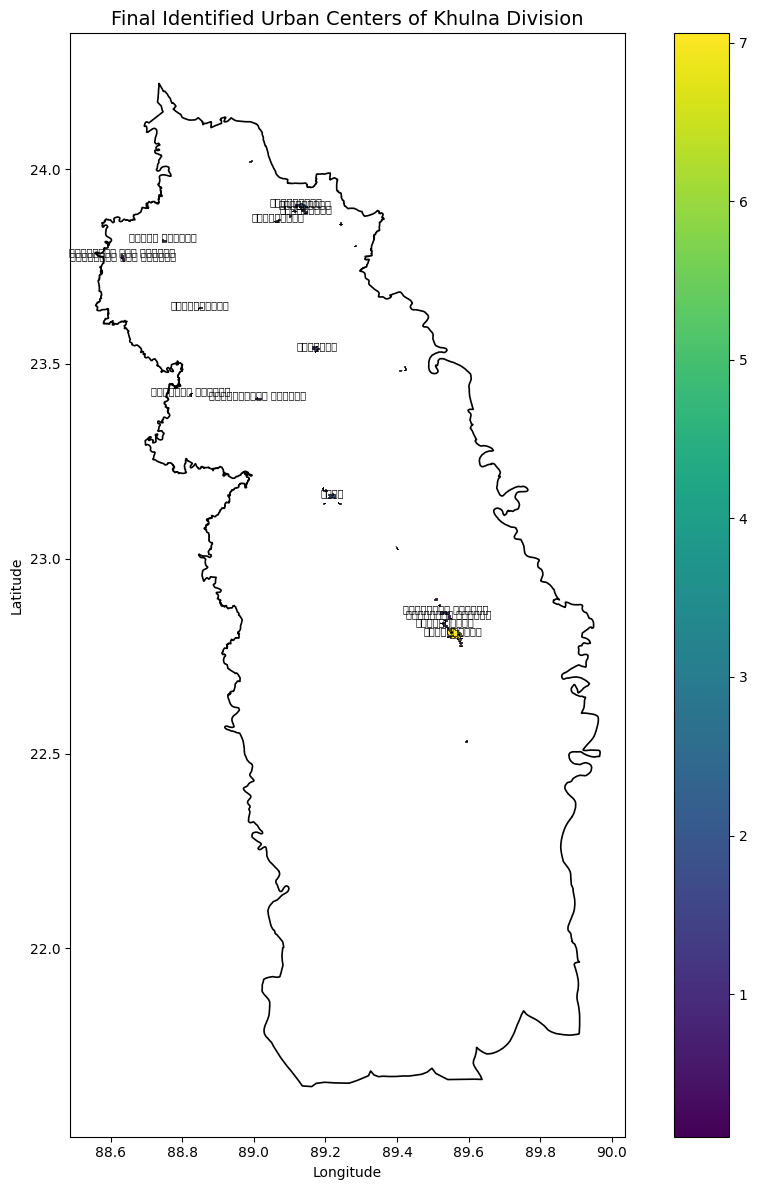


✅ Final map saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Urban_Centers_Map.png

✅ Final CSV saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_33_Urban_Centers_Table.csv

Shapefile components found:
 - Khulna_Final_33_Named_Urban_Centers.shp
 - Khulna_Final_33_Named_Urban_Centers.shx
 - Khulna_Final_33_Named_Urban_Centers.dbf
 - Khulna_Final_33_Named_Urban_Centers.cpg
 - Khulna_Final_33_Named_Urban_Centers.prj
 - Khulna_Final_33_Named_Urban_Centers.gpkg

FINAL PACKAGE
ZIP file:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_33_Urban_Centers/Khulna_Final_Urban_Centers_Package.zip
ZIP size: 0.26 MB

Included files:
 - Khulna_Final_33_Named_Urban_Centers.shp
 - Khulna_Final_33_Named_Urban_Centers.shx
 - Khulna_Final_33_Named_Urban_Centers.dbf
 - Khulna_Final_33_Named_Urban_Centers.cpg
 - Khulna_Final_33_Named_Urban_Centers.prj
 - Khulna_Final_33_Named_Urban_Centers.gpkg
 - Khulna_Final_33_Named_Urban_Centers.gpkg
 - 

/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'Khulna_Final_33_Named_Urban_Centers.gpkg'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
# ============================================================
# CELL 42 — FINAL MAP + ZIP + DOWNLOAD
# KHULNA FINAL 33 NAMED URBAN CENTERS
# ============================================================

import os
import glob
import zipfile
import geopandas as gpd
import matplotlib.pyplot as plt

from google.colab import files

print("=" * 70)
print("FINAL KHULNA URBAN CENTER OUTPUT PACKAGE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Input final named dataset
# ------------------------------------------------------------

FINAL_NAMED_GPKG = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers.gpkg"
)

final_named = gpd.read_file(
    FINAL_NAMED_GPKG,
    layer="urban_centers"
)

print("\nFinal centers :", len(final_named))
print("CRS           :", final_named.crs)

# ------------------------------------------------------------
# 2. Prepare map in WGS84
# ------------------------------------------------------------

final_map = final_named.to_crs("EPSG:4326")

# Khulna division boundary
khulna_map = khulna_wgs84.copy()

# ------------------------------------------------------------
# 3. Create final map
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 12)
)

# Division boundary
khulna_map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

# Urban centers
final_map.plot(
    ax=ax,
    column="area_km2",
    legend=True,
    edgecolor="black",
    linewidth=0.5
)

# Label larger centers only to avoid overcrowding
label_data = final_map[
    final_map["area_km2"] >= 0.30
].copy()

for _, row in label_data.iterrows():

    p = row.geometry.representative_point()

    ax.text(
        p.x,
        p.y,
        str(row["urban_name"]),
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "Final Identified Urban Centers of Khulna Division",
    fontsize=14
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save map
# ------------------------------------------------------------

MAP_FILE = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Centers_Map.png"
)

plt.savefig(
    MAP_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Final map saved:")
print(MAP_FILE)

# ------------------------------------------------------------
# 5. Save final CSV table
# ------------------------------------------------------------

FINAL_CSV = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Centers_Table.csv"
)

final_named.drop(
    columns="geometry"
).to_csv(
    FINAL_CSV,
    index=False
)

print("\n✅ Final CSV saved:")
print(FINAL_CSV)

# ------------------------------------------------------------
# 6. Collect shapefile components
# ------------------------------------------------------------

FINAL_SHP_BASE = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Named_Urban_Centers"
)

shp_components = glob.glob(
    FINAL_SHP_BASE + ".*"
)

print("\nShapefile components found:")
for f in shp_components:
    print(" -", os.path.basename(f))

# ------------------------------------------------------------
# 7. Create ZIP package
# ------------------------------------------------------------

ZIP_FILE = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_Urban_Centers_Package.zip"
)

files_to_zip = []

# Named shapefile components
files_to_zip.extend(
    shp_components
)

# GeoPackage
if os.path.exists(FINAL_NAMED_GPKG):
    files_to_zip.append(FINAL_NAMED_GPKG)

# Final CSV
if os.path.exists(FINAL_CSV):
    files_to_zip.append(FINAL_CSV)

# Final map
if os.path.exists(MAP_FILE):
    files_to_zip.append(MAP_FILE)

# Representative-point shapefile components
point_base = os.path.join(
    FINAL33_DIR,
    "Khulna_Final_33_Urban_Center_Points"
)

files_to_zip.extend(
    glob.glob(point_base + ".*")
)

# ------------------------------------------------------------
# 8. Write ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for file_path in files_to_zip:

        if os.path.isfile(file_path):

            z.write(
                file_path,
                arcname=os.path.basename(file_path)
            )

print("\n" + "=" * 70)
print("FINAL PACKAGE")
print("=" * 70)

print("ZIP file:")
print(ZIP_FILE)

print(
    "ZIP size:",
    round(
        os.path.getsize(ZIP_FILE)
        / (1024 * 1024),
        2
    ),
    "MB"
)

print("\nIncluded files:")

with zipfile.ZipFile(ZIP_FILE, "r") as z:
    for name in z.namelist():
        print(" -", name)

print("\n✅ FINAL KHULNA URBAN CENTER PACKAGE READY.")

# ------------------------------------------------------------
# 9. Direct download
# ------------------------------------------------------------

files.download(ZIP_FILE)

FINAL KHULNA OUTPUT GENERATION

Output folder:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_Outputs_Dhaka_Style

✅ Final Urban Score TIFF saved.
✅ Final Urban Center Mask TIFF saved.
✅ Corrected Urban Center Shapefile saved.
✅ Final Named Urban Center Shapefile saved.


/tmp/ipykernel_1142/154589325.py:271: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named_khulna.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(


✅ Final GeoPackage saved.
✅ Representative Point Shapefile saved.
✅ Final Urban Center Table CSV saved.


/tmp/ipykernel_1142/154589325.py:334: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  ].to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(
/tmp/ipykernel_1142/154589325.py:407: UserWarning: Glyph 2488 (\N{BENGALI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/154589325.py:407: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1142/154589325.py:407: UserWarning: Glyph 2507 (\N{BENGALI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/154589325.py:407: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1142/154589325.py:407: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layou

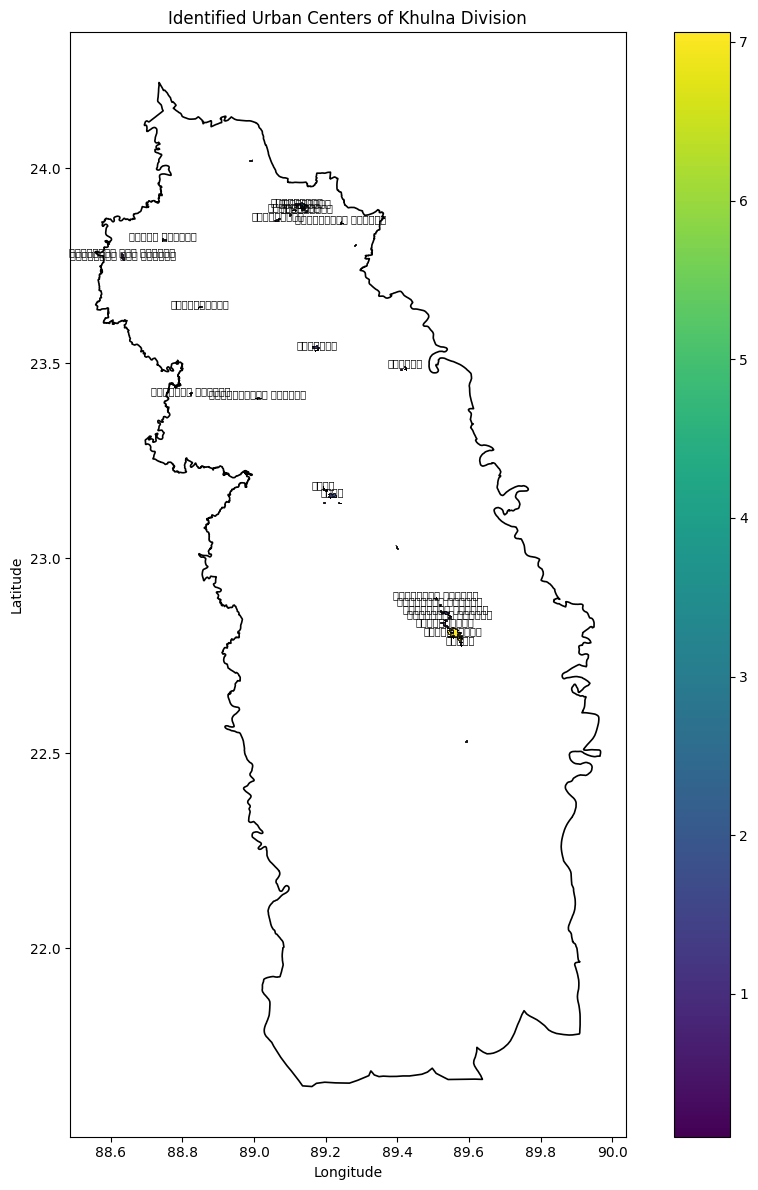

✅ Final map PNG saved.

FINAL KHULNA OUTPUT SUMMARY
Final threshold : 0.665988
Urban centers   : 33
Names filled    : 33
Total urban area: 22.11 km²
Largest center  : 7.06 km²
Median center   : 0.28 km²

Files created:
 - Khulna_Final_Urban_Score_100m.tif
 - Khulna_Final_Urban_Center_Mask_P92_5.tif
 - Khulna_Final_Urban_Centers_P92_5_FIXED.shp
 - Khulna_Final_Urban_Centers_P92_5_NAMED.shp
 - Khulna_Final_Urban_Centers_P92_5_NAMED.gpkg
 - Khulna_Urban_Center_Representative_Points.shp
 - Khulna_Final_Urban_Centers_Table.csv
 - Khulna_Final_Urban_Centers_Map.png

✅ ZIP package created:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_Outputs_Dhaka_Style/Khulna_Final_Urban_Center_All_Outputs.zip
ZIP size: 0.53 MB

✅ KHULNA FINAL OUTPUTS READY — same output types as Dhaka.


In [73]:
# ============================================================
# CELL 43 — FINAL KHULNA OUTPUTS
# Same final output types as Dhaka workflow
# ============================================================

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import shapes
from shapely.geometry import shape

print("=" * 70)
print("FINAL KHULNA OUTPUT GENERATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

OUTPUT_DIR_KHULNA = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Final_Outputs_Dhaka_Style"
)

os.makedirs(
    OUTPUT_DIR_KHULNA,
    exist_ok=True
)

print("\nOutput folder:")
print(OUTPUT_DIR_KHULNA)

# ------------------------------------------------------------
# 2. Save FINAL URBAN SCORE TIFF
# ------------------------------------------------------------

SCORE_TIF = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Score_100m.tif"
)

score_profile = {
    "driver": "GTiff",
    "height": urban_score_exact.shape[0],
    "width": urban_score_exact.shape[1],
    "count": 1,
    "dtype": "float32",
    "crs": ref_crs,
    "transform": ref_transform,
    "nodata": -9999,
    "compress": "lzw"
}

score_write = np.where(
    np.isfinite(urban_score_exact),
    urban_score_exact,
    -9999
).astype("float32")

with rasterio.open(
    SCORE_TIF,
    "w",
    **score_profile
) as dst:

    dst.write(
        score_write,
        1
    )

    dst.set_band_description(
        1,
        "Final_Urban_Score"
    )

print("\n✅ Final Urban Score TIFF saved.")

# ------------------------------------------------------------
# 3. Save FINAL URBAN MASK TIFF
# ------------------------------------------------------------

MASK_TIF = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Center_Mask_P92_5.tif"
)

mask_profile = score_profile.copy()

mask_profile.update(
    dtype="uint8",
    nodata=255
)

mask_write = final_mask_exact.astype("uint8")

mask_write_out = np.where(
    common_valid_exact,
    mask_write,
    255
).astype("uint8")

with rasterio.open(
    MASK_TIF,
    "w",
    **mask_profile
) as dst:

    dst.write(
        mask_write_out,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Center"
    )

print("✅ Final Urban Center Mask TIFF saved.")

# ------------------------------------------------------------
# 4. Build corrected 8-neighbour center polygons
# ------------------------------------------------------------

labels_clean = np.where(
    np.isin(
        labels_exact,
        keep_ids_exact
    ),
    labels_exact,
    0
).astype("int32")

records = []

for geom, value in shapes(
    labels_clean,
    mask=(labels_clean > 0),
    transform=ref_transform
):

    cid = int(value)

    if cid > 0:

        records.append({
            "component_id": cid,
            "geometry": shape(geom)
        })

parts_gdf = gpd.GeoDataFrame(
    records,
    crs="EPSG:6933"
)

urban_centers_fixed_khulna = (
    parts_gdf
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

urban_centers_fixed_khulna[
    "area_ha"
] = (
    urban_centers_fixed_khulna.geometry.area
    / 10000
)

urban_centers_fixed_khulna[
    "area_km2"
] = (
    urban_centers_fixed_khulna.geometry.area
    / 1e6
)

urban_centers_fixed_khulna = (
    urban_centers_fixed_khulna[
        urban_centers_fixed_khulna[
            "area_ha"
        ] >= 10
    ]
    .copy()
)

urban_centers_fixed_khulna = (
    urban_centers_fixed_khulna
    .sort_values(
        "area_ha",
        ascending=False
    )
    .reset_index(drop=True)
)

urban_centers_fixed_khulna[
    "center_id"
] = np.arange(
    1,
    len(urban_centers_fixed_khulna) + 1
)

# ------------------------------------------------------------
# 5. Save corrected polygon shapefile
# ------------------------------------------------------------

FIXED_SHP = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Centers_P92_5_FIXED.shp"
)

urban_centers_fixed_khulna[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    FIXED_SHP,
    driver="ESRI Shapefile"
)

print("✅ Corrected Urban Center Shapefile saved.")

# ------------------------------------------------------------
# 6. Add names
# ------------------------------------------------------------

final_named_khulna = (
    urban_centers_fixed_khulna
    .merge(
        name33_df[
            [
                "center_id",
                "urban_name",
                "district_name"
            ]
        ],
        on="center_id",
        how="left"
    )
)

final_named_khulna = final_named_khulna[
    [
        "center_id",
        "urban_name",
        "district_name",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 7. Save final NAMED shapefile
# ------------------------------------------------------------

NAMED_SHP = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Centers_P92_5_NAMED.shp"
)

final_named_khulna.to_file(
    NAMED_SHP,
    driver="ESRI Shapefile"
)

print("✅ Final Named Urban Center Shapefile saved.")

# ------------------------------------------------------------
# 8. Save GeoPackage
# ------------------------------------------------------------

NAMED_GPKG = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Centers_P92_5_NAMED.gpkg"
)

final_named_khulna.to_file(
    NAMED_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print("✅ Final GeoPackage saved.")

# ------------------------------------------------------------
# 9. Representative points
# ------------------------------------------------------------

points = final_named_khulna.copy()

points["geometry"] = (
    points.geometry
    .representative_point()
)

points = points.to_crs(
    "EPSG:4326"
)

points["longitude"] = (
    points.geometry.x
)

points["latitude"] = (
    points.geometry.y
)

POINT_SHP = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Urban_Center_Representative_Points.shp"
)

points[
    [
        "center_id",
        "urban_name",
        "district_name",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print("✅ Representative Point Shapefile saved.")

# ------------------------------------------------------------
# 10. Final CSV table
# ------------------------------------------------------------

CSV_FILE = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Centers_Table.csv"
)

final_named_khulna.drop(
    columns="geometry"
).to_csv(
    CSV_FILE,
    index=False
)

print("✅ Final Urban Center Table CSV saved.")

# ------------------------------------------------------------
# 11. Final map
# ------------------------------------------------------------

map_gdf = final_named_khulna.to_crs(
    "EPSG:4326"
)

fig, ax = plt.subplots(
    figsize=(10, 12)
)

khulna_wgs84.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

map_gdf.plot(
    ax=ax,
    column="area_km2",
    legend=True,
    edgecolor="black",
    linewidth=0.6
)

for _, row in map_gdf.iterrows():

    p = row.geometry.representative_point()

    if row["area_km2"] >= 0.20:

        ax.text(
            p.x,
            p.y,
            str(row["urban_name"]),
            fontsize=7,
            ha="center"
        )

ax.set_title(
    "Identified Urban Centers of Khulna Division"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

MAP_PNG = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Centers_Map.png"
)

plt.savefig(
    MAP_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Final map PNG saved.")

# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL KHULNA OUTPUT SUMMARY")
print("=" * 70)

print(
    "Final threshold :",
    round(FINAL_THRESHOLD_EXACT, 6)
)

print(
    "Urban centers   :",
    len(final_named_khulna)
)

print(
    "Names filled    :",
    final_named_khulna[
        "urban_name"
    ].notna().sum()
)

print(
    "Total urban area:",
    round(
        final_named_khulna[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center  :",
    round(
        final_named_khulna[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

print(
    "Median center   :",
    round(
        final_named_khulna[
            "area_km2"
        ].median(),
        2
    ),
    "km²"
)

print("\nFiles created:")

for f in [
    SCORE_TIF,
    MASK_TIF,
    FIXED_SHP,
    NAMED_SHP,
    NAMED_GPKG,
    POINT_SHP,
    CSV_FILE,
    MAP_PNG
]:
    print(" -", os.path.basename(f))

# ------------------------------------------------------------
# 13. ZIP all final outputs
# ------------------------------------------------------------

ZIP_FILE = os.path.join(
    OUTPUT_DIR_KHULNA,
    "Khulna_Final_Urban_Center_All_Outputs.zip"
)

files_to_zip = []

# All shapefile components
for base_name in [
    "Khulna_Final_Urban_Centers_P92_5_FIXED",
    "Khulna_Final_Urban_Centers_P92_5_NAMED",
    "Khulna_Urban_Center_Representative_Points"
]:

    files_to_zip.extend(
        glob.glob(
            os.path.join(
                OUTPUT_DIR_KHULNA,
                base_name + ".*"
            )
        )
    )

# Other final files
files_to_zip += [
    SCORE_TIF,
    MASK_TIF,
    NAMED_GPKG,
    CSV_FILE,
    MAP_PNG
]

files_to_zip = list(
    dict.fromkeys(files_to_zip)
)

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for fp in files_to_zip:

        if os.path.isfile(fp):

            z.write(
                fp,
                arcname=os.path.basename(fp)
            )

print("\n✅ ZIP package created:")
print(ZIP_FILE)

print(
    "ZIP size:",
    round(
        os.path.getsize(ZIP_FILE)
        / (1024 * 1024),
        2
    ),
    "MB"
)

print(
    "\n✅ KHULNA FINAL OUTPUTS READY — "
    "same output types as Dhaka."
)

In [74]:
# ============================================================
# CELL 44 — DHAKA vs KHULNA DIAGNOSTIC COMPARISON
# Compare final-score domain, threshold, patches, area
# ============================================================

import numpy as np
import pandas as pd
from scipy import ndimage

print("=" * 75)
print("DHAKA vs KHULNA — FINAL WORKFLOW DIAGNOSTIC")
print("=" * 75)

# ------------------------------------------------------------
# A. KHULNA CURRENT FINAL METHOD
# ------------------------------------------------------------

kh_valid_pixels = int(
    np.sum(np.isfinite(urban_score_exact))
)

kh_scores = urban_score_exact[
    np.isfinite(urban_score_exact)
]

kh_p925 = float(
    np.percentile(kh_scores, 92.5)
)

kh_candidate = (
    np.isfinite(urban_score_exact)
    & (urban_score_exact >= kh_p925)
)

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

kh_labels, kh_initial_components = ndimage.label(
    kh_candidate,
    structure=structure
)

kh_sizes = np.bincount(
    kh_labels.ravel()
)

if len(kh_sizes) > 0:
    kh_sizes[0] = 0

kh_keep = np.where(
    kh_sizes >= 10
)[0]

kh_clean = np.isin(
    kh_labels,
    kh_keep
)

kh_final_pixels = int(
    kh_clean.sum()
)

kh_final_area = (
    kh_final_pixels * 0.01
)

kh_final_components = len(
    kh_keep
)

# ------------------------------------------------------------
# B. DHAKA REFERENCE VALUES
# From your Dhaka notebook final workflow
# ------------------------------------------------------------
# Dhaka final threshold in notebook:
DHAKA_FINAL_THRESHOLD = 0.660545

# Final corrected center count from notebook:
DHAKA_FINAL_CENTERS = 55

# ------------------------------------------------------------
# Try to read Dhaka output raster if available in Drive
# ------------------------------------------------------------

import os
import glob
import rasterio

dhaka_score_files = glob.glob(
    "/content/drive/MyDrive/GEE_Dhaka_Urban/"
    "Final_Outputs/Dhaka_Final_Urban_Score_100m.tif"
)

dhaka_mask_files = glob.glob(
    "/content/drive/MyDrive/GEE_Dhaka_Urban/"
    "Final_Outputs/Dhaka_Final_Urban_Center_Mask_P92_5.tif"
)

dhaka_valid_pixels = None
dhaka_candidate_pixels = None
dhaka_final_pixels = None
dhaka_final_area = None

if len(dhaka_score_files) > 0:

    with rasterio.open(dhaka_score_files[0]) as src:

        dh_score = src.read(1).astype("float32")

        dh_nodata = src.nodata

        dh_valid = np.isfinite(dh_score)

        if dh_nodata is not None:
            dh_valid &= dh_score != dh_nodata

        dhaka_valid_pixels = int(
            dh_valid.sum()
        )

        dhaka_candidate_pixels = int(
            (
                dh_valid
                & (dh_score >= DHAKA_FINAL_THRESHOLD)
            ).sum()
        )

if len(dhaka_mask_files) > 0:

    with rasterio.open(dhaka_mask_files[0]) as src:

        dh_mask = src.read(1)

        dhaka_final_pixels = int(
            np.sum(dh_mask == 1)
        )

        dhaka_final_area = (
            dhaka_final_pixels * 0.01
        )

# ------------------------------------------------------------
# C. Comparison table
# ------------------------------------------------------------

rows = []

rows.append({
    "Metric": "Valid score pixels",
    "Dhaka": dhaka_valid_pixels,
    "Khulna": kh_valid_pixels
})

rows.append({
    "Metric": "P92.5 threshold",
    "Dhaka": DHAKA_FINAL_THRESHOLD,
    "Khulna": kh_p925
})

rows.append({
    "Metric": "Candidate pixels",
    "Dhaka": dhaka_candidate_pixels,
    "Khulna": int(kh_candidate.sum())
})

rows.append({
    "Metric": "Candidate area km2",
    "Dhaka": (
        dhaka_candidate_pixels * 0.01
        if dhaka_candidate_pixels is not None
        else None
    ),
    "Khulna": round(
        kh_candidate.sum() * 0.01,
        2
    )
})

rows.append({
    "Metric": "Final pixels after >=10 ha",
    "Dhaka": dhaka_final_pixels,
    "Khulna": kh_final_pixels
})

rows.append({
    "Metric": "Final urban area km2",
    "Dhaka": dhaka_final_area,
    "Khulna": kh_final_area
})

rows.append({
    "Metric": "Final urban centers",
    "Dhaka": DHAKA_FINAL_CENTERS,
    "Khulna": kh_final_components
})

comparison_df = pd.DataFrame(rows)

print("\n" + "=" * 75)
print("DHAKA vs KHULNA COMPARISON")
print("=" * 75)

display(comparison_df)

# ------------------------------------------------------------
# D. Additional Khulna diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("KHULNA DOMAIN CHECK")
print("=" * 75)

print(
    "Khulna total EPSG:6933 grid pixels :",
    data.shape[1] * data.shape[2]
)

print(
    "Khulna 6-factor valid pixels       :",
    int(valid.sum())
)

print(
    "Khulna raw built-up valid pixels   :",
    int(np.isfinite(builtup_raw_6933).sum())
)

print(
    "Khulna final score valid pixels    :",
    kh_valid_pixels
)

print(
    "Built-up-valid share of 6-factor domain:",
    round(
        np.isfinite(builtup_raw_6933).sum()
        / valid.sum()
        * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# E. Interpretation flags
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DIAGNOSTIC FLAGS")
print("=" * 75)

builtup_share = (
    np.isfinite(builtup_raw_6933).sum()
    / valid.sum()
    * 100
)

if builtup_share < 10:

    print(
        "⚠️ Raw built-up mask covers less than 10% "
        "of the Khulna valid domain."
    )

    print(
        "This means the final score is being calculated "
        "on a very restricted subset."
    )

else:

    print(
        "✅ Built-up valid-domain coverage is not unusually small."
    )

if dhaka_valid_pixels is None:
    print(
        "\n⚠️ Dhaka final score TIFF was not found in Drive."
    )
    print(
        "The table still shows the known Dhaka threshold "
        "and final center count."
    )

print("\n✅ Diagnostic comparison complete.")

DHAKA vs KHULNA — FINAL WORKFLOW DIAGNOSTIC

DHAKA vs KHULNA COMPARISON


,Metric,Dhaka,Khulna
0,Valid score pixels,443239.000000,33989.000000
1,P92.5 threshold,0.660545,0.665988
2,Candidate pixels,33243.000000,2550.000000
3,Candidate area km2,332.430000,25.500000
4,Final pixels after >=10 ha,32668.000000,2211.000000
5,Final urban area km2,326.680000,22.110000
6,Final urban centers,55.000000,33.000000



KHULNA DOMAIN CHECK


AttributeError: 'dict' object has no attribute 'shape'

In [75]:
# ============================================================
# CELL 44B — CHECK KHULNA BUILT-UP DATA LOSS
# ============================================================

import rasterio
import numpy as np

print("=" * 75)
print("KHULNA BUILT-UP DATA COVERAGE CHECK")
print("=" * 75)

RAW_BUILTUP = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_Builtup_Raw_Masked.tif"
)

REF_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

# ------------------------------------------------------------
# 1. Reference 100 m grid
# ------------------------------------------------------------

with rasterio.open(REF_TIF) as ref:

    ref_arr = ref.read()

    ref_valid = np.all(
        np.isfinite(ref_arr),
        axis=0
    )

    if ref.nodata is not None:
        ref_valid &= np.all(
            ref_arr != ref.nodata,
            axis=0
        )

    total_grid_pixels = (
        ref.height * ref.width
    )

print("\nREFERENCE GRID")
print("Total pixels       :", total_grid_pixels)
print("6-factor valid     :", int(ref_valid.sum()))
print("Valid area         :", round(ref_valid.sum() * 0.01, 2), "km²")

# ------------------------------------------------------------
# 2. Original exported raw built-up TIFF
# ------------------------------------------------------------

with rasterio.open(RAW_BUILTUP) as src:

    raw = src.read(1).astype("float32")

    print("\nRAW BUILT-UP EXPORT")
    print("CRS                :", src.crs)
    print("Shape              :", raw.shape)
    print("NoData             :", src.nodata)

    raw_finite = np.isfinite(raw)

    if src.nodata is not None:
        raw_finite &= raw != src.nodata

    print("Valid pixels       :", int(raw_finite.sum()))

    # Non-zero pixels also useful to inspect
    raw_nonzero = (
        raw_finite
        & (raw != 0)
    )

    print("Non-zero pixels    :", int(raw_nonzero.sum()))

# ------------------------------------------------------------
# 3. Reprojected raw built-up
# ------------------------------------------------------------

aligned_valid = np.isfinite(
    builtup_raw_6933
)

print("\nALIGNED BUILT-UP — EPSG:6933")
print("Valid pixels       :", int(aligned_valid.sum()))
print(
    "Equivalent area    :",
    round(aligned_valid.sum() * 0.01, 2),
    "km²"
)

# ------------------------------------------------------------
# 4. Coverage ratios
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COVERAGE RATIOS")
print("=" * 75)

print(
    "Built-up / 6-factor domain:",
    round(
        aligned_valid.sum()
        / ref_valid.sum()
        * 100,
        2
    ),
    "%"
)

print(
    "Expected earlier built-up search area:",
    "≈ 2801.40 km²"
)

print(
    "Current aligned built-up area:",
    round(
        aligned_valid.sum() * 0.01,
        2
    ),
    "km²"
)

print("\n✅ Coverage diagnostic complete.")

KHULNA BUILT-UP DATA COVERAGE CHECK

REFERENCE GRID
Total pixels       : 4131253
6-factor valid     : 2244164
Valid area         : 22441.64 km²

RAW BUILT-UP EXPORT
CRS                : EPSG:4326
Shape              : (2866, 1572)
NoData             : None
Valid pixels       : 306734
Non-zero pixels    : 306734

ALIGNED BUILT-UP — EPSG:6933
Valid pixels       : 33989
Equivalent area    : 339.89 km²

COVERAGE RATIOS
Built-up / 6-factor domain: 1.51 %
Expected earlier built-up search area: ≈ 2801.40 km²
Current aligned built-up area: 339.89 km²

✅ Coverage diagnostic complete.


In [76]:
# ============================================================
# CELL 45 — CORRECT FINAL KHULNA URBAN MASK
# Inside Khulna:
#   0 = Non-Urban
#   1 = Urban
# Outside Khulna:
#   255 = NoData
# ============================================================

import os
import numpy as np
import rasterio
from rasterio.features import rasterize

print("=" * 75)
print("CORRECT KHULNA FINAL URBAN / NON-URBAN MASK")
print("=" * 75)

# ------------------------------------------------------------
# 1. Reference grid
# ------------------------------------------------------------

REF_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Khulna_6_Factors_100m_EPSG6933.tif"
)

with rasterio.open(REF_TIF) as ref:
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_height = ref.height
    ref_width = ref.width

print("\nReference CRS :", ref_crs)
print("Grid         :", ref_height, "x", ref_width)
print("Resolution   :", (100, 100), "m")

# ------------------------------------------------------------
# 2. Rasterize Khulna Division boundary
# 1 = inside Khulna
# 0 = outside
# ------------------------------------------------------------

khulna_6933 = khulna_wgs84.to_crs(ref_crs)

boundary_mask = rasterize(
    [(geom, 1) for geom in khulna_6933.geometry],
    out_shape=(ref_height, ref_width),
    transform=ref_transform,
    fill=0,
    dtype="uint8"
)

inside_pixels = int((boundary_mask == 1).sum())

print("\nKhulna boundary pixels:", inside_pixels)
print(
    "Approx. boundary area:",
    round(inside_pixels * 0.01, 2),
    "km²"
)

# ------------------------------------------------------------
# 3. Create corrected output mask
# Start everything as NoData
# ------------------------------------------------------------

corrected_mask = np.full(
    (ref_height, ref_width),
    255,
    dtype="uint8"
)

# Entire Khulna Division = Non-Urban (0)
corrected_mask[
    boundary_mask == 1
] = 0

# Final urban pixels = Urban (1)
corrected_mask[
    (boundary_mask == 1)
    & final_mask_exact
] = 1

# ------------------------------------------------------------
# 4. Check counts
# ------------------------------------------------------------

nonurban_pixels = int(
    (corrected_mask == 0).sum()
)

urban_pixels = int(
    (corrected_mask == 1).sum()
)

nodata_pixels = int(
    (corrected_mask == 255).sum()
)

print("\n" + "=" * 75)
print("MASK PIXEL COUNTS")
print("=" * 75)

print("Non-Urban (0) :", nonurban_pixels)
print("Urban (1)     :", urban_pixels)
print("NoData (255)  :", nodata_pixels)

print(
    "\nUrban area:",
    round(urban_pixels * 0.01, 2),
    "km²"
)

print(
    "Non-Urban area:",
    round(nonurban_pixels * 0.01, 2),
    "km²"
)

# ------------------------------------------------------------
# 5. Save corrected TIFF
# ------------------------------------------------------------

CORRECTED_MASK_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Khulna_Urban/"
    "Final_Outputs_Dhaka_Style/"
    "Khulna_Final_Urban_Center_Mask_P92_5_CORRECTED.tif"
)

out_profile = ref_profile.copy()

out_profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="lzw"
)

with rasterio.open(
    CORRECTED_MASK_TIF,
    "w",
    **out_profile
) as dst:

    dst.write(
        corrected_mask,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Center_Mask"
    )

print("\n✅ Corrected mask saved:")
print(CORRECTED_MASK_TIF)

print("\nLegend:")
print("0   = Non-Urban")
print("1   = Urban")
print("255 = NoData / Outside Khulna Division")

print(
    "\n✅ Add THIS corrected TIFF in ArcMap."
)

CORRECT KHULNA FINAL URBAN / NON-URBAN MASK

Reference CRS : EPSG:6933
Grid         : 3031 x 1363
Resolution   : (100, 100) m

Khulna boundary pixels: 2258497
Approx. boundary area: 22584.97 km²

MASK PIXEL COUNTS
Non-Urban (0) : 2256286
Urban (1)     : 2211
NoData (255)  : 1872756

Urban area: 22.11 km²
Non-Urban area: 22562.86 km²

✅ Corrected mask saved:
/content/drive/MyDrive/GEE_Khulna_Urban/Final_Outputs_Dhaka_Style/Khulna_Final_Urban_Center_Mask_P92_5_CORRECTED.tif

Legend:
0   = Non-Urban
1   = Urban
255 = NoData / Outside Khulna Division

✅ Add THIS corrected TIFF in ArcMap.
